# Predicción de mora en tarjetas de crédito — Notebook del informe final

**Proyecto Final Integrador · Unidad N°9**  
Diplomado en Ciencia de Datos y Análisis Avanzado — Centro de e-Learning UTN BA

---

> **Qué es este notebook.** Es el respaldo técnico del **informe final**. Todo número del informe sale de una celda de acá: la penúltima celda guarda las figuras en `figuras/` y la última vuelca `resultados.json`, que es el archivo del que se redacta el informe. Nació como el baseline de la pre-entrega; el registro de cambios está al final, en el anexo.

**Cómo correrlo.** De arriba hacia abajo, sin intervención manual, tanto en VS Code/Jupyter local como en Google Colab. En local requiere el archivo `data/default of credit card clients.xls` (ver celda de carga); en Colab se descarga solo si falta. La corrida completa tarda unos minutos: lo más lento es el Random Forest de 6.3.

**Versiones.** Para obtener exactamente las cifras del informe hay que usar las versiones de `requirements.txt` (pandas 3.0.2, numpy 2.4.4, scikit-learn 1.8.0). Con otra versión de scikit-learn los números cambian levemente. En Colab, instalarlas con la línea comentada al comienzo del Bloque 1 y reiniciar el entorno antes de ejecutar.

**Semilla fija:** `SEED = 42` en todo el notebook, salvo las réplicas declaradas: semillas 0–19 del estimador de información mutua (5.3) y semillas 43–46 de la repetición del experimento (7.2bis).

### Mapa CRISP-DM

El notebook está ordenado por trazabilidad (ver la tabla siguiente), no por fase. Esta es la correspondencia con las fases de CRISP-DM:

| Fase CRISP-DM | Dónde está |
|---|---|
| 1. Comprensión del negocio | 3.1 (KPI y métricas), 3.3 (umbrales de éxito), 3.4 (benchmark de reglas de negocio). El caso de negocio completo está en el informe. |
| 2. Comprensión de los datos | 1 (carga y verificación de lo declarado), 2 (auditoría de calidad), 8 (fig. 1, EDA) |
| 3. Preparación de los datos | 4 (partición sin fuga de duplicados), 5 (análisis y decisiones de limpieza, sólo con train) |
| 4. Modelado | 6.1–6.2 (baseline logístico e hipótesis), 6.3 (comparación de algoritmos y elección del modelo final) |
| 5. Evaluación | 7.0–7.4 (holdout, KPI de negocio, estabilidad, sensibilidad, reproducibilidad), 7.5 (equidad), 7.6 y 7.6bis (interpretación y SHAP) |
| 6. Despliegue | Fuera del alcance (la consigna no lo exige). El plan de puesta en marcha, con prueba controlada y grupo testigo, está en el informe. |

### Orden deliberado (importa para la trazabilidad)

| Bloque | Qué hace | ¿Usa el target? |
|:---:|---|---|
| 1 | Carga y verificación estructural de lo declarado | No |
| 2 | Auditoría de calidad de datos | Sólo 2.4 (prevalencia global, descriptiva) |
| 3 | **Definición de métricas y esquema de validación** | No |
| 4 | Partición train / holdout | Sólo para estratificar |
| 5 | Análisis informado por el target y decisiones de limpieza | Sí — **sólo train** |
| 6 | Baselines, comparación de algoritmos y elección del modelo final (CV sobre train) | Sí — sólo train |
| 7 | Evaluación del modelo final sobre holdout, KPI de negocio, equidad e interpretación | Sí — holdout (7.6b: sólo train) |
| 8 | Figuras para el informe | Sólo lee resultados ya calculados |
| 9 | Volcado de `resultados.json` | No |

El bloque 3 va **antes** de cualquier modelado: métricas y validación quedan fijadas antes de entrenar.

El bloque 5 va **después** del split porque cualquier decisión tomada mirando el target sobre el total del dataset contamina el holdout. Por lo mismo, el algoritmo se elige en el bloque 6, sólo con train, y el holdout lo mide una sola vez en el bloque 7.

> **Salvedad.** La prevalencia del target del dataset completo aparece en 2.4 y en `RES["target"]` (5.3). Es descriptiva y no informa ninguna decisión de modelado.

---

## Bloque 0 — Chequeo de dependencias

Esta celda existe para que, si falta algo, el notebook falle **acá** con un mensaje claro y no tres bloques más adelante con un `ImportError` críptico.

> `xlrd` hace falta porque el archivo de UCI es un `.xls` de Excel 97-2003, no un CSV.

In [1]:
import importlib.util, sys
_falta = [m for m in ["pandas", "numpy", "sklearn", "xlrd", "matplotlib"]
          if importlib.util.find_spec(m) is None]
if _falta:
    _pip = {"sklearn": "scikit-learn"}
    raise SystemExit(
        "Faltan dependencias: " + ", ".join(_falta) + "\n"
        "Intérprete en uso: " + sys.executable + "\n"
        "Instalalas EN ESE intérprete, desde una celda del notebook:\n"
        "    %pip install " + " ".join(_pip.get(m, m) for m in _falta) + "\n"
        "(en VS Code o Colab, %pip instala en el kernel/runtime seleccionado; 'pip' a secas puede ir a otro intérprete)")
print("Dependencias OK |", sys.executable)

Dependencias OK | python


---

## Bloque 1 — Configuración, carga y verificación de lo declarado

In [2]:
# Librerías necesarias: pandas, numpy, scikit-learn, xlrd (lee el .xls de UCI) y matplotlib.
# Para obtener exactamente las cifras del informe, instalá estas versiones y reiniciá el entorno:
# %pip install pandas==3.0.2 numpy==2.4.4 scikit-learn==1.8.0 matplotlib==3.10.8 xlrd

import json, os, sys, hashlib, warnings, zipfile, time
from pathlib import Path
import numpy as np
import pandas as pd
import sklearn

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss
import matplotlib.pyplot as plt

# Se ocultan sólo los avisos de cambios futuros de las librerías (FutureWarning).
# Los demás avisos, como los de convergencia de la regresión logística, quedan a la vista.
warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
np.random.seed(SEED)

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 50)

def _en_colab():
    """True si el kernel es un runtime de Google Colab (a diferencia de VS Code o
    Jupyter local). Se usa para decidir cómo ubicar el proyecto y cómo conseguir el
    dataset: Colab sí tiene acceso de red a archive.ics.uci.edu, el otro entorno no."""
    return "google.colab" in sys.modules

# Todos los parámetros que el notebook usa para decidir, reunidos en un solo lugar.
CONFIG = {
    "SEED": SEED,
    "TEST_SIZE": 0.20,            # holdout estratificado
    "N_FOLDS": 5,                 # StratifiedKFold sobre train
    "CAPACIDAD_OPERATIVA": 0.20,  # [SUPUESTO S5] % de cartera gestionable por mes
    # Parámetros económicos del KPI. Son supuestos: hay que confirmarlos con el negocio.
    "S1_exposicion": "BILL_AMT1 (saldo del último resumen), truncado en 0 si es negativo",
    "S2_LGD": 0.60,               # [SUPUESTO S2] severidad de la pérdida dado el default
    "S3_efectividad": 0.20,       # [SUPUESTO S3] % de casos gestionados que se normalizan
    "S4_costo_contacto_NTD": 200, # [SUPUESTO S4] costo unitario de gestión preventiva
    # Escenarios de la prueba de sensibilidad (Bloque 7.3): el valor base de S2 y S3
    # declarado arriba, más un escenario pesimista y uno optimista de cada uno.
    "GRID_LGD": [0.40, 0.60, 0.80],
    "GRID_EFECTIVIDAD": [0.10, 0.20, 0.30],
    # La severidad (LGD) y la efectividad multiplican igual a las dos estrategias que se
    # comparan en 7.3: nunca cambian cuál gana, sólo por cuánto. Por eso también se varía
    # la capacidad operativa (S5): con otra capacidad cada estrategia elige otros clientes y
    # el ganador sí podría cambiar. 0,20 es el valor base; 0,10 y 0,30 son los escenarios
    # de capacidad chica y grande.
    "GRID_CAPACIDAD": [0.10, 0.20, 0.30],
    # Cantidad mínima de clientes para considerar confiable la tasa de mora de un código
    # de PAY_1; con menos casos la tasa es ruido (Bloque 5.2).
    "SOPORTE_MIN_FRAC_TRAIN": 0.01,  # define MIN_SOP = frac * len(train)
    "SOPORTE_MIN_ABS": 50,           # umbral laxo usado para "todos los códigos"
    # Elección del algoritmo (6.3): si uno más rápido de entrenar queda a menos de este
    # porcentaje del mejor en exposición capturada (en entrenamiento), gana el más rápido.
    "TOLERANCIA_ALGORITMO": 0.01,
    # Auditoría de equidad (7.5): los grupos con menos casos que este mínimo en el conjunto
    # de prueba se muestran, pero no entran en las brechas (su tasa sería ruido).
    "EQUIDAD_N_MIN": 100,
}

RES = {}  # reúne todos los números del informe (se guardan en resultados.json)
RES["entorno"] = {"python": sys.version.split()[0], "pandas": pd.__version__,
                  "numpy": np.__version__, "sklearn": sklearn.__version__,
                  "notebook_host": "colab" if _en_colab() else "vscode/jupyter local"}
RES["config"] = {k: v for k, v in CONFIG.items()}
print("Entorno:", RES["entorno"])

Entorno: {'python': '3.13.16', 'pandas': '3.0.2', 'numpy': '2.4.4', 'sklearn': '1.8.0', 'notebook_host': 'vscode/jupyter local'}


### 1.1 Carga del archivo

El dataset se consigue de dos formas según el entorno:

- **VS Code / Jupyter local**: no se descarga desde el notebook porque el acceso a `archive.ics.uci.edu` está bloqueado por la política de red de ese entorno de trabajo. El archivo se baja manualmente desde la página oficial del dataset y se deja en `data/`. Esto queda declarado en el PDF como una restricción de acceso, no como un problema de licencia: la licencia (CC BY 4.0) permite el uso, lo que falla es la ruta de red.
- **Google Colab**: sí tiene acceso de red. Si no encuentra el dataset en `data/` (ni en `/content/data/`), lo descarga automáticamente del repositorio oficial de UCI.

El loader acepta `.xls`, `.zip` o `.csv` para que el notebook corra sin tocar nada, sea cual sea el origen del archivo.

> **Hash.** El SHA-256 se calcula sobre el archivo de datos (`.xls`/`.csv`), no sobre el `.zip` que lo contiene, así que es el mismo en local y en Colab. Si el origen fue un `.zip`, su hash se guarda aparte en `sha256_zip`.

In [3]:
def _carpeta_base():
    """Dónde está el proyecto. No se asume el directorio de trabajo: VS Code puede abrir el
    kernel en la carpeta del notebook o en la raíz del workspace según la configuración, y
    Google Colab no tiene noción de "carpeta del proyecto" (filesystem efímero en /content).
    Se prueban las ubicaciones posibles de las tres formas de correr el notebook antes de
    rendirse."""
    cands = []
    _nb = globals().get("__vsc_ipynb_file__")      # lo define VS Code
    if _nb:
        cands.append(Path(_nb).resolve().parent)
    if _en_colab():
        cands.append(Path("/content"))
    cands += [Path.cwd(), Path.cwd().parent]
    for c in cands:
        if (c / "data").is_dir() and any((c / "data").iterdir()):
            return c
    if _en_colab():
        # En Colab no hay repositorio clonado ni datos subidos: se crea data/ en /content
        # y cargar() descarga el dataset desde UCI.
        base = Path("/content")
        (base / "data").mkdir(parents=True, exist_ok=True)
        return base
    raise FileNotFoundError(
        "No encontré la carpeta data/ con el dataset. Busqué en:\n  "
        + "\n  ".join(str(c / "data") for c in cands)
        + "\n\nBajá el .zip de\n"
          "  https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients\n"
          "y dejá 'default of credit card clients.xls' dentro de data/.")

BASE = _carpeta_base()
DATA_DIR = BASE / "data"
print("Carpeta del proyecto:", BASE)
COLS_ESPERADAS = (["ID", "LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE"]
                  + [f"PAY_{i}" for i in [0, 2, 3, 4, 5, 6]]
                  + [f"BILL_AMT{i}" for i in range(1, 7)]
                  + [f"PAY_AMT{i}" for i in range(1, 7)])

def _normalizar(df):
    df = df.copy()
    df.columns = [str(c).strip() for c in df.columns]
    ren = {c: "default" for c in df.columns
           if "default" in c.lower() and "month" in c.lower()}
    ren.update({c: "default" for c in df.columns if c.strip().upper() == "Y"})
    df = df.rename(columns=ren)
    return df

def _descargar_dataset(destino: Path) -> None:
    """Descarga el .zip oficial de UCI a destino/. Sólo se invoca en Colab: es el único de
    los dos entornos donde el acceso a archive.ics.uci.edu no está bloqueado."""
    import urllib.request
    url = "https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip"
    ruta_zip = destino / "default+of+credit+card+clients.zip"
    print(f"No hay dataset en {destino}. Descargando de UCI (una sola vez)...")
    urllib.request.urlretrieve(url, ruta_zip)

def cargar():
    """Devuelve (df, ruta, sha256). Acepta .xls, .zip o .csv en data/."""
    cands = (sorted(DATA_DIR.glob("*.xls")) + sorted(DATA_DIR.glob("*.xlsx"))
             + sorted(DATA_DIR.glob("*.zip")) + sorted(DATA_DIR.glob("*.csv")))
    if not cands and _en_colab():
        _descargar_dataset(DATA_DIR)
        cands = sorted(DATA_DIR.glob("*.zip"))
    if not cands:
        raise FileNotFoundError(
            f"La carpeta {DATA_DIR} existe pero no tiene ningún .xls, .zip ni .csv.")
    ruta = cands[0]
    global SHA_ZIP
    SHA_ZIP = None

    if ruta.suffix == ".zip":
        SHA_ZIP = hashlib.sha256(ruta.read_bytes()).hexdigest()
        with zipfile.ZipFile(ruta) as z:
            interno = [n for n in z.namelist() if n.lower().endswith((".xls", ".xlsx", ".csv"))][0]
            z.extract(interno, DATA_DIR)
            ruta = DATA_DIR / interno

    # La huella digital (hash) se calcula sobre el archivo de datos que realmente se lee
    # (.xls o .csv), no sobre el .zip, para que sea la misma en local y en Colab.
    sha = hashlib.sha256(ruta.read_bytes()).hexdigest()

    if ruta.suffix == ".csv":
        df = _normalizar(pd.read_csv(ruta))
        if "LIMIT_BAL" not in df.columns:
            df = _normalizar(pd.read_csv(ruta, header=1))
    else:
        # El .xls de UCI trae dos filas de encabezado: X1..X23 arriba, nombres abajo.
        try:
            df = _normalizar(pd.read_excel(ruta, header=1))
        except ImportError as e:
            raise ImportError("Falta 'xlrd' para leer .xls. Corré: %pip install xlrd") from e
        if "LIMIT_BAL" not in df.columns:
            df = _normalizar(pd.read_excel(ruta, header=0))
    return df, ruta, sha

df_raw, RUTA, SHA = cargar()
RES["fuente"] = {
    "archivo": RUTA.name,
    "sha256_12": SHA[:12],
    "sha256_full": SHA,
    "sha256_zip": SHA_ZIP,   # None si el origen no fue un .zip
    "bytes": os.path.getsize(RUTA),
    "origen": "UCI Machine Learning Repository, dataset 350 — Default of Credit Card Clients",
    "url": "https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients",
    "licencia": "CC BY 4.0",
    "cita": "Yeh, I-C. y Lien, C-H. (2009). Expert Systems with Applications 36(2), 2473-2480.",
}
print(RUTA.name, "|", RES["fuente"]["bytes"], "bytes | sha256:", SHA[:12])
df_raw.head(3)

Carpeta del proyecto: UTN-proyecto-final-integrador


default of credit card clients.xls | 5539328 bytes | sha256: 30c6be3abd8d


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0


### 1.2 Verificación de lo que declara la documentación

La documentación oficial declara **30.000 instancias**, **23 variables explicativas + 1 target** y **ningún valor faltante**. Nada de eso se da por cierto: se verifica contra el archivo.

In [4]:
ver = []
def chk(afirmacion, declarado, observado):
    ok = (str(declarado) == str(observado))
    ver.append({"afirmacion": afirmacion, "declarado": str(declarado),
                "observado": str(observado), "coincide": bool(ok)})
    return ok

n_filas, n_cols = df_raw.shape
chk("Cantidad de instancias", 30000, n_filas)
chk("Variables explicativas (sin ID ni target)", 23, n_cols - 2)
chk("Columnas totales en el archivo", 25, n_cols)
chk("Valores faltantes (NaN)", 0, int(df_raw.isna().sum().sum()))
chk("IDs duplicados", 0, int(df_raw["ID"].duplicated().sum()) if "ID" in df_raw else "s/ID")
chk("Nombres de columna esperados presentes", True,
    all(c in df_raw.columns for c in COLS_ESPERADAS))
_u = sorted(pd.unique(df_raw["default"]).tolist())
# Según cómo se lea el archivo, la variable a predecir puede venir con decimales. Se pasa
# a entero sólo si todos los valores son enteros; si no, se dejan como están y la
# verificación falla, que es lo correcto.
_u_norm = [int(v) for v in _u] if all(float(v).is_integer() for v in _u) else _u
chk("Target binario {0,1}", "[0, 1]", str(_u_norm))

# Los duplicados se controlan aparte: la documentación de UCI no dice que no haya
# duplicados, así que no corresponde contarlo como un error de la documentación.
# Es un control propio.
CONTROLES = [{"control": "Filas duplicadas exactas (ignorando ID)",
              "observado": int(df_raw.drop(columns=["ID"], errors="ignore").duplicated().sum()),
              "esperable_en_una_fuente_limpia": 0}]
RES["T_controles"] = CONTROLES

T_verificacion = pd.DataFrame(ver)
RES["T_verificacion"] = ver
RES["verificacion_fallidas"] = [v["afirmacion"] for v in ver if not v["coincide"]]
RES["n_filas"], RES["n_cols"] = int(n_filas), int(n_cols)
RES["n_nulos"] = int(df_raw.isna().sum().sum())
RES["n_duplicados"] = int(df_raw.drop(columns=["ID"], errors="ignore").duplicated().sum())
print("TABLA — Verificación de lo declarado por la documentación")
display(T_verificacion)
print("\nCONTROL PROPIO (no es una afirmación de la documentación):")
for c in CONTROLES:
    print(f"   {c['control']}: {c['observado']}")
if RES["verificacion_fallidas"]:
    print("\n!! NO se confirmaron:", "; ".join(RES["verificacion_fallidas"]))
    print("   Esto va al PDF como hallazgo, no se tapa.")
else:
    print("\nTodas las afirmaciones de la documentación se confirmaron contra el archivo.")

TABLA — Verificación de lo declarado por la documentación


,afirmacion,declarado,observado,coincide
0,Cantidad de instancias,30000,30000,True
1,Variables explicativas (sin ID ni target),23,23,True
2,Columnas totales en el archivo,25,25,True
3,Valores faltantes (NaN),0,0,True
4,IDs duplicados,0,0,True
5,Nombres de columna esperados presentes,True,True,True
6,"Target binario {0,1}","[0, 1]","[0, 1]",True



CONTROL PROPIO (no es una afirmación de la documentación):
   Filas duplicadas exactas (ignorando ID): 35

Todas las afirmaciones de la documentación se confirmaron contra el archivo.


### 1.3 `PAY_0` rompe la secuencia: verificación del orden temporal

Las columnas se llaman `PAY_0, PAY_2, PAY_3, PAY_4, PAY_5, PAY_6`: **no existe `PAY_1`**.

La documentación dice que `X6` (= `PAY_0`) es septiembre y `X11` (= `PAY_6`) es abril, de modo que `PAY_0` es el mes **más reciente** y alinea con `BILL_AMT1` / `PAY_AMT1`.

No lo damos por cierto por el nombre. Se verifica con evidencia estructural: si el orden temporal es el declarado, la correlación entre columnas del mismo bloque tiene que decaer de forma monótona con la distancia entre meses (estructura de banda). Se chequea en `BILL_AMT`, que es continua y donde el patrón es nítido.

> **Alcance de la prueba.** El decaimiento por lag confirma que las columnas forman una secuencia ordenada, pero no distingue su *sentido* (da lo mismo si el mes 1 es el más reciente o el más antiguo). El sentido sale de la documentación oficial y se corrobora, como evidencia más débil, comparando la asociación de `PAY_0` con `BILL_AMT1` frente a `BILL_AMT6`.

In [5]:
bill = df_raw[[f"BILL_AMT{i}" for i in range(1, 7)]]
Cb = bill.corr()
# Correlación promedio según la distancia en meses entre columnas
lags = {}
for d in range(1, 6):
    vals = [Cb.iloc[i, i + d] for i in range(6 - d)]
    lags[d] = float(np.mean(vals))
monotona = all(lags[d] > lags[d + 1] for d in range(1, 5))
RES["corr_bill_por_lag"] = {str(k): round(v, 4) for k, v in lags.items()}
RES["orden_temporal_monotono"] = bool(monotona)

print("Correlación media entre BILL_AMT por distancia de meses:")
for d, v in lags.items():
    print(f"  lag {d}: {v:.4f}")
print("\n¿Decae de forma monótona con el lag?", monotona)
if monotona:
    print("=> BILL_AMT1..6 forman una secuencia ordenada (el decaimiento por lag es monótono).")
else:
    print("!! El decaimiento por lag NO es monótono: el orden de BILL_AMT1..6 no queda verificado.")
print("   Ojo: el lag no distingue el SENTIDO (mes 1 = más reciente o más antiguo); el sentido")
print("   sale de la documentación (X6 = septiembre, X11 = abril).")

# Control cruzado: PAY_0 tiene que estar más relacionada con BILL_AMT1 (mismo mes) que con BILL_AMT6.
c1 = abs(df_raw["PAY_0"].corr(df_raw["BILL_AMT1"], method="spearman"))
c6 = abs(df_raw["PAY_0"].corr(df_raw["BILL_AMT6"], method="spearman"))
RES["pay0_vs_bill1"] = round(float(c1), 4)
RES["pay0_vs_bill6"] = round(float(c6), 4)
print(f"\n|rho(PAY_0, BILL_AMT1)| = {c1:.4f}   vs   |rho(PAY_0, BILL_AMT6)| = {c6:.4f}")
RES["pay0_alinea_con_bill1"] = bool(c1 > c6)
if c1 > c6:
    print("=> PAY_0 se asocia más con BILL_AMT1 que con BILL_AMT6: consistente con que sea el mes 1")
    print("   (septiembre). La diferencia es chica: es corroboración, no prueba.")
else:
    print("!! PAY_0 NO se asocia más con BILL_AMT1 que con BILL_AMT6: la corroboración falla y el")
    print("   renombre queda sostenido sólo por la documentación.")
print("   Se renombra a PAY_1 en el bloque 4 (sólo el nombre; ningún valor cambia).")

Correlación media entre BILL_AMT por distancia de meses:
  lag 1: 0.9380
  lag 2: 0.8924
  lag 3: 0.8578
  lag 4: 0.8307
  lag 5: 0.8027

¿Decae de forma monótona con el lag? True
=> BILL_AMT1..6 forman una secuencia ordenada (el decaimiento por lag es monótono).
   Ojo: el lag no distingue el SENTIDO (mes 1 = más reciente o más antiguo); el sentido
   sale de la documentación (X6 = septiembre, X11 = abril).

|rho(PAY_0, BILL_AMT1)| = 0.3146   vs   |rho(PAY_0, BILL_AMT6)| = 0.2891
=> PAY_0 se asocia más con BILL_AMT1 que con BILL_AMT6: consistente con que sea el mes 1
   (septiembre). La diferencia es chica: es corroboración, no prueba.
   Se renombra a PAY_1 en el bloque 4 (sólo el nombre; ningún valor cambia).


---

## Bloque 2 — Auditoría de calidad de datos

Ninguna de estas celdas toma decisiones a partir del target: describen la fuente, no modelan. Por eso corren sobre el dataset completo. **Única salvedad, descriptiva:** 2.4 informa la prevalencia global del target.

El dataset **no tiene nulos**. Quedarse en eso sería el error: los problemas de calidad de esta fuente son otros y están abajo.

### 2.1 Categorías fuera del diccionario oficial

In [6]:
DICC_OFICIAL = {
    "SEX":       {1: "masculino", 2: "femenino"},
    "EDUCATION": {1: "posgrado", 2: "universidad", 3: "secundaria", 4: "otros"},
    "MARRIAGE":  {1: "casado", 2: "soltero", 3: "otros"},
}

filas = []
for col, dicc in DICC_OFICIAL.items():
    vc = df_raw[col].value_counts().sort_index()
    for val, n in vc.items():
        filas.append({"variable": col, "codigo": int(val), "n": int(n),
                      "pct": round(100 * n / len(df_raw), 2),
                      "en_diccionario": int(val) in dicc,
                      "significado": dicc.get(int(val), "— NO DOCUMENTADO —")})
T_categorias = pd.DataFrame(filas)
RES["T_categorias"] = filas

fuera = T_categorias[~T_categorias["en_diccionario"]]
# Se cuentan clientes (filas), no códigos: un cliente con EDUCATION y MARRIAGE
# fuera del diccionario se cuenta una sola vez.
_mask_fuera = np.zeros(len(df_raw), dtype=bool)
for _col, _dicc in DICC_OFICIAL.items():
    _mask_fuera |= ~df_raw[_col].isin(list(_dicc.keys())).to_numpy()
RES["n_celdas_fuera_diccionario"] = int(fuera["n"].sum())
RES["n_fuera_diccionario"] = int(_mask_fuera.sum())
RES["pct_fuera_diccionario"] = round(100 * float(_mask_fuera.mean()), 2)

print("TABLA — Códigos observados vs. diccionario oficial")
display(T_categorias)
print(f"\nRegistros con al menos un código no documentado en EDUCATION/MARRIAGE: "
      f"{RES['n_fuera_diccionario']} ({RES['pct_fuera_diccionario']}% del total)")
if RES["n_celdas_fuera_diccionario"] != RES["n_fuera_diccionario"]:
    print(f"(la suma de conteos por código da {RES['n_celdas_fuera_diccionario']}: hay filas con "
          f"más de un código no documentado)")

TABLA — Códigos observados vs. diccionario oficial


,variable,codigo,n,pct,en_diccionario,significado
0,SEX,1,11888,39.63,True,masculino
1,SEX,2,18112,60.37,True,femenino
2,EDUCATION,0,14,0.05,False,— NO DOCUMENTADO —
3,EDUCATION,1,10585,35.28,True,posgrado
4,EDUCATION,2,14030,46.77,True,universidad
5,EDUCATION,3,4917,16.39,True,secundaria
6,EDUCATION,4,123,0.41,True,otros
7,EDUCATION,5,280,0.93,False,— NO DOCUMENTADO —
8,EDUCATION,6,51,0.17,False,— NO DOCUMENTADO —
9,MARRIAGE,0,54,0.18,False,— NO DOCUMENTADO —



Registros con al menos un código no documentado en EDUCATION/MARRIAGE: 399 (1.33% del total)


### 2.1bis Filas duplicadas exactas

La documentación no declara duplicados. Si aparecen, hay que decidir qué son antes de decidir qué hacer con ellos: dos clientes distintos con el mismo perfil inactivo no son un error de carga. El riesgo de que estas filas queden repartidas entre train y holdout se resuelve en el Bloque 4 (L10).

In [7]:
_sin_id = df_raw.drop(columns=["ID"])
_dup = _sin_id.duplicated(keep=False)
_MONTOS = [f"BILL_AMT{i}" for i in range(1, 7)] + [f"PAY_AMT{i}" for i in range(1, 7)]

RES["dup_n_filas"] = int(_dup.sum())
RES["dup_n_grupos"] = int(_sin_id[_dup].groupby(list(_sin_id.columns)).ngroups) if _dup.any() else 0
RES["dup_pct_montos_cero"] = (round(100 * float((df_raw.loc[_dup, _MONTOS] == 0)
                                                .all(axis=1).mean()), 1) if _dup.any() else 0.0)
RES["dup_n_filas_montos_no_cero"] = int((_dup & ~(df_raw[_MONTOS] == 0).all(axis=1)).sum()) if _dup.any() else 0
RES["dup_ids_distintos"] = bool(df_raw.loc[_dup, "ID"].nunique() == int(_dup.sum()))

print(f"Filas involucradas en algún duplicado exacto (sin ID): {RES['dup_n_filas']}")
print(f"Grupos de duplicados                                 : {RES['dup_n_grupos']}")
print(f"De esas filas, con TODOS los montos en cero          : {RES['dup_pct_montos_cero']}%")
print(f"De esas filas, con algún monto distinto de cero      : {RES['dup_n_filas_montos_no_cero']}")
print(f"Todas tienen ID distinto                             : {RES['dup_ids_distintos']}")
print("\nLectura: tienen ID propio y perfil idéntico; la mayoría son cuentas sin actividad en")
print("los seis meses. Las que repiten montos no nulos en los 12 campos NO se explican por")
print("inactividad y quedan señaladas para revisión (P7). Como no hay evidencia de error de")
print("carga, no se eliminan.")
print("Riesgo declarado: filas idénticas pueden caer en train y en holdout a la vez. El efecto")
print("no se midió: queda como decisión pendiente (P7).")

Filas involucradas en algún duplicado exacto (sin ID): 70
Grupos de duplicados                                 : 35
De esas filas, con TODOS los montos en cero          : 85.7%
De esas filas, con algún monto distinto de cero      : 10
Todas tienen ID distinto                             : True

Lectura: tienen ID propio y perfil idéntico; la mayoría son cuentas sin actividad en
los seis meses. Las que repiten montos no nulos en los 12 campos NO se explican por
inactividad y quedan señaladas para revisión (P7). Como no hay evidencia de error de
carga, no se eliminan.
Riesgo declarado: filas idénticas pueden caer en train y en holdout a la vez. El efecto
no se midió: queda como decisión pendiente (P7).


### 2.2 Códigos no documentados en las variables `PAY_*`

El diccionario oficial sólo documenta `-1` (pago puntual) y `1..9` (meses de atraso). Si aparecen `-2` y `0`, son códigos sin significado declarado y hay que explicitar el supuesto.

In [8]:
PAY_COLS_RAW = ["PAY_0"] + [f"PAY_{i}" for i in range(2, 7)]
tab_pay = (df_raw[PAY_COLS_RAW].apply(pd.Series.value_counts)
           .fillna(0).astype(int).sort_index())
tab_pay.index.name = "codigo"
documentados = set([-1] + list(range(1, 10)))
tab_pay["documentado"] = [i in documentados for i in tab_pay.index]

n_no_doc = int(tab_pay.loc[~tab_pay["documentado"], PAY_COLS_RAW].sum().sum())
n_celdas = len(df_raw) * len(PAY_COLS_RAW)
RES["T_pay_codigos"] = tab_pay.reset_index().to_dict("records")
RES["pct_pay_no_documentado"] = round(100 * n_no_doc / n_celdas, 2)
RES["codigos_pay_no_doc"] = sorted([int(i) for i in tab_pay.index[~tab_pay["documentado"]]])

print("TABLA — Frecuencia de códigos en PAY_* (6 columnas x 30.000 filas)")
display(tab_pay)
print(f"\nCódigos sin documentar: {RES['codigos_pay_no_doc']}")
print(f"Ocupan el {RES['pct_pay_no_documentado']}% de las {n_celdas:,} celdas PAY_*.")
if RES["pct_pay_no_documentado"] > 50:
    print("=> No es un caso marginal: es la mayoría de los datos de la familia más predictiva.")
else:
    print("=> Es una fracción minoritaria de las celdas, pero el supuesto igual hay que explicitarlo.")

TABLA — Frecuencia de códigos en PAY_* (6 columnas x 30.000 filas)


,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,documentado
codigo,,,,,,,
-2,2759,3782,4085,4348,4546,4895,False
-1,5686,6050,5938,5687,5539,5740,True
0,14737,15730,15764,16455,16947,16286,False
1,3688,28,4,2,0,0,True
2,2667,3927,3819,3159,2626,2766,True
3,322,326,240,180,178,184,True
4,76,99,76,69,84,49,True
5,26,25,21,35,17,13,True
6,11,12,23,5,4,19,True



Códigos sin documentar: [-2, 0]
Ocupan el 66.85% de las 180,000 celdas PAY_*.
=> No es un caso marginal: es la mayoría de los datos de la familia más predictiva.


### 2.3 Montos negativos y outliers

Criterio de outlier declarado **antes** de mirar: regla IQR (fuera de $[Q_1 - 1{,}5\,IQR,\; Q_3 + 1{,}5\,IQR]$). Se reporta además el percentil 99 y el máximo para dimensionar la cola.

> Los rangos resumen (`outliers_iqr_min/max`, `max_sobre_p99_*`) se calculan sólo sobre las **12 variables de monto**; `LIMIT_BAL` y `AGE` figuran en la tabla pero no entran en ese resumen.

In [9]:
MONTO_COLS = [f"BILL_AMT{i}" for i in range(1, 7)] + [f"PAY_AMT{i}" for i in range(1, 7)]
filas = []
for c in MONTO_COLS + ["LIMIT_BAL", "AGE"]:
    s = df_raw[c]
    q1, q3 = s.quantile(.25), s.quantile(.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    filas.append({
        "variable": c, "min": float(s.min()), "p50": float(s.median()),
        "p99": float(s.quantile(.99)), "max": float(s.max()),
        "n_negativos": int((s < 0).sum()),
        "n_outliers_iqr": int(((s < lo) | (s > hi)).sum()),
        "pct_outliers_iqr": round(100 * float(((s < lo) | (s > hi)).mean()), 2),
    })
T_outliers = pd.DataFrame(filas)
RES["T_outliers"] = filas
# Resumen de todas las variables de monto: mirar sólo BILL_AMT1 subestima los valores extremos.
_m = T_outliers[T_outliers["variable"].isin(MONTO_COLS)].copy()
_m["max_sobre_p99"] = _m["max"] / _m["p99"].replace(0, np.nan)
RES["outliers_iqr_min"] = round(float(_m["pct_outliers_iqr"].min()), 2)
RES["outliers_iqr_max"] = round(float(_m["pct_outliers_iqr"].max()), 2)
RES["max_sobre_p99_max"] = round(float(_m["max_sobre_p99"].max()), 1)
RES["max_sobre_p99_var"] = str(_m.loc[_m["max_sobre_p99"].idxmax(), "variable"])
RES["max_sobre_p99_min"] = round(float(_m["max_sobre_p99"].min()), 1)

neg_bill = int((df_raw[[f"BILL_AMT{i}" for i in range(1, 7)]] < 0).any(axis=1).sum())
RES["n_clientes_bill_negativo"] = neg_bill
RES["pct_clientes_bill_negativo"] = round(100 * neg_bill / len(df_raw), 2)
RES["max_bill_amt1"] = float(df_raw["BILL_AMT1"].max())
RES["p99_bill_amt1"] = float(df_raw["BILL_AMT1"].quantile(.99))
RES["ratio_max_p99_bill1"] = round(RES["max_bill_amt1"] / RES["p99_bill_amt1"], 1)

print("TABLA — Rango, negativos y outliers por regla IQR")
display(T_outliers)
print(f"\nClientes con algún BILL_AMT negativo (saldo a favor): {neg_bill} "
      f"({RES['pct_clientes_bill_negativo']}%)")
print(f"Cola derecha, sobre las {len(MONTO_COLS)} variables de monto:")
print(f"  outliers por IQR entre {RES['outliers_iqr_min']}% y {RES['outliers_iqr_max']}%")
print(f"  máximo / p99 entre {RES['max_sobre_p99_min']}x y {RES['max_sobre_p99_max']}x "
      f"(el peor caso es {RES['max_sobre_p99_var']})")
print(f"  Reportar sólo BILL_AMT1 ({RES['ratio_max_p99_bill1']}x) subestimaba la cola: el peor caso es "
      f"{RES['max_sobre_p99_max'] / RES['ratio_max_p99_bill1']:.1f} veces mayor.")
print("  La decisión P1 depende justamente de esto.")

TABLA — Rango, negativos y outliers por regla IQR


,variable,min,p50,p99,max,n_negativos,n_outliers_iqr,pct_outliers_iqr
0,BILL_AMT1,-165580.0,22381.5,350110.68,964511.0,590,2400,8.00
1,BILL_AMT2,-69777.0,21200.0,337495.28,983931.0,669,2395,7.98
2,BILL_AMT3,-157264.0,20088.5,325030.39,1664089.0,655,2469,8.23
3,BILL_AMT4,-170000.0,19052.0,304997.27,891586.0,675,2622,8.74
4,BILL_AMT5,-81334.0,18104.5,285868.33,927171.0,655,2725,9.08
5,BILL_AMT6,-339603.0,17071.0,279505.06,961664.0,688,2693,8.98
6,PAY_AMT1,0.0,2100.0,66522.18,873552.0,0,2745,9.15
7,PAY_AMT2,0.0,2009.0,76651.02,1684259.0,0,2714,9.05
8,PAY_AMT3,0.0,1800.0,70000.00,896040.0,0,2598,8.66
9,PAY_AMT4,0.0,1500.0,67054.44,621000.0,0,2994,9.98



Clientes con algún BILL_AMT negativo (saldo a favor): 1930 (6.43%)
Cola derecha, sobre las 12 variables de monto:
  outliers por IQR entre 7.98% y 9.98%
  máximo / p99 entre 2.8x y 22.0x (el peor caso es PAY_AMT2)
  Reportar sólo BILL_AMT1 (2.8x) subestimaba la cola: el peor caso es 7.9 veces mayor.
  La decisión P1 depende justamente de esto.


### 2.4 Desbalance de clases y por qué se descarta *accuracy*

In [10]:
prev = float(df_raw["default"].mean())
RES["prevalencia"] = round(prev, 4)
RES["pct_default"] = round(100 * prev, 2)
RES["n_default"] = int(df_raw["default"].sum())
RES["accuracy_clase_mayoritaria"] = round(100 * (1 - prev), 2)

print(f"Casos de default: {RES['n_default']:,} de {len(df_raw):,} => {RES['pct_default']}%")
print(f"\nUn clasificador que responda SIEMPRE 'no default' alcanza "
      f"{RES['accuracy_clase_mayoritaria']}% de accuracy")
print("y detecta CERO morosos. Por eso accuracy queda descartada como métrica de reporte.")

Casos de default: 6,636 de 30,000 => 22.12%

Un clasificador que responda SIEMPRE 'no default' alcanza 77.88% de accuracy
y detecta CERO morosos. Por eso accuracy queda descartada como métrica de reporte.


---

## Bloque 3 — Métricas y esquema de validación

> **Este bloque se define antes de entrenar nada.** Es el ítem del checklist de la consigna que exige que métricas y validación estén fijadas *antes* del modelado.

### 3.1 Métricas a reportar

| Métrica | Por qué |
|---|---|
| **PR-AUC (average precision)** — *primaria* | Con 22% de positivos y costo asimétrico, es la que responde a la pregunta operativa: de los que priorizo, cuántos son realmente morosos. El azar equivale a la prevalencia, así que el piso de comparación es explícito. |
| **ROC-AUC** — secundaria | Comparable con la literatura del dataset. Se reporta pero no decide. |
| **Recall @ capacidad** (top 20%) | Traduce el modelo a la operación real: con el equipo que hay, qué fracción de la mora alcanzo a tocar. |
| **Precision @ capacidad** | Costo de la campaña: cuántos contactos se gastan en clientes que no iban a caer. |
| **Lift @ capacidad** | Cuánto mejor que gestionar al azar. Es lo que entiende el área de negocio. |
| **F1 @ capacidad** | Se reporta porque es una métrica estándar, pero **no decide**: pondera igual precisión y recall, y acá un moroso no detectado y un contacto de más no cuestan lo mismo. Además, a capacidad fija (K constante) F1 = 2·TP / (K + positivos), así que ordena las estrategias exactamente igual que el recall: no agrega información de decisión. |
| **Brier score** | El KPI monetario multiplica probabilidad × exposición. Si las probabilidades no están calibradas, el KPI miente aunque el ranking sea bueno. |
| ~~Accuracy~~ | **Descartada.** Justificación numérica en la celda 2.4. |

### 3.2 Esquema de validación

1. **Holdout estratificado 80/20**, `random_state=42`. Se aparta al inicio y no se usa hasta el Bloque 7.
2. Sobre el 80% de train: **`StratifiedKFold` de 5 pliegues**, misma semilla, para estimar desempeño y comparar variantes **y algoritmos** (6.3).
3. **Todo el preprocesamiento va dentro de un `Pipeline`** (imputación, encoding, escalado), de modo que se ajusta con el train de cada pliegue y nunca ve el fold de validación. Escalar antes de partir sería fuga.
4. Las decisiones de limpieza que miran el target (bloque 5) se toman **sobre train**.

**Por qué split aleatorio estratificado y no temporal.** El dataset es un corte transversal: una fila por cliente, con seis meses de historia comprimidos en columnas y un único target (default del mes siguiente). No hay varias observaciones del mismo cliente ni una fecha por fila, así que no existe un eje temporal sobre el cual partir. Se verifica que no haya IDs repetidos (celda 1.2) para descartar filas correlacionadas entre particiones.

> **Esto es una limitación, no una virtud**, y entra como tal al documento: en producción la validación debería ser temporal (entrenar con cohortes viejas, validar con cohortes nuevas) y con estos datos eso no se puede simular.

### 3.3 Umbrales de éxito

Fijados ahora, antes de ver ningún resultado. Aplican al **modelo final del proyecto**, no al baseline: el baseline sirve para saber desde dónde se parte.

| # | Umbral | Cómo se mide |
|:---:|---|---|
| U0 † | La exposición capturada supera a la mejor regla en **≥ 10%** | Holdout |
| U1 | El modelo supera a la mejor regla de negocio en **recall @ 20%** por **≥ 10 puntos porcentuales absolutos** | Holdout |
| U2 | **PR-AUC ≥ 0,55** (el piso del azar es la prevalencia, ~0,22) | CV 5-fold sobre train |
| U3 | **Lift @ 20% ≥ 2,0**: el decil priorizado concentra al menos el doble de mora que el azar | Holdout |
| U4 † | El KPI de negocio (pérdida esperada evitada neta) es **positivo y superior** al de la mejor regla evaluada, a igual capacidad | Holdout |
| U5 † | Excluir **todas las demográficas** cuesta **< 0,01 de PR-AUC**: si se cumple, se excluyen sin discusión | CV 5-fold |

> **† Nota de trazabilidad.** En la definición original de este bloque figuraban U1 a U5. U0 no estaba y aparece recién en el bloque 7; U4 hablaba de la regla *vigente* (B1) y el código lo compara contra la *mejor regla evaluada* (B2), que es más exigente; U5 sólo contemplaba `SEX` y el código lo evalúa sobre las cuatro demográficas (6.2). Se listan así para que la definición y el código coincidan.

### 3.4 Benchmark de negocio

No se compara contra "nada": se compara contra lo que un área de cobranzas hace hoy sin modelo.

- **B0 — Azar**: gestionar 20% de la cartera al azar. Por construcción captura 20% de la mora (lift 1,0).
- **B1 — Regla de atraso vigente**: priorizar a quien ya registra atraso el último mes (`PAY_1 ≥ 1`), desempatando por saldo. Es la heurística estándar de cobranzas preventivas.
- **B2 — Regla de exposición**: priorizar por mayor saldo (`BILL_AMT1`). También es práctica común.

> **B1 es el benchmark que hay que vencer.** Si el modelo no le gana, el proyecto no se justifica.

---

## Bloque 4 — Partición train / holdout

> El split es a nivel de **grupo de duplicados exactos** (2.1bis), no de fila: los pares
> detectados se mantienen enteros de un mismo lado, para que ninguno quede partido entre
> train y holdout (L10, resuelve P7).

In [11]:
df = df_raw.copy()

# Se renombra PAY_0 a PAY_1 (verificado en 1.3). Sólo cambia el nombre, no los valores.
df = df.rename(columns={"PAY_0": "PAY_1"})
PAY_COLS = [f"PAY_{i}" for i in range(1, 7)]
BILL_COLS = [f"BILL_AMT{i}" for i in range(1, 7)]
PAYAMT_COLS = [f"PAY_AMT{i}" for i in range(1, 7)]

y = df["default"].astype(int)
X_all = df.drop(columns=["default"])

def split_sin_partir_duplicados(X, y_, df_full, test_size, seed):
    """Split estratificado que no reparte un duplicado exacto (2.1bis) entre train y
    holdout. Un split por fila puede poner las dos copias de un mismo perfil una de cada
    lado: el modelo prácticamente "ve" en validación una fila que ya vio en entrenamiento,
    lo que infla la métrica (P7, pedido explícito de la devolución del profesor). Se
    agrupan las filas por todas las columnas salvo ID -- el target queda incluido, así que
    cada grupo tiene un único valor de y -- y se particiona a nivel de grupo, no de fila.
    """
    cols = [c for c in df_full.columns if c != "ID"]
    grp = df_full.groupby(cols, sort=False).ngroup()
    y_grp = pd.Series(y_.values, index=grp.index).groupby(grp).first()
    grp_tr, grp_ho = train_test_split(y_grp.index.values, test_size=test_size,
                                       stratify=y_grp.values, random_state=seed)
    m_tr = grp.isin(grp_tr).values
    return X[m_tr], X[~m_tr], y_[m_tr], y_[~m_tr], grp

X_tr, X_ho, y_tr, y_ho, _grp_split = split_sin_partir_duplicados(
    X_all, y, df, CONFIG["TEST_SIZE"], SEED)

# Control P7: ningún grupo de filas duplicadas queda repartido entre entrenamiento y prueba.
# (Si la partición se hiciera fila por fila, con esta misma semilla quedarían 7 grupos repartidos.)
RES["dup_grupos_partidos_split"] = len(set(_grp_split[X_tr.index]) & set(_grp_split[X_ho.index]))
assert RES["dup_grupos_partidos_split"] == 0, "quedó un grupo de duplicados partido entre train y holdout"

RES["n_train"], RES["n_holdout"] = int(len(X_tr)), int(len(X_ho))
RES["prev_train"] = round(float(y_tr.mean()), 4)
RES["prev_holdout"] = round(float(y_ho.mean()), 4)
print(f"train   : {len(X_tr):,} filas | prevalencia {y_tr.mean():.4f}")
print(f"holdout : {len(X_ho):,} filas | prevalencia {y_ho.mean():.4f}")
print(f"Duplicados exactos partidos entre train y holdout: {RES['dup_grupos_partidos_split']} "
      f"(P7 resuelto; ver L10 en 5.4)")
print("\nA partir de acá y hasta el bloque 7, el holdout no se toca.")

train   : 23,998 filas | prevalencia 0.2212
holdout : 6,002 filas | prevalencia 0.2211
Duplicados exactos partidos entre train y holdout: 0 (P7 resuelto; ver L10 en 5.4)

A partir de acá y hasta el bloque 7, el holdout no se toca.


---

## Bloque 5 — Análisis informado por el target y decisiones de limpieza

Todo lo de este bloque se calcula **sólo sobre train**.

> Única salvedad, descriptiva: `RES["target"]` (celda 5.3) resume el target del dataset completo. No informa ninguna decisión.

### 5.1 ¿Las categorías no documentadas se comportan distinto?

La decisión entre *agrupar en "otros"* y *tratar como faltante encubierto* no se toma por gusto: se mira la tasa de default de cada código sobre train. Si los códigos sin documentar se parecen a la categoría "otros" ya existente, agruparlos no pierde información.

> **Alcance.** El baseline excluye todas las demográficas (L5), así que esta decisión sólo entra en las variantes de H1 y H4 (6.2).

In [12]:
tr = X_tr.copy(); tr["default"] = y_tr.values
filas = []
for col in ["EDUCATION", "MARRIAGE", "SEX"]:
    g = tr.groupby(col)["default"].agg(["size", "mean"])
    for val, r in g.iterrows():
        filas.append({"variable": col, "codigo": int(val), "n_train": int(r["size"]),
                      "tasa_default": round(float(r["mean"]), 4),
                      "documentado": int(val) in DICC_OFICIAL[col]})
T_tasa_cat = pd.DataFrame(filas)
RES["T_tasa_categorias"] = filas
print("TABLA — Tasa de default por código (TRAIN)")
display(T_tasa_cat)

# REGLA FIJADA ANTES DE MIRAR LOS RESULTADOS.
# Un código no documentado se suma a "otros" sólo si se comporta como "otros". Si se
# comporta distinto, queda como categoría propia: probablemente es un dato faltante
# disfrazado, y mezclarlo con "otros" haría perder esa información.
# Criterio concreto: se agrupa cuando el intervalo de confianza del 95% de la diferencia
# de tasas de mora (código no documentado menos "otros") incluye el 0, es decir, cuando
# no hay evidencia de que sean distintos. Así decide la evidencia y no un umbral elegido
# a mano, y un código con pocos casos no puede parecer distinto por simple azar.
REGLA_AGRUPAR = {"criterio": "IC 95% de la diferencia de dos proporciones (código no documentado vs. 'otros') contiene 0",
                 "z": 1.96}

CODIGOS_NO_DOC = {"EDUCATION": {"otros": 4, "no_doc": [0, 5, 6]},
                  "MARRIAGE":  {"otros": 3, "no_doc": [0]}}

decisiones_cat, filas = {}, []
for col, cfg in CODIGOS_NO_DOC.items():
    m = tr[col].isin(cfg["no_doc"])
    t_nodoc = float(tr.loc[m, "default"].mean())
    t_otros = float(tr.loc[tr[col] == cfg["otros"], "default"].mean())
    n = int(m.sum())
    n_otros = int((tr[col] == cfg["otros"]).sum())
    delta_pp = abs(t_nodoc - t_otros) * 100
    # Error estándar de la DIFERENCIA entre dos proporciones (código no documentado y "otros").
    # Hay que sumar la variación de los dos grupos: con la de uno solo, el intervalo saldría
    # más angosto de lo real y se tendería a no agrupar. En MARRIAGE ("otros" = 255 casos)
    # y EDUCATION (97 casos) esa diferencia importa.
    se = (((t_nodoc * (1 - t_nodoc) / n) + (t_otros * (1 - t_otros) / n_otros)) ** 0.5
          if n > 0 and n_otros > 0 else float("inf"))
    dif = t_nodoc - t_otros
    lo, hi = dif - REGLA_AGRUPAR["z"] * se, dif + REGLA_AGRUPAR["z"] * se   # intervalo de confianza del 95% de la diferencia
    agrupar = bool(lo <= 0 <= hi)         # si el intervalo incluye 0, no hay evidencia de diferencia: se agrupa
    decisiones_cat[col] = {"otros": cfg["otros"], "no_doc": cfg["no_doc"],
                           "agrupar": agrupar}
    filas.append({"variable": col, "codigos_no_doc": str(cfg["no_doc"]), "n_train": n,
                  "share_train_pct": round(100 * float(m.mean()), 2),
                  "tasa_no_doc": round(t_nodoc, 4),
                  "ic95_diferencia": f"[{lo:+.4f}, {hi:+.4f}]",
                  "tasa_otros": round(t_otros, 4), "delta_pp": round(delta_pp, 1),
                  "decision": "agrupar en 'otros'" if agrupar else "conservar separado"})

T_decision_cat = pd.DataFrame(filas)
RES["regla_agrupar"] = REGLA_AGRUPAR
RES["T_decision_cat"] = filas
RES["decisiones_cat"] = {k: v["agrupar"] for k, v in decisiones_cat.items()}

print("\nREGLA (declarada antes de ver los números):")
print("  agrupar el código no documentado dentro de 'otros' cuando NO hay evidencia de")
print("  que se comporte distinto, o sea cuando la diferencia de tasas (no_doc - otros)")
print("  no es significativa al 95% -- test de dos proporciones, con el error estándar")
print("  de AMBOS grupos, no sólo del código no documentado. Si es significativa, se")
print("  conserva aparte.\n")
display(T_decision_cat)
for col, d in decisiones_cat.items():
    print(f"  {col}: {'AGRUPAR' if d['agrupar'] else 'CONSERVAR SEPARADO'}")
print("\nQue dos variables reciban tratamiento distinto no es una inconsistencia:")
print("es la misma regla aplicada a datos que se comportan distinto.")

TABLA — Tasa de default por código (TRAIN)


,variable,codigo,n_train,tasa_default,documentado
0,EDUCATION,0,10,0.0000,False
1,EDUCATION,1,8493,0.1956,True
2,EDUCATION,2,11256,0.2361,True
3,EDUCATION,3,3871,0.2485,True
4,EDUCATION,4,90,0.0667,True
5,EDUCATION,5,235,0.0723,False
6,EDUCATION,6,43,0.1163,False
7,MARRIAGE,0,46,0.0870,False
8,MARRIAGE,1,10899,0.2332,True
9,MARRIAGE,2,12787,0.2106,True



REGLA (declarada antes de ver los números):
  agrupar el código no documentado dentro de 'otros' cuando NO hay evidencia de
  que se comporte distinto, o sea cuando la diferencia de tasas (no_doc - otros)
  no es significativa al 95% -- test de dos proporciones, con el error estándar
  de AMBOS grupos, no sólo del código no documentado. Si es significativa, se
  conserva aparte.



,variable,codigos_no_doc,n_train,share_train_pct,tasa_no_doc,ic95_diferencia,tasa_otros,delta_pp,decision
0,EDUCATION,"[0, 5, 6]",288,1.20,0.0764,"[-0.0503, +0.0697]",0.0667,1.0,agrupar en 'otros'
1,MARRIAGE,[0],46,0.19,0.0870,"[-0.2733, -0.0791]",0.2632,17.6,conservar separado


  EDUCATION: AGRUPAR
  MARRIAGE: CONSERVAR SEPARADO

Que dos variables reciban tratamiento distinto no es una inconsistencia:
es la misma regla aplicada a datos que se comportan distinto.


### 5.2 ¿El tratamiento ordinal de `PAY_*` es defendible?

En el baseline `PAY_*` se usa como numérica ordinal. Eso supone que el orden `-2 < -1 < 0 < 1 < ... < 9` es un orden de riesgo creciente. El supuesto se verifica: si la tasa de default crece de forma aproximadamente monótona con el código, el tratamiento ordinal está justificado; si no, hay que pasar a *one-hot*.

In [13]:
g = tr.groupby("PAY_1")["default"].agg(["size", "mean"]).rename(
    columns={"size": "n_train", "mean": "tasa_default"})
g["tasa_default"] = g["tasa_default"].round(4)
RES["T_tasa_pay1"] = g.reset_index().to_dict("records")
print("TABLA — Tasa de default por código de PAY_1 (TRAIN)")
display(g)

def _rho(t):
    return float(pd.Series(t.index).corr(pd.Series(t["tasa_default"].values), method="spearman"))

# Mínimo de casos: 1% del entrenamiento. Por debajo, la tasa observada es ruido y no sirve
# para confirmar ni descartar que la mora crezca con el atraso. Se muestran ambos resultados.
MIN_SOP = int(CONFIG["SOPORTE_MIN_FRAC_TRAIN"] * len(y_tr))
sub = g[g["n_train"] >= CONFIG["SOPORTE_MIN_ABS"]]
rho_todos = _rho(sub)
sop = g[g["n_train"] >= MIN_SOP]
rho_sop = _rho(sop[sop.index >= 0])
RES["min_soporte"] = MIN_SOP
RES["codigos_con_soporte"] = [int(i) for i in sop.index]
RES["spearman_pay1_tasa"] = round(rho_todos, 4)
RES["spearman_pay1_soporte"] = round(rho_sop, 4)

# La rareza puntual: ¿los que pagaron todo (-1) incumplen más que los que usan crédito rotativo (0)?
_t = g["tasa_default"]
RES["anomalia_pay_neg"] = bool(-1 in _t.index and 0 in _t.index and _t[-1] > _t[0])
RES["tasa_pay_m1"] = round(float(_t.get(-1, float("nan"))), 4)
RES["tasa_pay_0"] = round(float(_t.get(0, float("nan"))), 4)

print(f"\nSpearman con todos los códigos de n>=50                  : {rho_todos:.4f}")
print(f"Spearman en el tramo >=0 con soporte (n>={MIN_SOP})           : {rho_sop:.4f}")
print(f"Códigos que superan el soporte mínimo: {RES['codigos_con_soporte']}")
print(f"\nTasa de default: PAY_1 = -1 ('pagó puntual') -> {RES['tasa_pay_m1']:.4f}")
print(f"                 PAY_1 =  0 ('revolvente')    -> {RES['tasa_pay_0']:.4f}")
if RES["anomalia_pay_neg"]:
    print("\n!! La monotonía SE ROMPE en los códigos negativos: -1 tiene MÁS default que 0.")
    print("   El orden -2 < -1 < 0 que sugiere el diccionario no se verifica en los datos.")
    _n_cod_sop = int((sop.index >= 0).sum())
    print(f"   En el tramo con soporte suficiente (n>={MIN_SOP}) y código >= 0 el Spearman")
    print(f"   es {rho_sop:.2f}, pero sobre sólo {_n_cod_sop} códigos: con tan pocos puntos es una")
    print(f"   lectura gruesa. Los códigos de 4 en adelante tienen menos de {MIN_SOP} casos cada")
    print("   uno y su orden no es confiable.")
    print("   Decisión: se mantiene ordinal en el BASELINE (simple, y el grueso de la señal")
    print("   está en los códigos >= 1), pero con el supuesto declarado como NO cumplido")
    print("   para la parte negativa. El encoding definitivo queda PENDIENTE (P3), ahora")
    print("   con evidencia concreta de por qué hay que revisarlo.")
else:
    print("\nMonotonía creciente en todo el rango: el tratamiento ordinal queda justificado.")

TABLA — Tasa de default por código de PAY_1 (TRAIN)


,n_train,tasa_default
PAY_1,,
-2,2173,0.1321
-1,4530,0.1698
0,11820,0.1262
1,2966,0.3409
2,2144,0.6936
3,250,0.7720
4,62,0.6935
5,20,0.4500
6,10,0.5000



Spearman con todos los códigos de n>=50                  : 0.7857
Spearman en el tramo >=0 con soporte (n>=239)           : 1.0000
Códigos que superan el soporte mínimo: [-2, -1, 0, 1, 2, 3]

Tasa de default: PAY_1 = -1 ('pagó puntual') -> 0.1698
                 PAY_1 =  0 ('revolvente')    -> 0.1262

!! La monotonía SE ROMPE en los códigos negativos: -1 tiene MÁS default que 0.
   El orden -2 < -1 < 0 que sugiere el diccionario no se verifica en los datos.
   En el tramo con soporte suficiente (n>=239) y código >= 0 el Spearman
   es 1.00, pero sobre sólo 4 códigos: con tan pocos puntos es una
   lectura gruesa. Los códigos de 4 en adelante tienen menos de 239 casos cada
   uno y su orden no es confiable.
   Decisión: se mantiene ordinal en el BASELINE (simple, y el grueso de la señal
   está en los códigos >= 1), pero con el supuesto declarado como NO cumplido
   para la parte negativa. El encoding definitivo queda PENDIENTE (P3), ahora
   con evidencia concreta de por qué hay que 

### 5.3 Selección del diccionario de 10 variables principales

La consigna pide un *diccionario mínimo de las 10 variables principales*. "Principales" con criterio explícito, no a ojo:

1. Se calcula la **información mutua** de cada variable con el target **sobre train**.
2. Entra primero **la variable de mayor información mutua de cada una de las cuatro familias** del dataset (demográficas · límite de crédito · estado de pago · montos), para que el diccionario describa la fuente y no sólo su bloque más predictivo.
3. Se completa hasta diez por información mutua descendente.

`SEX` puede aparecer en el diccionario aunque esté excluida del modelo (L5): el diccionario describe **la fuente**, no el set de features.

> Por la regla 2, el diccionario **no** son las diez variables con mayor información mutua a secas: por ejemplo, `EDUCATION` entra por cobertura de familia.

In [14]:
FAMILIAS = {
    "demografica": ["SEX", "EDUCATION", "MARRIAGE", "AGE"],
    "limite": ["LIMIT_BAL"],
    "estado_pago": PAY_COLS,
    "montos": BILL_COLS + PAYAMT_COLS,
}
FEATS = [c for c in X_tr.columns if c != "ID"]
discretas = [c in (["SEX", "EDUCATION", "MARRIAGE"] + PAY_COLS) for c in FEATS]

# mutual_info_classif usa un método basado en vecinos cercanos que tiene su propio azar
# (aparte de la semilla de la partición): con una sola corrida, el orden de las variables
# podría deberse a ese azar y no a los datos. Por eso se repite con varias semillas y se
# informa el promedio y el desvío. Las variables discretas (PAY_*, SEX, EDUCATION,
# MARRIAGE) se calculan por conteo exacto y no varían; esto sólo afecta a las continuas.
N_SEMILLAS_MI = 20
_mi_runs = np.array([
    mutual_info_classif(X_tr[FEATS], y_tr, discrete_features=discretas, random_state=_s)
    for _s in range(N_SEMILLAS_MI)
])
mi = _mi_runs.mean(axis=0)
mi_std = _mi_runs.std(axis=0)
T_mi = (pd.DataFrame({"variable": FEATS, "info_mutua": np.round(mi, 5),
                      "info_mutua_std": np.round(mi_std, 5)})
        .sort_values("info_mutua", ascending=False).reset_index(drop=True))
T_mi["familia"] = T_mi["variable"].map(
    {v: f for f, vs in FAMILIAS.items() for v in vs})

sel = []
for fam in FAMILIAS:                 # 1) incluir la mejor variable de cada grupo
    sel.append(T_mi[T_mi["familia"] == fam].iloc[0]["variable"])
for v in T_mi["variable"]:           # 2) completar con las de mayor información mutua
    if len(sel) >= 10:
        break
    if v not in sel:
        sel.append(v)
DICC_10 = [v for v in T_mi["variable"] if v in sel]
assert len(DICC_10) == 10 and all(any(v in sel for v in vs) for vs in FAMILIAS.values())

# Pares de variables vecinas en el ranking cuya diferencia es menor que la suma de sus
# errores: su orden depende de la semilla usada y no de una diferencia real en los datos.
# Como se informa el promedio de N_SEMILLAS_MI corridas, su error es el desvío dividido
# por la raíz de N. Esto mide sólo el azar del método, no la variación de los datos.
T_mi["info_mutua_ee"] = (T_mi["info_mutua_std"] / np.sqrt(N_SEMILLAS_MI)).round(5)
_pares_inestables = []
for _i in range(len(T_mi) - 1):
    _a, _b = T_mi.iloc[_i], T_mi.iloc[_i + 1]
    if abs(_a["info_mutua"] - _b["info_mutua"]) < (_a["info_mutua_ee"] + _b["info_mutua_ee"]):
        _pares_inestables.append((_a["variable"], _b["variable"]))
RES["mi_pares_inestables"] = _pares_inestables

RES["T_mi"] = T_mi.to_dict("records")
# Tipo y rango observado de cada variable, para completar el diccionario.
RES["rangos"] = {c: {"tipo": ("entero" if pd.api.types.is_integer_dtype(X_all[c]) or
                              float(X_all[c].dropna().mod(1).abs().max() or 0) == 0 else "real"),
                     "min": float(X_all[c].min()), "max": float(X_all[c].max())}
                 for c in FEATS}
# Descripción del dataset COMPLETO: no se usa para ninguna decisión de modelado (ver Bloque 5).
RES["target"] = {"nombre": "default payment next month",
                 "descripcion": "1 = incumple el mes siguiente, 0 = no",
                 "positivos": int(y.sum()), "prevalencia": round(float(y.mean()), 4)}
RES["diccionario_10"] = DICC_10
RES["mi_top"] = float(T_mi.iloc[0]["info_mutua"])
print(f"TABLA — Información mutua con el target (TRAIN), media +/- std sobre {N_SEMILLAS_MI} semillas del estimador")
display(T_mi)
print("\n10 variables principales seleccionadas:", DICC_10)
if RES["mi_pares_inestables"]:
    print("Pares consecutivos cuyo orden NO es estable entre semillas del estimador:",
          RES["mi_pares_inestables"])
    print("(criterio: diferencia < suma de errores estándar de la media; mide sólo el ruido del estimador)")

TABLA — Información mutua con el target (TRAIN), media +/- std sobre 20 semillas del estimador


,variable,info_mutua,info_mutua_std,familia,info_mutua_ee
0,PAY_1,0.07737,0.00000,estado_pago,0.00000
1,PAY_2,0.04957,0.00000,estado_pago,0.00000
2,PAY_3,0.03756,0.00000,estado_pago,0.00000
3,PAY_4,0.03264,0.00000,estado_pago,0.00000
4,PAY_5,0.02964,0.00000,estado_pago,0.00000
5,PAY_6,0.02539,0.00000,estado_pago,0.00000
6,PAY_AMT1,0.02310,0.00141,montos,0.00032
7,PAY_AMT3,0.01823,0.00196,montos,0.00044
8,LIMIT_BAL,0.01627,0.00337,limite,0.00075
9,PAY_AMT2,0.01624,0.00162,montos,0.00036



10 variables principales seleccionadas: ['PAY_1', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'PAY_AMT1', 'PAY_AMT3', 'LIMIT_BAL', 'AGE']
Pares consecutivos cuyo orden NO es estable entre semillas del estimador: [('LIMIT_BAL', 'PAY_AMT2'), ('PAY_AMT2', 'PAY_AMT4'), ('AGE', 'BILL_AMT4'), ('BILL_AMT4', 'EDUCATION')]
(criterio: diferencia < suma de errores estándar de la media; mide sólo el ruido del estimador)


### 5.4 Decisiones de limpieza: tomadas vs. pendientes

Las **tomadas** están implementadas en la celda siguiente (L2 y L3 sólo entran en las variantes de H1/H4: el baseline no usa demográficas). Las **pendientes** están explicitadas y no se aplican todavía: aplicarlas sin evidencia comparativa sería decidir a ciegas.

In [15]:
# Cada decisión tiene una explicación larga (para leer acá) y una corta (la que va al
# informe, que tiene límite de páginas). Las dos dicen lo mismo.
# L2, L3 y L6 se escriben a partir de lo que decidieron 5.1 y 5.2: si cambian los datos,
# cambia el texto. Nunca se describe una decisión que no se tomó.
_D = {f["variable"]: f for f in RES["T_decision_cat"]}

def _c(x, dec=1):
    """Decimal con coma: el PDF está en español rioplatense."""
    return f"{float(x):.{dec}f}".replace(".", ",")

def _dec_txt(col):
    d = _D[col]
    return (f"{col}: códigos {d['codigos_no_doc']} agrupados en 'otros'" if decisiones_cat[col]["agrupar"]
            else f"{col}: código {d['codigos_no_doc']} conservado aparte")

def _dec_corta(col):
    d = _D[col]
    cods = d["codigos_no_doc"].strip("[]")
    return (f"{col} {cods} agrupados en 'otros': difieren {_c(d['delta_pp'])} pp (5.1)"
            if decisiones_cat[col]["agrupar"]
            else f"{col} {cods} conservado aparte: difiere {_c(d['delta_pp'])} pp de 'otros'")

def _dec_larga(col):
    """Corregido: antes describía un "umbral de 5 pp" que no existe en ningún lado del
    código -- la regla real (celda 5.1) es un IC 95% de la diferencia de dos
    proporciones (z=1.96), cuyo margen depende del tamaño de muestra de cada código,
    no un corte fijo. El texto ahora cita el IC realmente calculado, para que esta
    versión "larga" diga lo mismo que la "corta" (_dec_corta), como afirma el
    comentario de más arriba."""
    d = _D[col]
    base = (f"Códigos sin documentar, {d['share_train_pct']}% del train. Su tasa de default es "
            f"{d['tasa_no_doc']:.4f} contra {d['tasa_otros']:.4f} de la categoría 'otros': "
            f"{_c(d['delta_pp'])} puntos de diferencia. ")
    return base + (f"El IC 95% de la diferencia de tasas ({d['ic95_diferencia']}, test de dos "
                   f"proporciones, regla declarada en 5.1) CONTIENE el 0: no hay evidencia de que "
                   f"se comporten distinto, así que se absorben en 'otros' sin perder información."
                   if decisiones_cat[col]["agrupar"] else
                   f"El IC 95% de la diferencia de tasas ({d['ic95_diferencia']}) NO contiene el "
                   f"0: no se comportan como 'otros', así que se conservan como categoría propia. "
                   f"Fundirlos ahí borraría esa señal.")

def _pay_corta():
    return ("PAY_* ordinales: monótono en el tramo con soporte, no en los negativos"
            if RES["anomalia_pay_neg"] else
            "PAY_* como ordinales: monotonía código-riesgo verificada en 5.2")

def _pay_larga():
    if RES["anomalia_pay_neg"]:
        return (f"Spearman {RES['spearman_pay1_soporte']:.2f} en el tramo de códigos >= 0 con "
                f"soporte suficiente (n >= {RES['min_soporte']}), donde está el grueso de la "
                f"señal. Pero la monotonía SE ROMPE abajo: el código -1 "
                f"('pagó puntual') tiene tasa {RES['tasa_pay_m1']:.4f} contra "
                f"{RES['tasa_pay_0']:.4f} del código 0. El orden -2 < -1 < 0 que sugiere el "
                f"diccionario no se verifica. Se mantiene ordinal en el baseline por "
                f"simplicidad, con el supuesto declarado como NO cumplido en ese tramo; el "
                f"encoding definitivo queda en P3.")
    return (f"Monotonía código-riesgo verificada en 5.2 (Spearman "
            f"{RES['spearman_pay1_tasa']:.2f}).")

TOMADAS = [
    ("L1", "PAY_0 renombrada a PAY_1", "PAY_0 renombrada a PAY_1: restaura la secuencia, verificado en 1.3",
     "El nombre rompe la secuencia y es fuente de error al construir features de tendencia. "
     "Alineación con el mes 1 verificada en 1.3. No altera ningún valor."),
    ("L2", _dec_txt("EDUCATION"), _dec_corta("EDUCATION"), _dec_larga("EDUCATION")),
    ("L3", _dec_txt("MARRIAGE"), _dec_corta("MARRIAGE"), _dec_larga("MARRIAGE")),
    ("L4", "ID excluida del modelo", "ID fuera del modelo: identificador, correlación espuria con la carga",
     "Identificador administrativo. Correlación espuria con el orden de carga."),
    ("L5", "Todas las demográficas excluidas del modelo",
     "SEX, AGE, EDUCATION y MARRIAGE fuera del modelo: cuestan menos que U5",
     "SEX, AGE y MARRIAGE son atributos protegidos en scoring crediticio; EDUCATION es un "
     "proxy socioeconómico directo. Excluirlas todas cuesta menos de lo que el propio umbral "
     "U5 tolera (medido en 6.2). Se limpian igual a nivel dataset (L2, L3) porque siguen "
     "disponibles para auditar equidad aunque el modelo no las use."),
    ("L6", "PAY_* como numéricas ordinales", _pay_corta(), _pay_larga()),
    ("L7", "BILL_AMT negativos conservados", "BILL_AMT negativos conservados: saldo a favor, dato legítimo",
     "Son saldos a favor, comportamiento legítimo, no errores de carga. Eliminarlos o "
     "truncarlos destruiría información real."),
    ("L8", "Sin imputación de faltantes", "Sin imputación: no hay NaN (1.2), el imputador queda de salvaguarda",
     "El dataset no tiene NaN (1.2). El imputador queda igual dentro del Pipeline como "
     "salvaguarda para datos nuevos."),
    ("L9", "Filas duplicadas exactas conservadas",
     f"Duplicados exactos conservados: {RES['dup_n_grupos']} pares con ID propio (2.1bis)",
     f"Hay {RES['dup_n_filas']} filas idénticas ignorando ID, en {RES['dup_n_grupos']} grupos, "
     f"y el {RES['dup_pct_montos_cero']}% tiene todos los montos en cero: son cuentas sin "
     f"actividad. Las {RES['dup_n_filas_montos_no_cero']} restantes repiten montos no nulos en los "
     f"12 campos y no se explican por inactividad: quedan señaladas para revisión (P7). "
     f"Todas tienen ID propio y no hay evidencia de error de carga, así que se conservan."),
    ("L10", "Duplicados agrupados en el split train/holdout",
     f"Split agrupa duplicados: {RES['dup_grupos_partidos_split']} grupos partidos entre "
     f"train/holdout (antes 7, con split por fila)",
     f"Un split por fila puede poner las dos copias de un duplicado exacto una en train y otra "
     f"en holdout: el modelo evalúa en el holdout una fila que en la práctica ya vio en "
     f"entrenamiento, lo que infla la métrica. Con la partición semilla={SEED}, el split por "
     f"fila (versión anterior) dejaba 7 grupos partidos; agrupando por todas las columnas salvo "
     f"ID antes de particionar (Bloque 4) quedan {RES['dup_grupos_partidos_split']}."),
]
PENDIENTES = [
    ("P1", "Tratamiento de la cola derecha en montos", "Cola derecha en montos: winsorizar, log1p o dejar según el modelo",
     "Winsorizar al p99, transformar log1p con signo, o dejar crudo. Depende de la familia "
     "de modelos: la logística es sensible a la escala, los árboles no. Se decide al comparar."),
    ("P2", "Indicadora separada de saldo a favor", "Saldo a favor: evaluar si conviene desdoblar en binaria + magnitud",
     "Evaluar si conviene desdoblar BILL_AMT negativo en una binaria + magnitud."),
    ("P3", "Encoding definitivo de PAY_*", "Encoding de PAY_*: ordinal, one-hot o agrupado por tramo de atraso",
     "Ordinal vs. one-hot vs. agrupado en {sin consumo, al día, revolvente, atraso 1, atraso 2+}."),
    ("P4", "LIMIT_BAL como proxy residual",
     "LIMIT_BAL lo asignó el propio banco: puede cargar sesgo histórico",
     "Excluir las demográficas (L5) cierra la vía directa, pero el límite de crédito es una "
     "decisión previa del emisor y puede codificar sesgos pasados. Medir paridad de tasas de "
     "selección por grupo protegido excede esta etapa."),
    ("P5", "Features derivadas (utilización, ratio de pago)", "Features derivadas: fuera a propósito, el baseline debe ser un piso",
     "Utilización (BILL/LIMIT), ratio de pago (PAY_AMT/BILL_AMT), tendencia del atraso. "
     "Quedan fuera a propósito: el baseline tiene que ser simple para servir de piso."),
    ("P6", "Consistencia BILL_AMT = 0 con PAY_AMT > 0", "BILL_AMT=0 con PAY_AMT>0: ¿error de registro o cancelación total?",
     "Revisar si indica error de registro o cancelación total. No afecta al baseline."),
    ("P7", "Duplicados con montos no nulos: ¿mismo cliente o coincidencia?",
     "Duplicados con montos no nulos idénticos: confirmar si son el mismo cliente",
     f"De los {RES['dup_n_grupos']} grupos duplicados, {RES['dup_n_filas_montos_no_cero']} "
     f"filas repiten los 12 montos exactos y no se explican por inactividad (2.1bis). El "
     f"riesgo de que optimicen la métrica por fuga entre particiones ya lo resuelve L10; lo "
     f"que falta es de contenido: confirmar con el área de negocio si son el mismo cliente "
     f"con alta duplicada u otra causa."),
]
T_tomadas = pd.DataFrame(TOMADAS, columns=["id", "decision", "corta", "justificacion"])
T_pendientes = pd.DataFrame(PENDIENTES, columns=["id", "decision", "corta", "criterio_para_resolverla"])
RES["T_limpieza_tomadas"] = T_tomadas.to_dict("records")
RES["T_limpieza_pendientes"] = T_pendientes.to_dict("records")
print("TABLA — Decisiones de limpieza YA TOMADAS")
display(T_tomadas[["id", "decision", "justificacion"]])
print("TABLA — Decisiones de limpieza PENDIENTES")
display(T_pendientes[["id", "decision", "criterio_para_resolverla"]])

TABLA — Decisiones de limpieza YA TOMADAS


,id,decision,justificacion
0,L1,PAY_0 renombrada a PAY_1,El nombre rompe la secuencia y es fuente de er...
1,L2,"EDUCATION: códigos [0, 5, 6] agrupados en 'otros'","Códigos sin documentar, 1.2% del train. Su tas..."
2,L3,MARRIAGE: código [0] conservado aparte,"Códigos sin documentar, 0.19% del train. Su ta..."
3,L4,ID excluida del modelo,Identificador administrativo. Correlación espu...
4,L5,Todas las demográficas excluidas del modelo,"SEX, AGE y MARRIAGE son atributos protegidos e..."
5,L6,PAY_* como numéricas ordinales,Spearman 1.00 en el tramo de códigos >= 0 con ...
6,L7,BILL_AMT negativos conservados,"Son saldos a favor, comportamiento legítimo, n..."
7,L8,Sin imputación de faltantes,El dataset no tiene NaN (1.2). El imputador qu...
8,L9,Filas duplicadas exactas conservadas,"Hay 70 filas idénticas ignorando ID, en 35 gru..."
9,L10,Duplicados agrupados en el split train/holdout,Un split por fila puede poner las dos copias d...


TABLA — Decisiones de limpieza PENDIENTES


,id,decision,criterio_para_resolverla
0,P1,Tratamiento de la cola derecha en montos,"Winsorizar al p99, transformar log1p con signo..."
1,P2,Indicadora separada de saldo a favor,Evaluar si conviene desdoblar BILL_AMT negativ...
2,P3,Encoding definitivo de PAY_*,Ordinal vs. one-hot vs. agrupado en {sin consu...
3,P4,LIMIT_BAL como proxy residual,Excluir las demográficas (L5) cierra la vía di...
4,P5,"Features derivadas (utilización, ratio de pago)","Utilización (BILL/LIMIT), ratio de pago (PAY_A..."
5,P6,Consistencia BILL_AMT = 0 con PAY_AMT > 0,Revisar si indica error de registro o cancelac...
6,P7,Duplicados con montos no nulos: ¿mismo cliente...,"De los 35 grupos duplicados, 10 filas repiten ..."


In [16]:
def aplicar_limpieza(X, decisiones=decisiones_cat):
    """L2-L3. El mapeo sale de una regla fija evaluada SOBRE TRAIN (celda 5.1) y se
    aplica igual a train y a holdout: es el mismo patrón fit-en-train / transform-en-ambos
    que usa el Pipeline, así que no hay fuga."""
    X = X.copy()
    for col, d in decisiones.items():
        if d["agrupar"]:
            X[col] = X[col].replace({c: d["otros"] for c in d["no_doc"]})
    return X

X_tr_c, X_ho_c = aplicar_limpieza(X_tr), aplicar_limpieza(X_ho)
print("Limpieza aplicada. Códigos presentes después:")
print("  EDUCATION:", sorted(X_tr_c.EDUCATION.unique().tolist()))
print("  MARRIAGE :", sorted(X_tr_c.MARRIAGE.unique().tolist()))
print("\nLos códigos no documentados que sobreviven son los que la regla decidió conservar.")
print("En las variantes de H1/H4 (donde EDUCATION y MARRIAGE sí entran) el OneHotEncoder les da")
print("su propio nivel; el baseline las excluye (L5).")

Limpieza aplicada. Códigos presentes después:
  EDUCATION: [1, 2, 3, 4]
  MARRIAGE : [0, 1, 2, 3]

Los códigos no documentados que sobreviven son los que la regla decidió conservar.
En las variantes de H1/H4 (donde EDUCATION y MARRIAGE sí entran) el OneHotEncoder les da
su propio nivel; el baseline las excluye (L5).


---

## Bloque 6 — Baselines

Dos clases de baseline, las dos honestas:

- **Reglas de negocio** (B0/B1/B2): lo que se hace hoy sin modelo. No se entrenan.
- **Baseline de modelo**: regresión logística con preprocesamiento explícito dentro de un `Pipeline`. Sin tuneo de hiperparámetros, sin selección de variables, sin features derivadas. Es un piso, no un candidato.
- **Modelo final** (6.3): se comparan algoritmos con el mismo set de variables y los mismos pliegues; el ganador, elegido sólo con train, es el que pasa al Bloque 7.

In [17]:
# Variables del modelo base: sin el identificador (L4) y sin ninguna variable demográfica (L5).
# SEX, AGE y MARRIAGE son atributos protegidos en la evaluación de crédito, y EDUCATION
# funciona como indicador socioeconómico. Cuánto cuesta excluirlas se mide en 6.2.
DEMOGRAFICAS = ["SEX", "AGE", "EDUCATION", "MARRIAGE"]
NUM_COLS = ["LIMIT_BAL"] + BILL_COLS + PAYAMT_COLS + PAY_COLS
CAT_COLS = []
FEATS_BASE = NUM_COLS + CAT_COLS
assert not set(FEATS_BASE) & set(DEMOGRAFICAS + ["ID"])

def construir_pipeline(features_num, features_cat, seed=SEED):
    """Todo el preprocesamiento adentro: se ajusta con el train de cada fold."""
    trans = [("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                               ("sc", StandardScaler())]), features_num)]
    if features_cat:
        trans.append(("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                                       ("oh", OneHotEncoder(handle_unknown="ignore",
                                                            drop="first"))]), features_cat))
    return Pipeline([("pre", ColumnTransformer(trans, remainder="drop")),
                     ("clf", LogisticRegression(max_iter=2000, random_state=seed,
                                                class_weight=None))])

pipe = construir_pipeline(NUM_COLS, CAT_COLS)
print(pipe)

Pipeline(steps=[('pre',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('sc',
                                                                   StandardScaler())]),
                                                  ['LIMIT_BAL', 'BILL_AMT1',
                                                   'BILL_AMT2', 'BILL_AMT3',
                                                   'BILL_AMT4', 'BILL_AMT5',
                                                   'BILL_AMT6', 'PAY_AMT1',
                                                   'PAY_AMT2', 'PAY_AMT3',
                                                   'PAY_AMT4', 'PAY_AMT5',
                                                   'PAY_AMT6', 'PAY_1', 'PAY_2',
                                            

### 6.1 Validación cruzada sobre train (5 pliegues estratificados)

In [18]:
cv = StratifiedKFold(n_splits=CONFIG["N_FOLDS"], shuffle=True, random_state=SEED)
scoring = {"pr_auc": "average_precision", "roc_auc": "roc_auc",
           "brier": "neg_brier_score"}

cvres = cross_validate(pipe, X_tr_c[FEATS_BASE], y_tr, cv=cv, scoring=scoring, n_jobs=1)
RES["cv"] = {
    "pr_auc_mean": round(float(cvres["test_pr_auc"].mean()), 4),
    "pr_auc_std": round(float(cvres["test_pr_auc"].std()), 4),
    "roc_auc_mean": round(float(cvres["test_roc_auc"].mean()), 4),
    "roc_auc_std": round(float(cvres["test_roc_auc"].std()), 4),
    "brier_mean": round(float(-cvres["test_brier"].mean()), 4),
}
print(f"CV {CONFIG['N_FOLDS']}-fold sobre train ({len(X_tr):,} filas)")
print(f"  PR-AUC  : {RES['cv']['pr_auc_mean']:.4f} +/- {RES['cv']['pr_auc_std']:.4f}"
      f"   (piso del azar = prevalencia = {RES['prev_train']:.4f})")
print(f"  ROC-AUC : {RES['cv']['roc_auc_mean']:.4f} +/- {RES['cv']['roc_auc_std']:.4f}")
print(f"  Brier   : {RES['cv']['brier_mean']:.4f}")

CV 5-fold sobre train (23,998 filas)
  PR-AUC  : 0.5030 +/- 0.0147   (piso del azar = prevalencia = 0.2212)
  ROC-AUC : 0.7228 +/- 0.0136
  Brier   : 0.1454


### 6.2 Contraste de hipótesis H1, H3 y H4 (sobre CV, sin tocar el holdout)

- **H1**: el historial de pago predice más que las variables demográficas.
- **H2**: un modelo supera a la regla de atraso vigente (B1) en recall a capacidad fija. Se contrasta sobre el holdout, en 7.2bis.
- **H3**: las razones derivadas (utilización, ratio de pago) aportan sobre los montos crudos.
- **H4**: excluir **todas** las variables demográficas no degrada el desempeño (umbral U5: Δ < 0,01). Antes esta hipótesis miraba sólo `SEX`, lo que era incoherente: si el criterio para excluir un atributo protegido es que su aporte sea despreciable, hay que aplicarlo a `AGE` y `MARRIAGE` —también protegidos— y a `EDUCATION`, que es proxy socioeconómico.

In [19]:
def pr_auc_cv(fnum, fcat, X=None, yy=None):
    X = X_tr_c if X is None else X
    yy = y_tr if yy is None else yy
    p = construir_pipeline(fnum, fcat)
    r = cross_validate(p, X[fnum + fcat], yy, cv=cv, scoring="average_precision", n_jobs=1)
    return float(r["test_score"].mean())

h1_pago = pr_auc_cv(PAY_COLS, [])
# "Demográficas" son siempre las mismas 4 variables en todo el notebook: SEX, AGE,
# EDUCATION y MARRIAGE. Así H1 compara PAY_* contra el mismo grupo que usan L5 y H4.
h1_demo = pr_auc_cv(["AGE"], ["EDUCATION", "MARRIAGE", "SEX"])
con_demo = pr_auc_cv(NUM_COLS + ["AGE"], ["EDUCATION", "MARRIAGE", "SEX"])
sin_demo = RES["cv"]["pr_auc_mean"]

RES["H1"] = {"solo_pago": round(h1_pago, 4), "solo_demografica": round(h1_demo, 4),
             "se_sostiene": bool(h1_pago > h1_demo)}
RES["H4"] = {"con_demograficas": round(con_demo, 4), "sin_demograficas": round(sin_demo, 4),
             "delta": round(con_demo - sin_demo, 4),
             "cumple_U5": bool(abs(con_demo - sin_demo) < 0.01)}

print(f"H1  PR-AUC sólo PAY_*        : {h1_pago:.4f}")
print(f"    PR-AUC sólo demográficas : {h1_demo:.4f}   -> H1 se sostiene: {RES['H1']['se_sostiene']}")
print(f"\nH4  PR-AUC con las 4 demográficas : {con_demo:.4f}")
print(f"    PR-AUC sin ninguna               : {sin_demo:.4f}   delta = {con_demo - sin_demo:+.4f}")
print(f"    Umbral U5 (|delta| < 0,01) cumplido: {RES['H4']['cumple_U5']}")
if RES["H4"]["cumple_U5"]:
    print("    => Excluirlas cuesta menos de lo que el propio umbral tolera. La decisión L5")
    print("       queda respaldada con evidencia y la incoherencia anterior (sacar SEX pero")
    print("       dejar AGE, EDUCATION y MARRIAGE) queda cerrada.")
else:
    print("    => Excluirlas cuesta MÁS de lo que tolera U5: la decisión L5 NO queda respaldada")
    print("       y hay que revisarla.")

# H3: ¿las variables derivadas (proporciones) agregan información a los montos originales? Se mide.
def _derivadas(Xs):
    Xs = Xs.copy()
    _lim = Xs["LIMIT_BAL"].replace(0, np.nan)
    Xs["UTIL_1"] = Xs["BILL_AMT1"] / _lim
    Xs["UTIL_PROM"] = Xs[BILL_COLS].mean(axis=1) / _lim
    Xs["RATIO_PAGO"] = Xs["PAY_AMT1"] / Xs["BILL_AMT2"].replace(0, np.nan)
    Xs["MAX_ATRASO"] = Xs[PAY_COLS].max(axis=1)
    return Xs.replace([np.inf, -np.inf], np.nan)

DERIV = ["UTIL_1", "UTIL_PROM", "RATIO_PAGO", "MAX_ATRASO"]
X_tr_d = _derivadas(X_tr_c)
h3 = pr_auc_cv(NUM_COLS + DERIV, CAT_COLS, X_tr_d, y_tr)
RES["H3"] = {"sin_derivadas": round(sin_demo, 4), "con_derivadas": round(h3, 4),
             "delta": round(h3 - sin_demo, 4), "se_sostiene": bool(h3 - sin_demo > 0.01)}
print(f"\nH3  PR-AUC sin derivadas : {sin_demo:.4f}")
print(f"    PR-AUC con derivadas : {h3:.4f}   delta = {h3 - sin_demo:+.4f}")
print(f"    H3 se sostiene (delta > 0,01): {RES['H3']['se_sostiene']}")
if not RES["H3"]["se_sostiene"]:
    print("    => H3 NO se sostiene con un modelo lineal. Se reporta el resultado negativo")
    print("       en lugar de reformular la hipótesis para esquivarlo. Queda abierta para")
    print("       modelos no lineales, donde las razones pueden aportar de otra forma.")

H1  PR-AUC sólo PAY_*        : 0.4873
    PR-AUC sólo demográficas : 0.2543   -> H1 se sostiene: True

H4  PR-AUC con las 4 demográficas : 0.5032
    PR-AUC sin ninguna               : 0.5030   delta = +0.0002
    Umbral U5 (|delta| < 0,01) cumplido: True
    => Excluirlas cuesta menos de lo que el propio umbral tolera. La decisión L5
       queda respaldada con evidencia y la incoherencia anterior (sacar SEX pero
       dejar AGE, EDUCATION y MARRIAGE) queda cerrada.



H3  PR-AUC sin derivadas : 0.5030
    PR-AUC con derivadas : 0.5021   delta = -0.0009
    H3 se sostiene (delta > 0,01): False
    => H3 NO se sostiene con un modelo lineal. Se reporta el resultado negativo
       en lugar de reformular la hipótesis para esquivarlo. Queda abierta para
       modelos no lineales, donde las razones pueden aportar de otra forma.


### 6.3 Comparación de algoritmos y selección del modelo final (sólo train)

La consigna pide evaluar al menos dos algoritmos y justificar la elección. Se comparan tres, **en igualdad de condiciones**:

- **Mismo set de variables** que el baseline (`FEATS_BASE`: sin `ID` ni demográficas, L4-L5).
- **Mismos 5 pliegues** de 6.1: cada candidato predice cada fila de train con un modelo que no la vio (`cross_val_predict`).
- **Sin búsqueda de hiperparámetros.** Ninguno se tunea, igual que la logística de 6.1: se compara cada algoritmo con una configuración razonable fijada de antemano, no el resultado de una búsqueda. El tuneo queda como paso siguiente.

| Candidato | Por qué está |
|---|---|
| **Regresión logística** | El baseline de 6.1. Lineal e interpretable. |
| **Gradient boosting** (`HistGradientBoostingClassifier`) | Captura no linealidades e interacciones (por ejemplo, entre atraso y saldo) que la logística no puede. Viene con scikit-learn: no suma dependencias. Cumple el rol que la consigna sugiere para XGBoost. |
| **Random Forest** | El otro algoritmo que sugiere la consigna. Árboles en paralelo en lugar de en secuencia. |

**Criterio de selección, fijado antes de correr.** Gana el que captura más **exposición en mora a capacidad fija** (el KPI primario, ranking M1) sobre las predicciones fuera de muestra de train. Si un candidato **más barato de entrenar** queda a menos del 1% del mejor (`TOLERANCIA_ALGORITMO`), gana el más barato: una diferencia de ese tamaño no paga un modelo más pesado. El orden de costo es logística < gradient boosting < Random Forest. La PR-AUC se reporta al lado, pero no decide (el KPI en NT$ manda, como pidió la devolución del tutor). Las probabilidades se comparan **sin calibrar** en los tres: la decisión de calibrar se toma después, en 7.0, para el ganador.

El holdout **no se toca**: el algoritmo queda fijado acá y el Bloque 7 lo evalúa una sola vez.

In [20]:
# Algoritmos candidatos, de más rápido a más lento de entrenar (el orden se usa para
# desempatar). Los dos modelos de árboles van en un Pipeline de un solo paso, igual que la
# logística, pero no necesitan escalar ni completar datos: no hay faltantes y a los árboles
# no les afectan las transformaciones que conservan el orden de los valores.
def _modelo_hgb(seed=SEED):
    return Pipeline([("clf", HistGradientBoostingClassifier(random_state=seed))])

def _modelo_rf(seed=SEED):
    return Pipeline([("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=20,
                                                    max_features="sqrt", n_jobs=-1,
                                                    random_state=seed))])

CANDIDATOS = {
    "logistica": ("Regresión logística", lambda: construir_pipeline(NUM_COLS, CAT_COLS)),
    "hgb": ("Gradient boosting", _modelo_hgb),
    "rf": ("Random Forest", _modelo_rf),
}

_K_sel = int(round(CONFIG["CAPACIDAD_OPERATIVA"] * len(X_tr_c)))
_expo_sel = X_tr_c["BILL_AMT1"].clip(lower=0).values   # [SUPUESTO S1], igual que en 7.1
_y_sel = y_tr.values

def _top_k(score, k):
    sel = np.zeros(len(score), bool); sel[np.argsort(-score)[:k]] = True
    return sel

comp, OOF_CANDIDATOS = [], {}
for _clave, (_nombre, _fabrica) in CANDIDATOS.items():
    _t0 = time.time()
    _p = cross_val_predict(_fabrica(), X_tr_c[FEATS_BASE], y_tr, cv=cv,
                           method="predict_proba", n_jobs=1)[:, 1]
    _seg = time.time() - _t0
    OOF_CANDIDATOS[_clave] = _p
    # PR-AUC y ROC-AUC por pliegue (promedio +/- desvío), como en 6.1, con las mismas predicciones.
    _pr = [average_precision_score(_y_sel[te], _p[te]) for _, te in cv.split(X_tr_c, y_tr)]
    _roc = [roc_auc_score(_y_sel[te], _p[te]) for _, te in cv.split(X_tr_c, y_tr)]
    _sel_m1 = _top_k(_p * _expo_sel, _K_sel)     # M1: pérdida esperada
    _sel_m0 = _top_k(_p, _K_sel)                 # M0: probabilidad
    _tp0 = int((_sel_m0 & (_y_sel == 1)).sum())
    comp.append({
        "algoritmo": _clave, "nombre": _nombre,
        "pr_auc_cv_media": round(float(np.mean(_pr)), 4),
        "pr_auc_cv_std": round(float(np.std(_pr)), 4),
        "roc_auc_cv_media": round(float(np.mean(_roc)), 4),
        "expo_M1_train_NTD": round(float(_expo_sel[_sel_m1 & (_y_sel == 1)].sum()), 0),
        "recall_M0_train": round(_tp0 / int(_y_sel.sum()), 4),
        "f1_M0_train": round(2 * _tp0 / (_K_sel + int(_y_sel.sum())), 4),
        "segundos_cv": round(_seg, 1),
    })
    print(f"  {_nombre:<22} listo en {_seg:5.1f} s")

T_algoritmos = pd.DataFrame(comp).set_index("algoritmo")

# Elección: el que más exposición captura; si la diferencia es menor a la tolerancia, el más rápido.
_mejor_expo = T_algoritmos["expo_M1_train_NTD"].max()
_dentro = [k for k in CANDIDATOS
           if T_algoritmos.loc[k, "expo_M1_train_NTD"] >= (1 - CONFIG["TOLERANCIA_ALGORITMO"]) * _mejor_expo]
ALGORITMO = _dentro[0]
NOMBRE_ALGORITMO = CANDIDATOS[ALGORITMO][0]
construir_final = CANDIDATOS[ALGORITMO][1]
_lider = T_algoritmos["expo_M1_train_NTD"].idxmax()

RES["comparacion_algoritmos"] = T_algoritmos.reset_index().to_dict("records")
RES["algoritmo_final"] = {
    "clave": ALGORITMO, "nombre": NOMBRE_ALGORITMO,
    "criterio": ("mayor exposición capturada @ capacidad fija (M1, train OOF, sin calibrar); "
                 f"desempate por costo con tolerancia {CONFIG['TOLERANCIA_ALGORITMO']:.0%}"),
    "lider_en_exposicion": _lider,
    "gano_por_desempate": bool(ALGORITMO != _lider),
}
_fila = T_algoritmos.loc[ALGORITMO]
RES["cv_final"] = {"pr_auc_mean": float(_fila["pr_auc_cv_media"]),
                   "pr_auc_std": float(_fila["pr_auc_cv_std"]),
                   "roc_auc_mean": float(_fila["roc_auc_cv_media"])}

print("\nTABLA — Comparación de algoritmos (train, 5 pliegues, probabilidades sin calibrar)")
display(T_algoritmos)
_base = T_algoritmos.loc["logistica"]
print(f"\nGanador: {NOMBRE_ALGORITMO}")
if ALGORITMO != _lider:
    print(f"  ({CANDIDATOS[_lider][0]} captura un poco más, pero la diferencia es menor a la "
          f"tolerancia de {CONFIG['TOLERANCIA_ALGORITMO']:.0%}: gana el más barato de entrenar.)")
if ALGORITMO != "logistica":
    print(f"  Contra el baseline logístico: exposición "
          f"{100 * (_fila['expo_M1_train_NTD'] / _base['expo_M1_train_NTD'] - 1):+.1f}%, "
          f"PR-AUC {_fila['pr_auc_cv_media'] - _base['pr_auc_cv_media']:+.4f}")
print(f"  PR-AUC en CV del modelo final: {RES['cv_final']['pr_auc_mean']:.4f} "
      f"+/- {RES['cv_final']['pr_auc_std']:.4f}  (umbral U2: 0,55)")

  Regresión logística    listo en   0.4 s


  Gradient boosting      listo en   1.2 s


  Random Forest          listo en  34.5 s

TABLA — Comparación de algoritmos (train, 5 pliegues, probabilidades sin calibrar)


,nombre,pr_auc_cv_media,pr_auc_cv_std,roc_auc_cv_media,expo_M1_train_NTD,recall_M0_train,f1_M0_train,segundos_cv
algoritmo,,,,,,,,
logistica,Regresión logística,0.5030,0.0147,0.7228,181517482.0,0.4903,0.5150,0.4
hgb,Gradient boosting,0.5579,0.0187,0.7804,195002470.0,0.5131,0.5389,1.2
rf,Random Forest,0.5582,0.0188,0.7829,196108839.0,0.5186,0.5447,34.5



Ganador: Gradient boosting
  (Random Forest captura un poco más, pero la diferencia es menor a la tolerancia de 1%: gana el más barato de entrenar.)
  Contra el baseline logístico: exposición +7.4%, PR-AUC +0.0549
  PR-AUC en CV del modelo final: 0.5579 +/- 0.0187  (umbral U2: 0,55)


#### 6.3bis Hipótesis revisadas con el algoritmo final

Dos resultados del Bloque 6.2 se midieron con la logística y quedaron condicionados a ella:

- **H3** (las variables derivadas aportan) se refutó *con un modelo lineal*, y 6.2 la dejó abierta para modelos no lineales. Se vuelve a medir con el algoritmo final, con el mismo umbral (Δ PR-AUC > 0,01). Si aporta, las derivadas entran al modelo final; si no, quedan afuera.
- **H4 / U5** (excluir las demográficas cuesta < 0,01 de PR-AUC) aplica al **modelo final**, no al baseline. Un modelo de árboles puede sacarle a esas variables una señal que la logística no veía, así que se mide de nuevo.

In [21]:
def _pr_auc_cv_final(X_):
    r = cross_validate(construir_final(), X_, y_tr, cv=cv, scoring="average_precision", n_jobs=1)
    return float(r["test_score"].mean())

_pr_final = RES["cv_final"]["pr_auc_mean"]

if ALGORITMO == "logistica":
    # Es el mismo modelo que en 6.2: H3 y H4 ya se midieron con él, no hace falta repetir.
    USAR_DERIVADAS = False
    RES["H3_final"] = dict(RES["H3"], algoritmo=ALGORITMO)
    RES["H4_final"] = dict(RES["H4"], algoritmo=ALGORITMO)
else:
    # H3 con el algoritmo final. _derivadas y DERIV vienen de 6.2. Los modelos de árboles
    # aceptan los valores vacíos (NaN) que genera RATIO_PAGO.
    _h3f = _pr_auc_cv_final(_derivadas(X_tr_c)[FEATS_BASE + DERIV])
    USAR_DERIVADAS = bool(_h3f - _pr_final > 0.01)
    RES["H3_final"] = {"algoritmo": ALGORITMO, "sin_derivadas": round(_pr_final, 4),
                       "con_derivadas": round(_h3f, 4), "delta": round(_h3f - _pr_final, 4),
                       "se_sostiene": USAR_DERIVADAS}
    # H4 con el algoritmo final: SEX, EDUCATION y MARRIAGE entran como números (los árboles
    # cortan por umbrales y no necesitan convertirlas en columnas de 0 y 1).
    _h4f = _pr_auc_cv_final(X_tr_c[FEATS_BASE + DEMOGRAFICAS])
    RES["H4_final"] = {"algoritmo": ALGORITMO, "con_demograficas": round(_h4f, 4),
                       "sin_demograficas": round(_pr_final, 4),
                       "delta": round(_h4f - _pr_final, 4),
                       "cumple_U5": bool(abs(_h4f - _pr_final) < 0.01)}

FEATS_FINAL = FEATS_BASE + (DERIV if USAR_DERIVADAS else [])

def X_final(X):
    """Matriz de entrada del modelo final. Todo el Bloque 7 pasa por acá, así que train,
    holdout y las particiones repetidas reciben exactamente las mismas columnas."""
    return (_derivadas(X) if USAR_DERIVADAS else X)[FEATS_FINAL]

print(f"Algoritmo final: {NOMBRE_ALGORITMO}")
_h3 = RES["H3_final"]
print(f"\nH3  PR-AUC sin derivadas {_h3['sin_derivadas']:.4f} | con derivadas "
      f"{_h3['con_derivadas']:.4f} | delta {_h3['delta']:+.4f}")
print("    => " + ("las derivadas aportan más de 0,01: ENTRAN al modelo final." if USAR_DERIVADAS
                    else "no superan el umbral de 0,01: quedan FUERA del modelo final."))
_h4 = RES["H4_final"]
print(f"\nH4  PR-AUC con demográficas {_h4['con_demograficas']:.4f} | sin "
      f"{_h4['sin_demograficas']:.4f} | delta {_h4['delta']:+.4f}")
print("    => " + ("excluirlas cuesta menos que U5 (0,01): se mantienen fuera, ahora con evidencia"
                    " sobre el modelo final." if _h4["cumple_U5"] else
                    "excluirlas cuesta MÁS que U5: la decisión L5 tiene un costo real y hay que"
                    " discutirlo (ver 7.5)."))

# Pendientes de 5.4 que dependían de qué modelo se eligiera.
if ALGORITMO in ("hgb", "rf"):
    RES["pendientes_resueltas"] = {
        "P1": "Cola derecha en montos: no se transforma. Los árboles cortan por umbral y son "
              "invariantes a transformaciones monótonas (winsorizar o log1p no cambian el modelo).",
        "P2": "Saldo a favor: no hace falta la binaria; el árbol puede cortar en BILL_AMT = 0.",
        "P3": "Encoding de PAY_*: se mantiene ordinal. Un árbol separa cualquier tramo de "
              "códigos con cortes sucesivos, así que el one-hot no agrega capacidad.",
        "P5": "Variables derivadas: " + ("entran" if USAR_DERIVADAS else "quedan fuera") +
              f" (H3 con el algoritmo final, delta {_h3['delta']:+.4f}).",
    }
else:
    RES["pendientes_resueltas"] = {
        "P5": "Variables derivadas: quedan fuera (H3 refutada con la logística, 6.2).",
    }
print("\nPendientes de 5.4 resueltos por la elección del algoritmo:")
for _k, _v in RES["pendientes_resueltas"].items():
    print(f"  {_k}: {_v}")
print("Siguen abiertos: P4 (sesgo histórico de LIMIT_BAL, ver 7.5), P6 y P7 (confirmar con negocio).")

Algoritmo final: Gradient boosting

H3  PR-AUC sin derivadas 0.5579 | con derivadas 0.5600 | delta +0.0021
    => no superan el umbral de 0,01: quedan FUERA del modelo final.

H4  PR-AUC con demográficas 0.5589 | sin 0.5579 | delta +0.0010
    => excluirlas cuesta menos que U5 (0,01): se mantienen fuera, ahora con evidencia sobre el modelo final.

Pendientes de 5.4 resueltos por la elección del algoritmo:
  P1: Cola derecha en montos: no se transforma. Los árboles cortan por umbral y son invariantes a transformaciones monótonas (winsorizar o log1p no cambian el modelo).
  P2: Saldo a favor: no hace falta la binaria; el árbol puede cortar en BILL_AMT = 0.
  P3: Encoding de PAY_*: se mantiene ordinal. Un árbol separa cualquier tramo de códigos con cortes sucesivos, así que el one-hot no agrega capacidad.
  P5: Variables derivadas: quedan fuera (H3 con el algoritmo final, delta +0.0021).
Siguen abiertos: P4 (sesgo histórico de LIMIT_BAL, ver 7.5), P6 y P7 (confirmar con negocio).


---

## Bloque 7 — Evaluación sobre holdout y KPI de negocio

Primera vez que se usa el holdout. El algoritmo ya quedó fijado en 6.3 (`construir_final`, `X_final`): todo este bloque evalúa el modelo final, no el baseline logístico.

> **Nota de alcance.** El holdout se usa **una sola vez**, para medir. La elección entre variantes de decisión (M0 vs. M1), entre reglas (B1 vs. B2) y si calibrar las probabilidades se decide en 7.0, con predicciones fuera de muestra sobre train -- nunca mirando el holdout. 7.2bis repite el experimento completo con otras particiones y reporta la variación entre ellas.

### 7.0 Selección de variantes y de calibrar, sobre train (sin tocar holdout)

> **Corregido.** Antes M0 vs. M1, B1 vs. B2 y si calibrar se decidían mirando el mismo holdout que después medía el resultado -- lo mismo que hace que un número de validación quede optimista cuando se usa para elegir Y para evaluar. Ahora se deciden acá, con predicciones **fuera de muestra sobre train** (`cross_val_predict`, los mismos 5 pliegues de 6.1): cada fila la predice el pliegue que no la vio entrenar, así que no hay fuga aunque nunca se toque el holdout. Esto es lo que el punto 2 del esquema de validación (3.2) ya prometía ("`StratifiedKFold`... para comparar variantes"); antes el código no lo cumplía.

In [22]:
# Puntaje de cada estrategia (más alto = se contacta primero) a partir de una probabilidad.
# Se define acá, antes de decidir nada, porque se usa dos veces: para decidir con los datos
# de entrenamiento (esta celda) y para informar los resultados con el conjunto de prueba
# (7.1). Al usar la misma función en los dos lugares, la decisión y el resultado se comparan bien.
def construir_scores(Xc, p_modelo):
    """Xc necesita PAY_1, BILL_AMT1 e ID. El desempate de B1 es lexicográfico (PAY_1 desc
    -> saldo desc -> ID asc, este último 100% determinista) en vez de un único float
    codificado: con esto último, sólo cambiar el algoritmo de ordenamiento (quicksort vs.
    stable) movía 140 de 1.200 clientes seleccionados en el holdout."""
    expo = Xc["BILL_AMT1"].clip(lower=0).values
    pay1 = Xc["PAY_1"].clip(lower=0).values
    idc = Xc["ID"].values
    orden = np.lexsort((idc, -expo, -pay1))
    score_b1 = np.empty(len(orden)); score_b1[orden] = np.arange(len(orden), 0, -1)
    return {"B1": score_b1, "B2": expo, "M0": p_modelo, "M1": p_modelo * expo}

def evaluar_estrategia(nombre, score, y_arr, expo_arr, K):
    idx = np.argsort(-score)[:K]
    sel = np.zeros(len(score), bool); sel[idx] = True
    tp = int((sel & (y_arr == 1)).sum())
    return {"estrategia": nombre, "n_gestionados": K, "morosos_capturados": tp,
            "recall": round(tp / max(int(y_arr.sum()), 1), 4),
            "precision": round(tp / K, 4),
            # Con K fijo, F1 = 2·TP/(K + positivos): ordena igual que el recall (ver 3.1).
            "f1": round(2 * tp / (K + max(int(y_arr.sum()), 1)), 4),
            "exposicion_capturada_NTD": round(float(expo_arr[sel & (y_arr == 1)].sum()), 0)}

# Predicciones "fuera de pliegue" sobre entrenamiento: cada cliente lo predice un modelo
# que no lo vio al entrenar, con los mismos 5 pliegues que en 6.1.
p_tr_oof = cross_val_predict(construir_final(), X_final(X_tr_c), y_tr, cv=cv,
                             method="predict_proba", n_jobs=1)[:, 1]

# ¿Conviene calibrar las probabilidades? Se compara el error de calibración (diferencia
# media por decil entre probabilidad y tasa real) antes y después de calibrar. Las dos
# mediciones son con clientes que el modelo no vio: CalibratedClassifierCV calibra con
# pliegues internos y cross_val_predict deja afuera el pliegue externo. Es más lento
# (5x3 entrenamientos), pero ningún dato se usa para evaluarse a sí mismo.
_cal_est = CalibratedClassifierCV(construir_final(), method="isotonic", cv=3)
p_tr_oof_cal = cross_val_predict(_cal_est, X_final(X_tr_c), y_tr, cv=cv,
                                 method="predict_proba", n_jobs=1)[:, 1]

def _gap_medio(y_true, p, n_bins=10):
    fo, fp = calibration_curve(y_true, p, n_bins=n_bins, strategy="quantile")
    return float(np.abs(fo - fp).mean())

_gap_crudo = _gap_medio(y_tr, p_tr_oof)
_gap_cal = _gap_medio(y_tr, p_tr_oof_cal)
CALIBRAR = bool(_gap_cal < _gap_crudo)
RES["decision_calibrar"] = {"gap_ece_train_crudo": round(_gap_crudo, 4),
                            "gap_ece_train_calibrado": round(_gap_cal, 4),
                            "calibrar": CALIBRAR, "metodo": "isotonic",
                            "decidido_sobre": "train OOF (cross_val_predict, sin holdout)"}
p_tr_decision = p_tr_oof_cal if CALIBRAR else p_tr_oof

# Regla vigente (B1) contra mejor regla (B2), y modelo por probabilidad (M0) contra modelo por
# pérdida esperada (M1): exposición capturada con la misma capacidad (S5), sobre entrenamiento.
K_tr = int(round(CONFIG["CAPACIDAD_OPERATIVA"] * len(X_tr_c)))
yv_tr = y_tr.values
_scores_tr = construir_scores(X_tr_c, p_tr_decision)
_expo_tr = X_tr_c["BILL_AMT1"].clip(lower=0).values
_rank_tr = {k: evaluar_estrategia(k, sc, yv_tr, _expo_tr, K_tr) for k, sc in _scores_tr.items()}

_REGLA_GANADORA = ("B2" if _rank_tr["B2"]["exposicion_capturada_NTD"]
                    > _rank_tr["B1"]["exposicion_capturada_NTD"] else "B1")
_MODELO_GANADOR = ("M1" if _rank_tr["M1"]["exposicion_capturada_NTD"]
                    > _rank_tr["M0"]["exposicion_capturada_NTD"] else "M0")
RES["decision_variantes"] = {
    "regla_ganadora": _REGLA_GANADORA, "modelo_ganador": _MODELO_GANADOR,
    "criterio": "exposición capturada @ capacidad fija, sobre train OOF",
    "exposicion_train_NTD": {k: v["exposicion_capturada_NTD"] for k, v in _rank_tr.items()},
}

print(f"ECE (train, OOF, {CONFIG['N_FOLDS']} pliegues): crudo {_gap_crudo:.4f}  |  "
      f"calibrado (isotonic) {_gap_cal:.4f}  ->  "
      f"{'SE CALIBRA' if CALIBRAR else 'NO se calibra'} de acá en adelante")
print(f"\nExposición capturada @ {K_tr:,} clientes (train, OOF, "
      f"{'calibrado' if CALIBRAR else 'sin calibrar'}):")
for k, v in _rank_tr.items():
    print(f"  {k}: {v['exposicion_capturada_NTD']:>13,.0f} NT$   (recall {v['recall']:.4f})")
print(f"\nGanadores fijados ANTES de tocar el holdout: regla = {_REGLA_GANADORA}, "
      f"modelo = {_MODELO_GANADOR}")

ECE (train, OOF, 5 pliegues): crudo 0.0064  |  calibrado (isotonic) 0.0059  ->  SE CALIBRA de acá en adelante

Exposición capturada @ 4,800 clientes (train, OOF, calibrado):
  B1:   141,247,813 NT$   (recall 0.4903)
  B2:   162,336,426 NT$   (recall 0.1774)
  M0:   137,093,804 NT$   (recall 0.5159)
  M1:   196,502,636 NT$   (recall 0.3496)

Ganadores fijados ANTES de tocar el holdout: regla = B2, modelo = M1


In [23]:
# El modelo final se entrena UNA sola vez con todo el entrenamiento, con la decisión de
# calibrar ya tomada en 7.0 (sin haber mirado el conjunto de prueba). También se guarda la
# versión sin calibrar, que usan 6.1, 6.2, H1, H3 y H4: calibrar no cambia el orden de los
# clientes, así que tampoco cambia la PR-AUC.
pipe_final = construir_final()
pipe_final.fit(X_final(X_tr_c), y_tr)
p_ho_sin_calibrar = pipe_final.predict_proba(X_final(X_ho_c))[:, 1]

if CALIBRAR:
    pipe_calibrado = CalibratedClassifierCV(construir_final(),
                                            method="isotonic", cv=CONFIG["N_FOLDS"])
    pipe_calibrado.fit(X_final(X_tr_c), y_tr)
    p_ho = pipe_calibrado.predict_proba(X_final(X_ho_c))[:, 1]
else:
    p_ho = p_ho_sin_calibrar

RES["holdout"] = {
    "pr_auc": round(float(average_precision_score(y_ho, p_ho)), 4),
    "roc_auc": round(float(roc_auc_score(y_ho, p_ho)), 4),
    "brier": round(float(brier_score_loss(y_ho, p_ho)), 4),
}

# Las métricas del conjunto de prueba salen de una sola partición de 6.000 clientes, así
# que también se informan con intervalo de confianza (como la validación cruzada informa
# promedio +/- desvío). Sin intervalo no se puede saber si una diferencia entre prueba y
# validación cruzada es azar o algo real. Es el mismo criterio que usa 7.2bis para el KPI.
_rng_ho = np.random.default_rng(SEED)
_B_HO = 5000
_y_ho_arr, _p_ho_arr = y_ho.values, p_ho
_boot_pr_ho = np.empty(_B_HO); _boot_roc_ho = np.empty(_B_HO); _boot_brier_ho = np.empty(_B_HO)
for _b in range(_B_HO):
    _idx = _rng_ho.integers(0, len(_y_ho_arr), len(_y_ho_arr))
    _yb, _pb = _y_ho_arr[_idx], _p_ho_arr[_idx]
    _boot_pr_ho[_b] = average_precision_score(_yb, _pb)
    _boot_roc_ho[_b] = roc_auc_score(_yb, _pb)
    _boot_brier_ho[_b] = brier_score_loss(_yb, _pb)

RES["holdout"]["pr_auc_ic95"] = [round(float(np.percentile(_boot_pr_ho, 2.5)), 4),
                                 round(float(np.percentile(_boot_pr_ho, 97.5)), 4)]
RES["holdout"]["roc_auc_ic95"] = [round(float(np.percentile(_boot_roc_ho, 2.5)), 4),
                                  round(float(np.percentile(_boot_roc_ho, 97.5)), 4)]
RES["holdout"]["brier_ic95"] = [round(float(np.percentile(_boot_brier_ho, 2.5)), 4),
                                round(float(np.percentile(_boot_brier_ho, 97.5)), 4)]

# Brier Skill Score: compara contra predecir siempre la tasa promedio de mora del conjunto de prueba.
_brier_trivial_ho = RES["prev_holdout"] * (1 - RES["prev_holdout"])
RES["holdout"]["brier_trivial"] = round(float(_brier_trivial_ho), 4)
RES["holdout"]["brier_skill_score"] = round(1 - RES["holdout"]["brier"] / _brier_trivial_ho, 4)

# Calibración: ordenar por pérdida esperada (probabilidad x saldo) sólo tiene sentido si la
# probabilidad es realista (si dice 0,30, que incumpla cerca del 30%). Se verifica con la
# curva de calibración por decil del conjunto de prueba. Como 7.0 decidió calibrar mirando
# sólo entrenamiento, ésta es la primera vez que esa decisión se prueba con datos nuevos.
_frac_obs, _frac_pred = calibration_curve(y_ho, p_ho, n_bins=10, strategy="quantile")
RES["holdout"]["calibracion_curva"] = {
    "prob_predicha_por_decil": [round(float(v), 4) for v in _frac_pred],
    "tasa_observada_por_decil": [round(float(v), 4) for v in _frac_obs],
}
# Resumen de la curva: con deciles del mismo tamaño, la diferencia media es el error de calibración (ECE).
_gap = np.abs(np.asarray(_frac_obs) - np.asarray(_frac_pred))
RES["holdout"]["calibracion_gap_medio_decil"] = round(float(_gap.mean()), 4)
RES["holdout"]["calibracion_gap_max_decil"] = round(float(_gap.max()), 4)

print(f"Holdout: PR-AUC {RES['holdout']['pr_auc']:.4f} [IC95 {RES['holdout']['pr_auc_ic95']}]  "
      f"ROC-AUC {RES['holdout']['roc_auc']:.4f} [IC95 {RES['holdout']['roc_auc_ic95']}]")
print(f"         Brier {RES['holdout']['brier']:.4f} [IC95 {RES['holdout']['brier_ic95']}]  "
      f"(trivial {RES['holdout']['brier_trivial']:.4f}, "
      f"Brier Skill Score {RES['holdout']['brier_skill_score']:.4f})")
print(f"\nCalibración ({'ISOTÓNICA aplicada' if CALIBRAR else 'SIN calibrar, se decidió que no hacía falta'}; "
      f"decidido en 7.0 sobre train, ver acá cómo se sostiene en holdout):")
for _pp, _fo in zip(_frac_pred, _frac_obs):
    print(f"  predicha {_pp:.3f}  ->  observada {_fo:.3f}")
print(f"  Brecha |predicha - observada| por decil: media {RES['holdout']['calibracion_gap_medio_decil']:.3f} "
      f"(= ECE), máxima {RES['holdout']['calibracion_gap_max_decil']:.3f}")
if CALIBRAR:
    print("  M1 (p x exposición) usa estas probabilidades ya calibradas.")
else:
    print("  Calibrar no mejoró el ECE en train (7.0), así que M1 usa las probabilidades")
    print("  crudas: la brecha de arriba es la que hereda, no una que se dejó sin corregir.")

Holdout: PR-AUC 0.5470 [IC95 [0.5182, 0.5762]]  ROC-AUC 0.7730 [IC95 [0.758, 0.7877]]
         Brier 0.1361 [IC95 [0.1305, 0.1418]]  (trivial 0.1722, Brier Skill Score 0.2097)

Calibración (ISOTÓNICA aplicada; decidido en 7.0 sobre train, ver acá cómo se sostiene en holdout):
  predicha 0.044  ->  observada 0.045
  predicha 0.068  ->  observada 0.075
  predicha 0.095  ->  observada 0.098
  predicha 0.119  ->  observada 0.117
  predicha 0.139  ->  observada 0.146
  predicha 0.164  ->  observada 0.177
  predicha 0.194  ->  observada 0.184
  predicha 0.256  ->  observada 0.266
  predicha 0.428  ->  observada 0.413
  predicha 0.709  ->  observada 0.697
  Brecha |predicha - observada| por decil: media 0.008 (= ECE), máxima 0.015
  M1 (p x exposición) usa estas probabilidades ya calibradas.


### 7.1 Estrategias a capacidad operativa fija

Las cinco estrategias seleccionan **exactamente** el mismo número de clientes (20% de la cartera del holdout). Es la única comparación honesta: mismo presupuesto, distinto criterio de priorización.

In [24]:
K = int(round(CONFIG["CAPACIDAD_OPERATIVA"] * len(X_ho)))
expo = X_ho_c["BILL_AMT1"].clip(lower=0).values      # [SUPUESTO S1]
yv = y_ho.values
rng = np.random.default_rng(SEED)

# B1, B2, M0 y M1 usan la misma función que eligió a los ganadores en 7.0
# (construir_scores), así lo que se decide y lo que se informa se calcula igual.
# B0 (azar) no pasa por esa función: no decide nada, es sólo la referencia.
score_azar = rng.random(len(X_ho))
_scores_ho = construir_scores(X_ho_c, p_ho)
score_regla, score_saldo = _scores_ho["B1"], _scores_ho["B2"]
score_modelo, score_perdida = _scores_ho["M0"], _scores_ho["M1"]
# M1 ordena por pérdida esperada (probabilidad x saldo) en lugar de sólo probabilidad. No es
# otro modelo: es ordenar a los clientes según el KPI que se quiere mejorar. Al multiplicar
# por el saldo, el orden de M1 sí cambia si cambian las probabilidades (el de M0 no); por eso
# 7.0 decide si calibrar antes de usar M1.

def evaluar(nombre, score):
    d = evaluar_estrategia(nombre, score, yv, expo, K)
    evitado = d["exposicion_capturada_NTD"] * CONFIG["S2_LGD"] * CONFIG["S3_efectividad"]
    costo = K * CONFIG["S4_costo_contacto_NTD"]
    d["lift"] = round(d["recall"] / CONFIG["CAPACIDAD_OPERATIVA"], 2)
    d["perdida_evitada_NTD"] = round(evitado, 0)
    d["costo_campana_NTD"] = round(costo, 0)
    d["beneficio_neto_NTD"] = round(evitado - costo, 0)
    return d

res_estr = [evaluar("B0 · Azar", score_azar),
            evaluar("B1 · Regla de atraso (PAY_1>=1)", score_regla),
            evaluar("B2 · Regla de exposición (saldo)", score_saldo),
            evaluar(f"M0 · {NOMBRE_ALGORITMO} (ranking por probabilidad)", score_modelo),
            evaluar(f"M1 · {NOMBRE_ALGORITMO} (ranking por pérdida esperada)", score_perdida)]
T_estrategias = pd.DataFrame(res_estr)
RES["T_estrategias"] = res_estr
RES["K_gestionados"] = K
RES["n_morosos_holdout"] = int(yv.sum())
RES["tam_natural_regla"] = int((X_ho_c["PAY_1"] >= 1).sum())

print(f"Capacidad operativa: {K:,} clientes = {CONFIG['CAPACIDAD_OPERATIVA']:.0%} "
      f"del holdout ({len(X_ho):,})")
print(f"Morosos reales en el holdout: {int(yv.sum()):,}")
print(f"Tamaño natural de la regla B1 (PAY_1>=1): {RES['tam_natural_regla']:,} clientes")
print(f"\nGanadores (decididos en 7.0, sobre train): regla = {_REGLA_GANADORA}, "
      f"modelo = {_MODELO_GANADOR}\n")
display(T_estrategias)


Capacidad operativa: 1,200 clientes = 20% del holdout (6,002)
Morosos reales en el holdout: 1,327
Tamaño natural de la regla B1 (PAY_1>=1): 1,343 clientes

Ganadores (decididos en 7.0, sobre train): regla = B2, modelo = M1



,estrategia,n_gestionados,morosos_capturados,recall,precision,f1,exposicion_capturada_NTD,lift,perdida_evitada_NTD,costo_campana_NTD,beneficio_neto_NTD
0,B0 · Azar,1200,282,0.2125,0.2350,0.2232,13384038.0,1.06,1606085.0,240000,1366085.0
1,B1 · Regla de atraso (PAY_1>=1),1200,633,0.4770,0.5275,0.5010,34509973.0,2.38,4141197.0,240000,3901197.0
2,B2 · Regla de exposición (saldo),1200,243,0.1831,0.2025,0.1923,43740502.0,0.92,5248860.0,240000,5008860.0
3,M0 · Gradient boosting (ranking por probabilidad),1200,664,0.5004,0.5533,0.5255,32972552.0,2.50,3956706.0,240000,3716706.0
4,M1 · Gradient boosting (ranking por pérdida es...,1200,485,0.3655,0.4042,0.3839,51471700.0,1.83,6176604.0,240000,5936604.0


### 7.1bis Los tres algoritmos en el holdout (informativo: no decide)

El algoritmo ya se eligió en 6.3, sólo con train. Esta tabla muestra cómo se comportan los tres candidatos en el holdout, para que el informe pueda mostrar la comparación completa. **No se usa para elegir**: si se eligiera mirando esta tabla, el holdout dejaría de ser una medición independiente.

Las probabilidades van sin calibrar en los tres, para compararlos en las mismas condiciones que en 6.3. Por eso la fila del modelo final puede diferir levemente de la Tabla 5 (7.1), que usa las probabilidades calibradas si 7.0 así lo decidió.

In [25]:
_filas_alg = []
for _clave, (_nombre, _fabrica) in CANDIDATOS.items():
    _m = _fabrica().fit(X_tr_c[FEATS_BASE], y_tr)
    _p = _m.predict_proba(X_ho_c[FEATS_BASE])[:, 1]
    _s0, _s1 = _top_k(_p, K), _top_k(_p * expo, K)
    _tp = int((_s0 & (yv == 1)).sum())
    _filas_alg.append({
        "algoritmo": _clave, "nombre": _nombre,
        "elegido_en_6_3": _clave == ALGORITMO,
        "pr_auc": round(float(average_precision_score(yv, _p)), 4),
        "roc_auc": round(float(roc_auc_score(yv, _p)), 4),
        "brier": round(float(brier_score_loss(yv, _p)), 4),
        "recall_M0": round(_tp / int(yv.sum()), 4),
        "precision_M0": round(_tp / K, 4),
        "f1_M0": round(2 * _tp / (K + int(yv.sum())), 4),
        "lift_M0": round(_tp / int(yv.sum()) / CONFIG["CAPACIDAD_OPERATIVA"], 2),
        "expo_M1_NTD": round(float(expo[_s1 & (yv == 1)].sum()), 0),
    })
T_algoritmos_ho = pd.DataFrame(_filas_alg).set_index("algoritmo")
RES["comparacion_algoritmos_holdout"] = T_algoritmos_ho.reset_index().to_dict("records")
print(f"TABLA — Los tres algoritmos en el holdout ({len(yv):,} clientes, K = {K:,}; "
      "probabilidades sin calibrar)")
display(T_algoritmos_ho)
_mejor_ho = T_algoritmos_ho["expo_M1_NTD"].idxmax()
if _mejor_ho == ALGORITMO:
    print(f"\nEl elegido en 6.3 ({NOMBRE_ALGORITMO}) también es el que más exposición captura acá.")
else:
    print(f"\nEn el holdout captura más {CANDIDATOS[_mejor_ho][0]} que el elegido ({NOMBRE_ALGORITMO}).")
    print("No se cambia la elección: se decidió en train, antes de mirar esta tabla. Se informa tal cual.")

TABLA — Los tres algoritmos en el holdout (6,002 clientes, K = 1,200; probabilidades sin calibrar)


,nombre,elegido_en_6_3,pr_auc,roc_auc,brier,recall_M0,precision_M0,f1_M0,lift_M0,expo_M1_NTD
algoritmo,,,,,,,,,,
logistica,Regresión logística,False,0.5002,0.7150,0.1462,0.4732,0.5233,0.4970,2.37,48371692.0
hgb,Gradient boosting,True,0.5458,0.7698,0.1369,0.4989,0.5517,0.5239,2.49,52636374.0
rf,Random Forest,False,0.5479,0.7727,0.1362,0.4989,0.5517,0.5239,2.49,52045670.0



El elegido en 6.3 (Gradient boosting) también es el que más exposición captura acá.


### 7.2 KPI de negocio y contraste contra los umbrales

**KPI primario — Exposición en mora capturada a capacidad fija (NT$/mes).** No usa ningún supuesto económico: es la suma del saldo de los clientes gestionados que efectivamente incumplieron. El negocio lo puede calcular con datos que ya tiene.

**KPI derivado — Beneficio neto de la gestión preventiva (NT$/mes):**

$$\text{KPI} = \underbrace{\sum_{i \in \text{gestionados},\, y_i=1} \text{Exposición}_i \times \text{LGD} \times \text{Efectividad}}_{\text{pérdida esperada evitada}} \;-\; \underbrace{K \times \text{Costo de contacto}}_{\text{costo de campaña}}$$

**KPI secundario — Mejora relativa sobre la regla vigente**: cociente entre el beneficio neto del modelo y el de B1, a igual capacidad.

**Supuestos, todos marcados y todos calibrables con el negocio:**

| Id | Supuesto | Valor usado |
|:---:|---|---|
| S1 | Exposición al default = saldo del último resumen (`BILL_AMT1`), truncado en 0 | — |
| S2 | LGD (severidad dado el default) | 60% |
| S3 | Efectividad de la gestión preventiva | 20% |
| S4 | Costo unitario de contacto | NT$ 200 |
| S5 | Capacidad operativa mensual | 20% de la cartera |

> **Por qué el ranking de estrategias no depende de S2, S3 ni S4.** Las cinco estrategias gestionan la misma cantidad de clientes, así que el costo de campaña es idéntico y LGD y efectividad multiplican a todas por la misma constante. El orden entre estrategias lo fija únicamente la **exposición capturada**, que sale de los datos. Los supuestos mueven la *magnitud* del KPI, no la conclusión sobre qué estrategia conviene.

In [26]:
b0, b1, b2 = res_estr[0], res_estr[1], res_estr[2]
m0, m1 = res_estr[3], res_estr[4]
# La mejor regla es la que ganó en 7.0 con entrenamiento, no la que gana en este conjunto
# de prueba. En la práctica coinciden, pero así se respeta el criterio fijado antes.
mejor_regla = b2 if _REGLA_GANADORA == "B2" else b1

RES["KPI"] = {
    # PRIMARIO: no depende de ningún supuesto económico. El negocio lo puede calcular con la
    # lista de gestionados, quién incumplió y el saldo de cada uno.
    "primario_nombre": "Exposición en mora capturada a capacidad fija (NT$/mes)",
    "expo_M0": m0["exposicion_capturada_NTD"],
    "expo_M1": m1["exposicion_capturada_NTD"],
    "expo_B1": b1["exposicion_capturada_NTD"],
    "expo_mejor_regla": mejor_regla["exposicion_capturada_NTD"],
    "delta_expo_mejor_vs_mejor_regla": round(
        max(m0["exposicion_capturada_NTD"], m1["exposicion_capturada_NTD"])
        - mejor_regla["exposicion_capturada_NTD"], 0),
    # DERIVADO: aplica los supuestos S2 a S4 sobre el KPI primario.
    "beneficio_neto_M0": m0["beneficio_neto_NTD"],
    "beneficio_neto_M1": m1["beneficio_neto_NTD"],
    "beneficio_neto_B1": b1["beneficio_neto_NTD"],
    "mejor_regla": mejor_regla["estrategia"],
    "beneficio_neto_mejor_regla": mejor_regla["beneficio_neto_NTD"],
    "delta_M0_vs_B1_NTD": round(m0["beneficio_neto_NTD"] - b1["beneficio_neto_NTD"], 0),
    "delta_M1_vs_B1_NTD": round(m1["beneficio_neto_NTD"] - b1["beneficio_neto_NTD"], 0),
    "delta_mejor_vs_mejor_regla_NTD": round(
        max(m0["beneficio_neto_NTD"], m1["beneficio_neto_NTD"])
        - mejor_regla["beneficio_neto_NTD"], 0),
    "delta_recall_vs_B1_pp": round(100 * (m0["recall"] - b1["recall"]), 1),
}

# "Superar a la regla" sin margen se cumpliría ganando por NT$ 1. Por eso se exige
# superar a la mejor regla en al menos un 10%.

# IMPORTANTE: M0 y M1 son dos formas de usar el mismo modelo y no cumplen los mismos
# umbrales. Cada umbral se mide sobre una variante y se indica cuál, para no mezclar
# los mejores resultados de cada una.
U = {
    "U0 · exposición capturada supera a la mejor regla en >= 10%": (
        m1["exposicion_capturada_NTD"] >= 1.10 * mejor_regla["exposicion_capturada_NTD"],
        f"{100*(m1['exposicion_capturada_NTD']/mejor_regla['exposicion_capturada_NTD']-1):+.1f}%",
        "M1"),
    "U1 · recall supera a B1 en >= 10 pp": (
        RES["KPI"]["delta_recall_vs_B1_pp"] >= 10.0,
        f"{RES['KPI']['delta_recall_vs_B1_pp']:+.1f} pp", "M0"),
    "U2 · PR-AUC (CV) >= 0,55": (
        RES["cv_final"]["pr_auc_mean"] >= 0.55, f"{RES['cv_final']['pr_auc_mean']:.4f}", "modelo"),
    "U3 · lift @20% >= 2,0": (m0["lift"] >= 2.0, f"{m0['lift']:.2f}", "M0"),
    "U4 · KPI derivado positivo y mayor que el de la mejor regla": (
        m1["beneficio_neto_NTD"] > 0
        and m1["beneficio_neto_NTD"] > mejor_regla["beneficio_neto_NTD"],
        f"{m1['beneficio_neto_NTD']:,.0f} vs {mejor_regla['beneficio_neto_NTD']:,.0f} NT$", "M1"),
    "U5 · excluir las demográficas cuesta < 0,01 de PR-AUC": (
        RES["H4_final"]["cumple_U5"], f"{RES['H4_final']['delta']:+.4f}", "modelo"),
}
T_umbrales = pd.DataFrame([{"umbral": k, "medido_sobre": v[2], "valor_modelo_final": v[1],
                            "alcanzado": bool(v[0])} for k, v in U.items()])
RES["umbrales_por_variante"] = {
    v: {"alcanzados": sum(1 for u in U.values() if u[2] in (v, "modelo") and u[0]),
        "total": sum(1 for u in U.values() if u[2] in (v, "modelo"))}
    for v in ("M0", "M1")}
RES["T_umbrales"] = T_umbrales.to_dict("records")
RES["umbrales_pendientes"] = [k.split()[0] for k, v in U.items() if not v[0]]
print(f"\nUmbrales del modelo final ({NOMBRE_ALGORITMO}), según la variante sobre la que se miden:")
for _k, _u in U.items():
    print(f"   {_k.split()[0]}  [{_u[2]:>6}]  {'alcanzado' if _u[0] else 'NO alcanzado':<12}  ({_u[1]})")
print("M0 se mide en detección (U1, U3) y M1 en dinero (U0, U4): es la misma tensión que muestra")
print("la Tabla 5, no un defecto.")
for _v, _d in RES["umbrales_por_variante"].items():
    print(f"   {_v}: {_d['alcanzados']} de {_d['total']} umbrales que le aplican")

print(f"TABLA — Umbrales de éxito del proyecto vs. lo que logra el MODELO FINAL ({NOMBRE_ALGORITMO})")
display(T_umbrales)
print("\nU0 es el umbral que no depende de ningún supuesto económico.")
if RES["umbrales_pendientes"]:
    print("No alcanzados por el modelo final: " + ", ".join(RES["umbrales_pendientes"])
          + ". Van al informe como no alcanzados; no se reformulan para que cierren.")
else:
    print("El modelo final alcanza los seis umbrales en esta partición (su estabilidad, en 7.2bis).")
print(f"\nKPI M0 (ranking por probabilidad)     : {m0['beneficio_neto_NTD']:>14,.0f} NT$/mes")
print(f"KPI M1 (ranking por pérdida esperada) : {m1['beneficio_neto_NTD']:>14,.0f} NT$/mes")
print(f"KPI B1 (regla vigente)                : {b1['beneficio_neto_NTD']:>14,.0f} NT$/mes")
print(f"KPI mejor regla ({mejor_regla['estrategia']}): "
      f"{mejor_regla['beneficio_neto_NTD']:,.0f} NT$/mes")
print(f"\nMejor modelo vs. mejor regla: "
      f"{RES['KPI']['delta_mejor_vs_mejor_regla_NTD']:+,.0f} NT$/mes")


Umbrales del modelo final (Gradient boosting), según la variante sobre la que se miden:
   U0  [    M1]  alcanzado     (+17.7%)
   U1  [    M0]  NO alcanzado  (+2.3 pp)
   U2  [modelo]  alcanzado     (0.5579)
   U3  [    M0]  alcanzado     (2.50)
   U4  [    M1]  alcanzado     (5,936,604 vs 5,008,860 NT$)
   U5  [modelo]  alcanzado     (+0.0010)
M0 se mide en detección (U1, U3) y M1 en dinero (U0, U4): es la misma tensión que muestra
la Tabla 5, no un defecto.
   M0: 3 de 4 umbrales que le aplican
   M1: 4 de 4 umbrales que le aplican
TABLA — Umbrales de éxito del proyecto vs. lo que logra el MODELO FINAL (Gradient boosting)


,umbral,medido_sobre,valor_modelo_final,alcanzado
0,U0 · exposición capturada supera a la mejor re...,M1,+17.7%,True
1,U1 · recall supera a B1 en >= 10 pp,M0,+2.3 pp,False
2,"U2 · PR-AUC (CV) >= 0,55",modelo,0.5579,True
3,"U3 · lift @20% >= 2,0",M0,2.50,True
4,U4 · KPI derivado positivo y mayor que el de l...,M1,"5,936,604 vs 5,008,860 NT$",True
5,"U5 · excluir las demográficas cuesta < 0,01 de...",modelo,+0.0010,True



U0 es el umbral que no depende de ningún supuesto económico.
No alcanzados por el modelo final: U1. Van al informe como no alcanzados; no se reformulan para que cierren.

KPI M0 (ranking por probabilidad)     :      3,716,706 NT$/mes
KPI M1 (ranking por pérdida esperada) :      5,936,604 NT$/mes
KPI B1 (regla vigente)                :      3,901,197 NT$/mes
KPI mejor regla (B2 · Regla de exposición (saldo)): 5,008,860 NT$/mes

Mejor modelo vs. mejor regla: +927,744 NT$/mes


### 7.2bis Estabilidad: ¿cuánto de esto es señal y cuánto es la partición que tocó?

Un número de una sola partición no dice nada sobre su propia incertidumbre. Se mide de dos formas independientes: repitiendo el experimento (partición, ajuste y evaluación) con otras semillas, y remuestreando el holdout (bootstrap). Sin esto, citar «NT$ 6.054.412» sería falsa precisión.

> La decisión de limpieza de 5.1 se calcula una sola vez con la partición de semilla 42 y se reutiliza en las otras cuatro: no es "todo" el experimento repetido.

In [27]:
# (a) BOOTSTRAP del conjunto de prueba: cuánto podría variar el resultado de este modelo.
#
# Se compara siempre el mismo par (_REGLA_GANADORA y _MODELO_GANADOR), fijado en 7.0 con
# entrenamiento. No se vuelve a elegir el ganador en cada remuestreo, porque eso favorecería
# artificialmente al modelo y el intervalo ya no sería el de la comparación que se informa.
# Más abajo (ratio_max) se mide cuánto cambiaría si se hiciera.
_SC = {"B1": score_regla, "B2": score_saldo, "M0": score_modelo, "M1": score_perdida}

def _metricas(idx):
    e, yy = expo[idx], yv[idx]
    Kb = int(round(CONFIG["CAPACIDAD_OPERATIVA"] * len(idx)))
    o = {}
    for k, sc in _SC.items():
        ss = sc[idx]
        sel = np.zeros(len(idx), bool); sel[np.argsort(-ss)[:Kb]] = True
        tp = (sel & (yy == 1)).sum()
        o["rec_" + k] = tp / max(yy.sum(), 1)
        o["exp_" + k] = e[sel & (yy == 1)].sum()
        o["prec_" + k] = tp / Kb
        o["lift_" + k] = o["rec_" + k] / CONFIG["CAPACIDAD_OPERATIVA"]
    # valor que se informa: par fijo
    o["ratio"] = 100 * (o["exp_" + _MODELO_GANADOR] / o["exp_" + _REGLA_GANADORA] - 1)
    # sólo para medir el sesgo por elegir el ganador; no se informa
    o["ratio_max"] = 100 * (max(o["exp_M0"], o["exp_M1"]) / max(o["exp_B1"], o["exp_B2"]) - 1)
    o["h2"] = 100 * (o["rec_M0"] - o["rec_B1"])
    return o

# Se usan 5.000 remuestreos: con 800, el extremo superior del intervalo variaba
# unos 0,65 puntos, demasiado para informarlo con un decimal.
B = 5000
_rng = np.random.default_rng(SEED)
_rat = np.empty(B); _h2 = np.empty(B); _ratmax = np.empty(B)
# Para cada estrategia también se guardan recall, precisión, lift y exposición en cada
# remuestreo. La Tabla 5 (T_estrategias) es la más citada del proyecto y estas métricas son
# sensibles cerca del corte de 1.200 clientes (7.1 muestra que sólo cambiar cómo se
# desempata B1 cambia 140 de los 1.200 elegidos), así que conviene medir cuánto varían.
_KEYS_ESTR = list(_SC.keys())
_boot_rec = {k: np.empty(B) for k in _KEYS_ESTR}
_boot_prec = {k: np.empty(B) for k in _KEYS_ESTR}
_boot_lift = {k: np.empty(B) for k in _KEYS_ESTR}
_boot_exp = {k: np.empty(B) for k in _KEYS_ESTR}
for _b in range(B):
    _i = _rng.integers(0, len(yv), len(yv)); _m = _metricas(_i)
    _rat[_b], _h2[_b], _ratmax[_b] = _m["ratio"], _m["h2"], _m["ratio_max"]
    for k in _KEYS_ESTR:
        _boot_rec[k][_b] = _m["rec_" + k]
        _boot_prec[k][_b] = _m["prec_" + k]
        _boot_lift[k][_b] = _m["lift_" + k]
        _boot_exp[k][_b] = _m["exp_" + k]

_p = lambda a, q: float(np.percentile(a, q))
_base = _metricas(np.arange(len(yv)))
RES["boot"] = {
    "n": B,
    "par": f"{_MODELO_GANADOR} vs {_REGLA_GANADORA}",
    "ratio_punt": round(float(_base["ratio"]), 2),
    "ratio_ic": [round(_p(_rat, 2.5), 2), round(_p(_rat, 97.5), 2)],
    "ratio_p_supera_umbral": round(float((_rat >= 10).mean()), 3),
    # Aunque ningún remuestreo dé negativo, la probabilidad no es 1: se informa en cuántos de
    # los B remuestreos no fue positivo, sin prometer una certeza que el bootstrap no puede dar.
    "ratio_n_no_positivos": int((_rat <= 0).sum()),
    "h2_punt": round(float(_base["h2"]), 2),
    "h2_ic": [round(_p(_h2, 2.5), 2), round(_p(_h2, 97.5), 2)],
    "h2_p_positivo": round(float((_h2 > 0).mean()), 3),
    # sesgo por elegir el ganador en cada remuestreo, en puntos porcentuales
    "sesgo_seleccion_pp": round(float(_ratmax.mean() - _rat.mean()), 3),
}
RES["boot"]["por_estrategia"] = {
    k: {
        "recall_ic95": [round(_p(_boot_rec[k], 2.5), 4), round(_p(_boot_rec[k], 97.5), 4)],
        "precision_ic95": [round(_p(_boot_prec[k], 2.5), 4), round(_p(_boot_prec[k], 97.5), 4)],
        "lift_ic95": [round(_p(_boot_lift[k], 2.5), 2), round(_p(_boot_lift[k], 97.5), 2)],
        "exposicion_ic95": [round(_p(_boot_exp[k], 2.5), 0), round(_p(_boot_exp[k], 97.5), 0)],
    } for k in _KEYS_ESTR
}
print(f"BOOTSTRAP del holdout ({B} remuestreos) — par fijo: {RES['boot']['par']}")
print(f"  Ventaja: {RES['boot']['ratio_punt']:.2f}%  IC95 {RES['boot']['ratio_ic']}")
print(f"    Remuestreos con ventaja NO positiva: {RES['boot']['ratio_n_no_positivos']} de {B}")
print(f"    P(ventaja >= 10%) = {RES['boot']['ratio_p_supera_umbral']:.3f}  <- "
      + ("el umbral U0 también se sostiene" if RES['boot']['ratio_p_supera_umbral'] >= 0.95
         else "la ventaja es firme; el umbral U0, no"))
print(f"    Sesgo por elegir el ganador dentro de cada remuestreo: "
      f"{RES['boot']['sesgo_seleccion_pp']:+.3f} pp (por eso el par va fijo)")
print(f"\n  H2, delta de recall M0 - B1: {RES['boot']['h2_punt']:+.2f} pp  "
      f"IC95 {RES['boot']['h2_ic']} pp")
_ic_h2 = RES['boot']['h2_ic']
print(f"    P(delta > 0) = {RES['boot']['h2_p_positivo']:.3f}  <- "
      + ("no alcanza para afirmar nada" if _ic_h2[0] <= 0 <= _ic_h2[1]
         else ("el modelo detecta más que B1" if _ic_h2[0] > 0 else "el modelo detecta MENOS que B1")
         + (", pero lejos de los 10 pp de U1" if _ic_h2[1] < 10 else "")))

print("\nIC95 (bootstrap) de recall / precisión / lift / exposición @K, por estrategia:")
for k in _KEYS_ESTR:
    d = RES["boot"]["por_estrategia"][k]
    print(f"  {k}: recall {d['recall_ic95']}  precisión {d['precision_ic95']}  "
          f"lift {d['lift_ic95']}  exposición {d['exposicion_ic95']}")

# U0 y U1 se marcaron en 7.2 como cumplidos o no con un único resultado del conjunto de
# prueba. Como acá ya se calculó su variación (ratio para U0 y H2 para U1), se agrega el
# intervalo y la probabilidad de cumplirlos a resultados.json, en vez de dejar sólo
# "cumple / no cumple" para el umbral más ajustado del proyecto.
for _u in RES["T_umbrales"]:
    if _u["umbral"].startswith("U0"):
        _u["ic95"] = RES["boot"]["ratio_ic"]
        _u["prob_supera_umbral"] = RES["boot"]["ratio_p_supera_umbral"]
    elif _u["umbral"].startswith("U1"):
        _u["ic95"] = RES["boot"]["h2_ic"]
        _u["prob_supera_umbral"] = RES["boot"]["h2_p_positivo"]
print("\nT_umbrales actualizado con el IC bootstrap de U0 y U1:")
display(pd.DataFrame(RES["T_umbrales"]))

BOOTSTRAP del holdout (5000 remuestreos) — par fijo: M1 vs B2
  Ventaja: 17.68%  IC95 [12.42, 23.57]
    Remuestreos con ventaja NO positiva: 0 de 5000
    P(ventaja >= 10%) = 0.999  <- el umbral U0 también se sostiene
    Sesgo por elegir el ganador dentro de cada remuestreo: +0.000 pp (por eso el par va fijo)

  H2, delta de recall M0 - B1: +2.34 pp  IC95 [0.98, 4.0] pp
    P(delta > 0) = 1.000  <- el modelo detecta más que B1, pero lejos de los 10 pp de U1

IC95 (bootstrap) de recall / precisión / lift / exposición @K, por estrategia:
  B1: recall [0.4548, 0.4993]  precisión [0.495, 0.5583]  lift [2.27, 2.5]  exposición [30014060.0, 39089167.0]
  B2: recall [0.1656, 0.2025]  precisión [0.1808, 0.2275]  lift [0.83, 1.01]  exposición [37969865.0, 49926436.0]
  M0: recall [0.48, 0.5236]  precisión [0.5242, 0.5842]  lift [2.4, 2.62]  exposición [29141153.0, 37108539.0]
  M1: recall [0.3439, 0.3863]  precisión [0.3758, 0.4317]  lift [1.72, 1.93]  exposición [45824452.0, 57509857.0]

T_um

,umbral,medido_sobre,valor_modelo_final,alcanzado,ic95,prob_supera_umbral
0,U0 · exposición capturada supera a la mejor re...,M1,+17.7%,True,"[12.42, 23.57]",0.999
1,U1 · recall supera a B1 en >= 10 pp,M0,+2.3 pp,False,"[0.98, 4.0]",1.000
2,"U2 · PR-AUC (CV) >= 0,55",modelo,0.5579,True,NaN,NaN
3,"U3 · lift @20% >= 2,0",M0,2.50,True,NaN,NaN
4,U4 · KPI derivado positivo y mayor que el de l...,M1,"5,936,604 vs 5,008,860 NT$",True,NaN,NaN
5,"U5 · excluir las demográficas cuesta < 0,01 de...",modelo,+0.0010,True,NaN,NaN


In [28]:
# (b) REPETICIÓN CON OTRAS SEMILLAS: cuánto cambia el resultado con otra partición de los
# datos y otro entrenamiento. Aclaración: la decisión de limpieza de 5.1 se toma una sola
# vez con la partición de semilla 42 y se reutiliza en las otras 4. Con este tamaño de
# muestra es muy poco probable que cambie, pero no es una repetición 100% independiente.
SEMILLAS = [SEED, 43, 44, 45, 46]
_f = []
for _sd in SEMILLAS:
    _Xtr, _Xho, _ytr, _yho, _ = split_sin_partir_duplicados(
        X_all, y, df, CONFIG["TEST_SIZE"], _sd)
    _Xtr_c, _Xho_c = aplicar_limpieza(_Xtr), aplicar_limpieza(_Xho)
    # Se usa la misma decisión de calibrar que en 7.0 (tomada con la semilla 42) en las 4
    # particiones adicionales, para que las cinco midan la misma variante del modelo.
    if CALIBRAR:
        _pp = CalibratedClassifierCV(construir_final(),
                                     method="isotonic", cv=CONFIG["N_FOLDS"])
    else:
        _pp = construir_final()
    _pp.fit(X_final(_Xtr_c), _ytr)
    _pr = _pp.predict_proba(X_final(_Xho_c))[:, 1]
    _e = _Xho_c["BILL_AMT1"].clip(lower=0).values; _yv = _yho.values
    _K = int(round(CONFIG["CAPACIDAD_OPERATIVA"] * len(_Xho)))
    # Igual que en 7.1: el orden se arma por varias columnas, para que no haya empates.
    _pay1_r = np.clip(_Xho_c["PAY_1"].values, 0, None)
    _id_r = _Xho_c["ID"].values
    _orden_r = np.lexsort((_id_r, -_e, -_pay1_r))
    _score_b1 = np.empty(len(_orden_r))
    _score_b1[_orden_r] = np.arange(len(_orden_r), 0, -1)
    _sc = {"B1": _score_b1, "B2": _e,
           "M0": _pr, "M1": _pr * _e}
    _r = {"semilla": _sd}
    for _k, _s in _sc.items():
        _sel = np.zeros(len(_s), bool); _sel[np.argsort(-_s)[:_K]] = True
        _r["rec_" + _k] = float((_sel & (_yv == 1)).sum() / _yv.sum())
        _r["exp_" + _k] = float(_e[_sel & (_yv == 1)].sum())
    # Se compara siempre el mismo par fijo (_MODELO_GANADOR contra _REGLA_GANADORA, elegido una
    # sola vez), igual que en el bootstrap de 7.2bis-a. Elegir el ganador en cada semilla
    # favorecería al modelo, y las dos formas de medir la ventaja dejarían de ser comparables.
    _r["ratio"] = 100 * (_r["exp_" + _MODELO_GANADOR] / _r["exp_" + _REGLA_GANADORA] - 1)
    _r["delta_expo"] = _r["exp_" + _MODELO_GANADOR] - _r["exp_" + _REGLA_GANADORA]
    _r["h2_pp"] = 100 * (_r["rec_M0"] - _r["rec_B1"])
    _f.append(_r)

T_sem = pd.DataFrame(_f)
RES["semillas"] = {
    "n": len(SEMILLAS),
    "ratio_min": round(float(T_sem.ratio.min()), 1), "ratio_max": round(float(T_sem.ratio.max()), 1),
    "ratio_media": round(float(T_sem.ratio.mean()), 1),
    "delta_expo_min": round(float(T_sem.delta_expo.min()), 0),
    "delta_expo_max": round(float(T_sem.delta_expo.max()), 0),
    "delta_expo_media": round(float(T_sem.delta_expo.mean()), 0),
    "h2_min": round(float(T_sem.h2_pp.min()), 2), "h2_max": round(float(T_sem.h2_pp.max()), 2),
    "h2_cambia_signo": bool((T_sem.h2_pp < 0).any() and (T_sem.h2_pp > 0).any()),
    "u0_cumple_en": int((T_sem.ratio >= 10).sum()),
}
print(f"REPETICIÓN CON {len(SEMILLAS)} SEMILLAS")
display(T_sem[["semilla", "ratio", "delta_expo", "h2_pp"]].round(2))
print(f"\n  Ventaja: entre {RES['semillas']['ratio_min']}% y {RES['semillas']['ratio_max']}% "
      f"(media {RES['semillas']['ratio_media']}%)")
print(f"  U0 (>=10%) se cumple en {RES['semillas']['u0_cumple_en']} de {len(SEMILLAS)} particiones")
print(f"  H2: entre {RES['semillas']['h2_min']} y {RES['semillas']['h2_max']} pp; "
      f"cambia de signo: {RES['semillas']['h2_cambia_signo']}")
_pos = int((T_sem.ratio > 0).sum())
_h2_ic = RES["boot"]["h2_ic"]
print("\n=> Lectura:")
print(f"   La ventaja es positiva en {_pos} de {len(SEMILLAS)} particiones; el umbral U0 (>=10%) se alcanza")
print(f"   en {RES['semillas']['u0_cumple_en']} de {len(SEMILLAS)}.")
if RES["boot"]["ratio_punt"] > RES["semillas"]["ratio_media"]:
    print(f"   La partición SEED={SEED} da {RES['boot']['ratio_punt']:.1f}% frente a una media de "
          f"{RES['semillas']['ratio_media']}% entre particiones: para planificar corresponde la media.")
print("   H2: " + ("el IC bootstrap incluye el 0 (indistinguible de cero)."
                   if _h2_ic[0] <= 0 <= _h2_ic[1] else "el IC bootstrap NO incluye el 0."))

REPETICIÓN CON 5 SEMILLAS


,semilla,ratio,delta_expo,h2_pp
0,42,17.68,7731198.0,2.34
1,43,18.18,7424005.0,1.96
2,44,18.74,8109996.0,2.64
3,45,22.99,9514410.0,4.44
4,46,21.23,8175186.0,1.36



  Ventaja: entre 17.7% y 23.0% (media 19.8%)
  U0 (>=10%) se cumple en 5 de 5 particiones
  H2: entre 1.36 y 4.44 pp; cambia de signo: False

=> Lectura:
   La ventaja es positiva en 5 de 5 particiones; el umbral U0 (>=10%) se alcanza
   en 5 de 5.
   H2: el IC bootstrap NO incluye el 0.


### 7.3 Sensibilidad del KPI a los supuestos

Si la conclusión cambia al mover un supuesto, el KPI no sirve. Se verifica con una grilla.

> **Corregido.** Antes la grilla variaba sólo LGD y efectividad (S2, S3) y comparaba
> siempre M1 contra B1. Los dos son problemas: LGD y efectividad multiplican por igual a
> las dos estrategias que se comparan a igual capacidad, así que por construcción nunca
> pueden cambiar cuál gana -- sólo la magnitud (la grilla era tautológica); y B1 no
> siempre es la mejor regla (Tabla 5). Ahora compara la variante de modelo ganadora
> contra la mejor regla ganadora (las mismas que fija 7.2bis-a) y agrega la capacidad
> operativa (S5) como tercera dimensión, que sí puede cambiar el ganador porque selecciona
> clientes distintos en cada estrategia.

In [29]:
# Se usan el modelo y la regla ya elegidos en 7.0 con entrenamiento. Elegir el ganador en
# cada escenario favorecería al modelo, que es justo lo que 7.0 y el bootstrap evitan.
_SC_SENS = {"B1": score_regla, "B2": score_saldo, "M0": score_modelo, "M1": score_perdida}

filas = []
for lgd in CONFIG["GRID_LGD"]:
    for eff in CONFIG["GRID_EFECTIVIDAD"]:
        for cap in CONFIG["GRID_CAPACIDAD"]:
            Kg = int(round(cap * len(X_ho)))
            for est in (_REGLA_GANADORA, _MODELO_GANADOR):
                sc = _SC_SENS[est]
                idx = np.argsort(-sc)[:Kg]
                sel = np.zeros(len(sc), bool); sel[idx] = True
                neto = (expo[sel & (yv == 1)].sum() * lgd * eff
                        - Kg * CONFIG["S4_costo_contacto_NTD"])
                filas.append({"LGD": lgd, "efectividad": eff, "capacidad": cap,
                              "estrategia": est, "neto_NTD": round(float(neto), 0)})

sens = pd.DataFrame(filas).pivot_table(index=["LGD", "efectividad", "capacidad"],
                                       columns="estrategia", values="neto_NTD")
sens["gana"] = np.where(sens[_MODELO_GANADOR] > sens[_REGLA_GANADORA],
                        _MODELO_GANADOR, _REGLA_GANADORA)
RES["T_sensibilidad"] = sens.reset_index().to_dict("records")
RES["sensibilidad_par"] = f"{_MODELO_GANADOR} vs {_REGLA_GANADORA}"
# La pregunta no es "¿el modelo gana siempre?", sino "¿cambia el ganador si cambian los
# supuestos?". La severidad y la efectividad no pueden cambiarlo (afectan igual a las dos
# estrategias); la capacidad sí, porque cada estrategia elige otros clientes. Por eso
# también se varía la capacidad.
RES["sensibilidad_veredicto_constante"] = bool(sens["gana"].nunique() == 1)
RES["sensibilidad_veredicto"] = str(sens["gana"].iloc[0])
print(f"TABLA — Beneficio neto (NT$) bajo distintos supuestos ({RES['sensibilidad_par']})")
display(sens)
print(f"\n¿El veredicto ({RES['sensibilidad_par']}) es el mismo en las {len(sens)} "
      f"combinaciones? {RES['sensibilidad_veredicto_constante']}  ->  veredicto: "
      f"{RES['sensibilidad_veredicto']} gana")
if RES["sensibilidad_veredicto_constante"]:
    print("LGD y efectividad no podían cambiar el signo por construcción; la capacidad sí")
    print("podía y no lo cambió: el veredicto es robusto en el rango evaluado.")
else:
    print("El veredicto CAMBIA con la capacidad operativa: no es robusto en todo el rango.")

TABLA — Beneficio neto (NT$) bajo distintos supuestos (M1 vs B2)


estrategia                         B2          M1 gana
LGD efectividad capacidad                             
0.4 0.1         0.1         1096562.0   1489845.0   M1
                0.2         1509620.0   1818868.0   M1
                0.3         1739068.0   1998016.0   M1
    0.2         0.1         2313124.0   3099690.0   M1
                0.2         3259240.0   3877736.0   M1
                0.3         3838336.0   4356232.0   M1
    0.3         0.1         3529686.0   4709534.0   M1
                0.2         5008860.0   5936604.0   M1
                0.3         5937604.0   6714448.0   M1
0.6 0.1         0.1         1704843.0   2294767.0   M1
                0.2         2384430.0   2848302.0   M1
                0.3         2788702.0   3177124.0   M1
    0.2         0.1         3529686.0   4709534.0   M1
                0.2         5008860.0   5936604.0   M1
                0.3         5937604.0   6714448.0   M1
    0.3         0.1         5354529.0   7124301.0   M1
                0.2         7633290.0   9024906.0   M1
                0.3         9086506.0  10251773.0   M1
0.8 0.1         0.1         2313124.0   3099690.0   M1
                0.2         3259240.0   3877736.0   M1
                0.3         3838336.0   4356232.0   M1
    0.2         0.1         4746248.0   6319379.0   M1
                0.2         6758480.0   7995472.0   M1
                0.3         8036872.0   9072664.0   M1
    0.3         0.1         7179372.0   9539069.0   M1
                0.2        10257720.0  12113208.0   M1
                0.3        12235408.0  13789097.0   M1


¿El veredicto (M1 vs B2) es el mismo en las 27 combinaciones? True  ->  veredicto: M1 gana
LGD y efectividad no podían cambiar el signo por construcción; la capacidad sí
podía y no lo cambió: el veredicto es robusto en el rango evaluado.


### 7.4 Reproducibilidad: dos corridas independientes dan lo mismo

In [30]:
a = construir_final().fit(X_final(X_tr_c), y_tr)
b = construir_final().fit(X_final(X_tr_c), y_tr)
pa = average_precision_score(y_ho, a.predict_proba(X_final(X_ho_c))[:, 1])
pb = average_precision_score(y_ho, b.predict_proba(X_final(X_ho_c))[:, 1])
RES["reproducible"] = bool(abs(pa - pb) < 1e-12)
print(f"PR-AUC corrida 1: {pa:.10f}")
print(f"PR-AUC corrida 2: {pb:.10f}")
print("Idénticas:", RES["reproducible"])

PR-AUC corrida 1: 0.5458268424
PR-AUC corrida 2: 0.5458268424
Idénticas: True


### 7.5 Auditoría de equidad

El modelo no usa `SEX`, `AGE`, `EDUCATION` ni `MARRIAGE` (L5, respaldada en 6.2 y 6.3bis). Eso **no garantiza** un trato parejo: otras variables, como `LIMIT_BAL` (P4) o el saldo, pueden funcionar como sustitutos. Por eso las demográficas, que quedaron fuera del modelo, se usan acá **sólo para auditar**.

**Qué significa "ser seleccionado".** Acá la decisión es a quién contactar en cobranza preventiva, no a quién negarle crédito. Ser seleccionado puede ser un beneficio (ayuda antes de caer en mora) o una molestia (un llamado de cobranza). Por eso se miran dos cosas, por grupo y en el holdout:

- **Tasa de selección:** qué proporción del grupo se contacta. Una diferencia entre grupos no es necesariamente un problema, porque los grupos pueden tener distinto riesgo real (se muestra la prevalencia al lado).
- **Recall dentro del grupo:** de los que efectivamente van a caer en mora, a qué proporción alcanza la gestión. Es la medida más relevante acá (igualdad de oportunidades): si para un grupo el recall es mucho menor, sus morosos quedan sin ayuda preventiva con más frecuencia.

**Contra qué se compara.** No contra un ideal abstracto, sino contra la **regla vigente (B1)**: la pregunta práctica es si el modelo es más o menos parejo que lo que el área hace hoy.

> **Alcance.** Es un chequeo descriptivo sobre 6.000 clientes. Grupos con menos de `EQUIDAD_N_MIN` casos se muestran, pero no entran en las brechas resumen. Con ~20% de morosos, el recall de un grupo de 300 clientes se calcula sobre unos 60 casos: las brechas chicas son ruido.

In [31]:
_demo = X_ho_c[DEMOGRAFICAS]
GRUPOS_EQUIDAD = {
    "SEX": _demo["SEX"].map(DICC_OFICIAL["SEX"]),
    "AGE": pd.cut(_demo["AGE"], [0, 29, 39, 49, 200],
                  labels=["21-29", "30-39", "40-49", "50 o más"]).astype(str),
    "EDUCATION": _demo["EDUCATION"].map(DICC_OFICIAL["EDUCATION"]).fillna("código no documentado"),
    "MARRIAGE": _demo["MARRIAGE"].map(DICC_OFICIAL["MARRIAGE"]).fillna("código 0 (no documentado)"),
}
# Estrategias que se auditan: regla vigente, mejor regla y las dos variantes del modelo
# final. La que importa para la recomendación es _MODELO_GANADOR (fijada en 7.0).
_ESTR_EQ = list(dict.fromkeys(["B1", _REGLA_GANADORA, "M0", "M1"]))
_SEL_EQ = {k: _top_k(_scores_ho[k], K) for k in _ESTR_EQ}

_filas_eq = []
for _atr, _etq in GRUPOS_EQUIDAD.items():
    for _g in sorted(_etq.unique()):
        _mg = (_etq == _g).values
        _pos = int((yv[_mg] == 1).sum())
        _fila = {"atributo": _atr, "grupo": _g, "n": int(_mg.sum()), "morosos": _pos,
                 "prevalencia": round(float(yv[_mg].mean()), 4),
                 "en_resumen": bool(_mg.sum() >= CONFIG["EQUIDAD_N_MIN"])}
        for _k in _ESTR_EQ:
            _s = _SEL_EQ[_k][_mg]
            _tp = int((_s & (yv[_mg] == 1)).sum())
            _fila[f"sel_{_k}"] = round(float(_s.mean()), 4)
            _fila[f"recall_{_k}"] = round(_tp / _pos, 4) if _pos else float("nan")
        _filas_eq.append(_fila)
T_equidad = pd.DataFrame(_filas_eq)

# Resumen por atributo y estrategia, sólo con grupos de tamaño suficiente:
# - ratio de selección: tasa del grupo menos contactado / tasa del más contactado
#   (1 = parejo; la "regla del 80%" de las auditorías de discriminación alerta por debajo de 0,8)
# - brecha de recall: diferencia entre el grupo con más y con menos recall, en puntos porcentuales
_res_eq = []
for _atr in GRUPOS_EQUIDAD:
    _t = T_equidad[(T_equidad.atributo == _atr) & T_equidad.en_resumen]
    if len(_t) < 2:
        continue
    for _k in _ESTR_EQ:
        _sel, _rec = _t[f"sel_{_k}"], _t[f"recall_{_k}"]
        _res_eq.append({"atributo": _atr, "estrategia": _k,
                        "ratio_seleccion": round(float(_sel.min() / _sel.max()), 3) if _sel.max() > 0 else float("nan"),
                        "brecha_recall_pp": round(float(100 * (_rec.max() - _rec.min())), 1),
                        "grupo_menor_recall": str(_t.loc[_rec.idxmin(), "grupo"])})
T_equidad_resumen = pd.DataFrame(_res_eq)
RES["T_equidad"] = T_equidad.to_dict("records")
RES["T_equidad_resumen"] = T_equidad_resumen.to_dict("records")

print("TABLA — Selección y recall por grupo (holdout, capacidad fija)")
display(T_equidad)
print("\nTABLA — Resumen de brechas (sólo grupos con n >= "
      f"{CONFIG['EQUIDAD_N_MIN']})")
display(T_equidad_resumen.pivot(index="atributo", columns="estrategia",
                                values=["ratio_seleccion", "brecha_recall_pp"]))

# Comparación del modelo final con la regla vigente, atributo por atributo. Una brecha de
# 4 puntos contra una de 2 puede ser azar (hay ~1.300 morosos repartidos en grupos), así
# que la diferencia se informa con un intervalo de confianza del 95% (bootstrap del
# conjunto de prueba, sin volver a elegir los clientes de cada estrategia).
_B_EQ = 2000
_rng_eq = np.random.default_rng(SEED)
_validos = {a: sorted(T_equidad[(T_equidad.atributo == a) & T_equidad.en_resumen].grupo)
            for a in T_equidad_resumen.atributo.unique()}
# Los grupos chicos (fuera del resumen) quedan vacíos (NaN -> código -1) y no se cuentan.
_cod_eq = {a: pd.Categorical(GRUPOS_EQUIDAD[a].where(GRUPOS_EQUIDAD[a].isin(g)), categories=g).codes
           for a, g in _validos.items()}

def _brecha_recall(cod, sel, yy, n_g):
    ok = cod >= 0
    pos = np.bincount(cod[ok], weights=(yy[ok] == 1), minlength=n_g)
    tp = np.bincount(cod[ok], weights=(sel[ok] & (yy[ok] == 1)), minlength=n_g)
    rec = tp / np.maximum(pos, 1)
    return 100 * (rec.max() - rec.min())

_dif_boot = {a: np.empty(_B_EQ) for a in _validos}
for _b in range(_B_EQ):
    _i = _rng_eq.integers(0, len(yv), len(yv))
    for a, g in _validos.items():
        _c, _yb = _cod_eq[a][_i], yv[_i]
        _dif_boot[a][_b] = (_brecha_recall(_c, _SEL_EQ[_MODELO_GANADOR][_i], _yb, len(g))
                            - _brecha_recall(_c, _SEL_EQ["B1"][_i], _yb, len(g)))

_comp_eq = {}
print(f"\n=> Lectura ({_MODELO_GANADOR}, la variante recomendada, contra B1, la regla vigente).")
print(f"   Diferencia de brechas de recall (modelo - B1), con IC95 bootstrap ({_B_EQ} remuestreos):")
for a in _validos:
    _r = T_equidad_resumen[T_equidad_resumen.atributo == a].set_index("estrategia")
    _bm, _bb = _r.loc[_MODELO_GANADOR, "brecha_recall_pp"], _r.loc["B1", "brecha_recall_pp"]
    _rs = _r.loc[_MODELO_GANADOR, "ratio_seleccion"]
    _ic = [round(float(np.percentile(_dif_boot[a], q)), 1) for q in (2.5, 97.5)]
    _ver = ("MENOS parejo que B1" if _ic[0] > 0 else "más parejo que B1" if _ic[1] < 0
            else "sin diferencia distinguible de B1")
    _comp_eq[a] = {"brecha_recall_modelo_pp": float(_bm), "brecha_recall_B1_pp": float(_bb),
                   "diferencia_pp": round(float(_bm - _bb), 1), "diferencia_ic95_pp": _ic,
                   "veredicto": _ver, "ratio_seleccion_modelo": float(_rs)}
    print(f"   {a:<10} modelo {_bm:4.1f} pp vs B1 {_bb:4.1f} pp -> diferencia {_bm - _bb:+5.1f} pp "
          f"IC95 {_ic}: {_ver}; ratio de selección {_rs:.2f}" + ("  [< 0,8]" if _rs < 0.8 else ""))
RES["equidad_lectura"] = _comp_eq
_peores = [a for a, d in _comp_eq.items() if d["veredicto"].startswith("MENOS")]
_bajo_80 = [a for a, d in _comp_eq.items() if d["ratio_seleccion_modelo"] < 0.8]
if _peores:
    print(f"\n   En {', '.join(_peores)} el modelo final es menos parejo que la regla vigente, con")
    print("   un IC que excluye el cero. Va al informe como riesgo, con su magnitud.")
else:
    print("\n   En ningún atributo el modelo final es distinguiblemente menos parejo que la regla vigente.")
if _bajo_80:
    print(f"   Ratio de selección < 0,8 en {', '.join(_bajo_80)}: revisar con la prevalencia de cada")
    print("   grupo (si los grupos menos seleccionados también tienen menos mora, la diferencia")
    print("   refleja riesgo real; si no, es una alerta).")
print("   Una tasa de selección distinta entre grupos puede reflejar distinto riesgo real (ver la")
print("   prevalencia en la tabla de arriba): no es, por sí sola, evidencia de trato injusto.")

TABLA — Selección y recall por grupo (holdout, capacidad fija)


,atributo,grupo,n,morosos,prevalencia,en_resumen,sel_B1,recall_B1,sel_B2,recall_B2,sel_M0,recall_M0,sel_M1,recall_M1
0,SEX,femenino,3666,757,0.2065,True,0.1939,0.4875,0.1994,0.1810,0.1882,0.5112,0.1980,0.3844
1,SEX,masculino,2336,570,0.2440,True,0.2093,0.4632,0.2008,0.1860,0.2183,0.4860,0.2029,0.3404
2,AGE,21-29,1931,418,0.2165,True,0.2165,0.4904,0.1683,0.1555,0.2248,0.5383,0.1937,0.3517
3,AGE,30-39,2210,460,0.2081,True,0.1864,0.4522,0.2231,0.2152,0.1774,0.4609,0.2036,0.3804
4,AGE,40-49,1301,304,0.2337,True,0.1922,0.4770,0.2037,0.1743,0.1960,0.5033,0.1906,0.3454
5,AGE,50 o más,560,145,0.2589,True,0.2143,0.5172,0.2089,0.1793,0.2125,0.5103,0.2286,0.4000
6,EDUCATION,otros,90,5,0.0556,False,0.1111,0.2000,0.3000,0.4000,0.0889,0.2000,0.2333,0.4000
7,EDUCATION,posgrado,2092,375,0.1793,True,0.1530,0.4000,0.1879,0.1920,0.1410,0.4160,0.1563,0.2933
8,EDUCATION,secundaria,1046,275,0.2629,True,0.2256,0.4800,0.1654,0.1309,0.2467,0.5200,0.2141,0.3927
9,EDUCATION,universidad,2774,672,0.2422,True,0.2286,0.5208,0.2188,0.1979,0.2304,0.5417,0.2264,0.3943



TABLA — Resumen de brechas (sólo grupos con n >= 100)


ratio_seleccion                      brecha_recall_pp                 
estrategia              B1     B2     M0     M1               B1   B2    M0    M1
atributo                                                                         
AGE                  0.861  0.754  0.789  0.834              6.5  6.0   7.7   5.5
EDUCATION            0.669  0.756  0.572  0.690             12.1  6.7  12.6  10.1
MARRIAGE             0.934  0.898  0.973  0.925              2.2  3.4   1.1   4.4
SEX                  0.926  0.993  0.862  0.976              2.4  0.5   2.5   4.4


=> Lectura (M1, la variante recomendada, contra B1, la regla vigente).
   Diferencia de brechas de recall (modelo - B1), con IC95 bootstrap (2000 remuestreos):
   SEX        modelo  4.4 pp vs B1  2.4 pp -> diferencia  +2.0 pp IC95 [-3.7, 6.8]: sin diferencia distinguible de B1; ratio de selección 0.98
   AGE        modelo  5.5 pp vs B1  6.5 pp -> diferencia  -1.0 pp IC95 [-9.2, 8.0]: sin diferencia distinguible de B1; ratio de selección 0.83
   EDUCATION  modelo 10.1 pp vs B1 12.1 pp -> diferencia  -2.0 pp IC95 [-7.3, 6.0]: sin diferencia distinguible de B1; ratio de selección 0.69  [< 0,8]
   MARRIAGE   modelo  4.4 pp vs B1  2.2 pp -> diferencia  +2.2 pp IC95 [-3.2, 6.7]: sin diferencia distinguible de B1; ratio de selección 0.93

   En ningún atributo el modelo final es distinguiblemente menos parejo que la regla vigente.
   Ratio de selección < 0,8 en EDUCATION: revisar con la prevalencia de cada
   grupo (si los grupos menos seleccionados también tienen menos mora, la diferencia
 

### 7.6 Interpretación del modelo

Tres preguntas, tres herramientas, todas de scikit-learn (no suman dependencias):

1. **¿Qué información usa el modelo?** Importancia por **permutación agrupada** sobre el holdout: se desordena un bloque de variables entero (por ejemplo, los seis meses de estado de pago) y se mide cuánto empeoran la PR-AUC y el KPI. Se permuta por bloque porque las seis columnas de cada familia están muy correlacionadas: permutadas de a una, la importancia se reparte entre ellas y cada una parece irrelevante.
2. **¿Qué información es imprescindible?** **Ablación** sobre train (CV, sin holdout): se reentrena el modelo sin cada bloque. La diferencia con la permutación es la clave de la lectura: si un bloque pesa al permutarlo pero no al quitarlo, el modelo lo usa, pero otro bloque puede reemplazarlo.
3. **¿Cómo cambia el riesgo con cada variable?** **Dependencia parcial** sobre train: la probabilidad media predicha cuando se fija una variable en cada valor y el resto queda como está. Se calcula con el modelo sin calibrar, que tiene el mismo orden que el calibrado.

Se agrega un **caso local**: para un cliente concreto, cuánto bajaría su probabilidad si estuviera al día.

> **Alcance.** Ninguna de estas herramientas demuestra causalidad: describen cómo razona el modelo, no qué pasaría si el cliente cambiara su conducta. Nada de esta sección se usa para decidir: el modelo ya está fijado.

In [32]:
from sklearn.inspection import partial_dependence

_modelo_int = pipe_calibrado if CALIBRAR else pipe_final
_Xho_f = X_final(X_ho_c).reset_index(drop=True).astype(float)
BLOQUES = {"Estado de pago": PAY_COLS, "Saldos": BILL_COLS,
           "Pagos realizados": PAYAMT_COLS, "Límite de crédito": ["LIMIT_BAL"]}
if USAR_DERIVADAS:
    BLOQUES["Derivadas"] = DERIV

def _expo_m1(p, e, yy, k):
    return float(e[_top_k(p * e, k) & (yy == 1)].sum())

# (a) Permutación por bloques sobre el conjunto de prueba, con el modelo final ya entrenado.
# Para el KPI se usa siempre el saldo real: lo que se le esconde al modelo son sus datos
# de entrada, no la deuda que está en juego.
_p0 = _modelo_int.predict_proba(_Xho_f)[:, 1]
_ap0, _k0 = average_precision_score(yv, _p0), _expo_m1(_p0, expo, yv, K)
_rng_int = np.random.default_rng(SEED)
_R_PERM = 10
_filas_perm = []
for _b, _cols in BLOQUES.items():
    _dap, _dk = [], []
    for _r in range(_R_PERM):
        _idx = _rng_int.permutation(len(_Xho_f))
        _Xp = _Xho_f.copy()
        _Xp[_cols] = _Xho_f[_cols].values[_idx]
        _p = _modelo_int.predict_proba(_Xp)[:, 1]
        _dap.append(_ap0 - average_precision_score(yv, _p))
        _dk.append(100 * (1 - _expo_m1(_p, expo, yv, K) / _k0))
    _filas_perm.append({"bloque": _b, "n_variables": len(_cols),
                        "caida_pr_auc": round(float(np.mean(_dap)), 4),
                        "caida_pr_auc_std": round(float(np.std(_dap)), 4),
                        "caida_exposicion_pct": round(float(np.mean(_dk)), 1)})
T_permutacion = pd.DataFrame(_filas_perm).sort_values("caida_pr_auc", ascending=False)

# (b) Ablación sobre entrenamiento: volver a entrenar sin cada bloque, con los mismos pliegues que 6.3.
_y_tr_arr = y_tr.values
def _cv_bloque(features):
    _p = cross_val_predict(construir_final(), X_final(X_tr_c)[features], y_tr, cv=cv,
                           method="predict_proba", n_jobs=1)[:, 1]
    _ap = np.mean([average_precision_score(_y_tr_arr[te], _p[te]) for _, te in cv.split(X_tr_c, y_tr)])
    return float(_ap), _expo_m1(_p, _expo_sel, _y_tr_arr, _K_sel)

_ap_full, _k_full = _cv_bloque(FEATS_FINAL)
_filas_abl = []
for _b, _cols in BLOQUES.items():
    _ap, _k = _cv_bloque([c for c in FEATS_FINAL if c not in _cols])
    _filas_abl.append({"bloque_quitado": _b, "pr_auc_cv": round(_ap, 4),
                       "delta_pr_auc": round(_ap - _ap_full, 4),
                       "delta_exposicion_pct": round(100 * (_k / _k_full - 1), 1)})
T_ablacion = pd.DataFrame(_filas_abl).sort_values("delta_pr_auc")

# (c) Dependencia parcial sobre entrenamiento, con el modelo sin calibrar.
_Xtr_f = X_final(X_tr_c).astype(float)
DEP_PARCIAL = {}
for _v, _kw in [("PAY_1", {}), ("LIMIT_BAL", {"grid_resolution": 12, "percentiles": (0.05, 0.95)}),
                ("PAY_AMT1", {"grid_resolution": 12, "percentiles": (0.05, 0.95)})]:
    _r = partial_dependence(pipe_final, _Xtr_f, [_v], **_kw)
    DEP_PARCIAL[_v] = {"valores": [round(float(x), 0) for x in _r["grid_values"][0]],
                       "prob_media": [round(float(x), 4) for x in _r["average"][0]]}

# (d) Caso local: entre los morosos que M1 eligió en el conjunto de prueba, el de mayor
# pérdida esperada. ¿Cuánto bajaría su probabilidad si estuviera al día?
_sel_m1 = _top_k(_p0 * expo, K)
_cand = np.where(_sel_m1 & (yv == 1) & (_Xho_f["PAY_1"].values >= 1))[0]
_i = int(_cand[np.argmax((_p0 * expo)[_cand])])
_cli = _Xho_f.iloc[[_i]]
_al_dia_1 = _cli.copy(); _al_dia_1["PAY_1"] = 0
_al_dia_6 = _cli.copy(); _al_dia_6[PAY_COLS] = 0
CASO_LOCAL = {
    "id_cliente": int(X_ho_c["ID"].values[_i]),
    "PAY_1_a_6": [int(v) for v in _cli[PAY_COLS].values[0]],
    "saldo_NTD": float(_cli["BILL_AMT1"].values[0]),
    "limite_NTD": float(_cli["LIMIT_BAL"].values[0]),
    "prob": round(float(_p0[_i]), 3),
    "perdida_esperada_NTD": round(float(_p0[_i] * expo[_i]), 0),
    "prob_si_PAY_1_al_dia": round(float(_modelo_int.predict_proba(_al_dia_1)[:, 1][0]), 3),
    "prob_si_6_meses_al_dia": round(float(_modelo_int.predict_proba(_al_dia_6)[:, 1][0]), 3),
}

RES["interpretacion"] = {"permutacion": T_permutacion.to_dict("records"),
                         "ablacion": T_ablacion.to_dict("records"),
                         "base_ablacion": {"pr_auc_cv": round(_ap_full, 4)},
                         "dependencia_parcial": DEP_PARCIAL, "caso_local": CASO_LOCAL}

print(f"(a) PERMUTACIÓN AGRUPADA (holdout, {_R_PERM} repeticiones) — base PR-AUC {_ap0:.4f}")
display(T_permutacion)
print(f"\n(b) ABLACIÓN (train, CV) — base PR-AUC {_ap_full:.4f}")
display(T_ablacion)
print("\n(c) DEPENDENCIA PARCIAL (probabilidad media predicha, train)")
for _v, _d in DEP_PARCIAL.items():
    print(f"  {_v}: " + ", ".join(f"{x:,.0f}->{p:.2f}" for x, p in zip(_d['valores'], _d['prob_media'])))
print(f"\n(d) CASO LOCAL — cliente {CASO_LOCAL['id_cliente']}: estado de pago {CASO_LOCAL['PAY_1_a_6']}, "
      f"saldo NT$ {CASO_LOCAL['saldo_NTD']:,.0f}")
print(f"  Probabilidad {CASO_LOCAL['prob']:.0%}; pérdida esperada NT$ {CASO_LOCAL['perdida_esperada_NTD']:,.0f}")
print(f"  Si el último mes estuviera al día: {CASO_LOCAL['prob_si_PAY_1_al_dia']:.0%}; "
      f"si los seis meses lo estuvieran: {CASO_LOCAL['prob_si_6_meses_al_dia']:.0%}")

# Lectura: bloques que el modelo usa (permutación) pero que puede reemplazar con otros (ablación).
_perm = T_permutacion.set_index("bloque")
_abl = T_ablacion.set_index("bloque_quitado")
_top = _perm["caida_pr_auc"].idxmax()
print(f"\n=> Lectura: el bloque dominante es «{_top}» (permutarlo baja la PR-AUC "
      f"{_perm.loc[_top, 'caida_pr_auc']:.3f}; quitarlo, {abs(_abl.loc[_top, 'delta_pr_auc']):.3f}).")
_redund = [b for b in BLOQUES if b != _top and _perm.loc[b, "caida_pr_auc"] > 0.005
           and abs(_abl.loc[b, "delta_pr_auc"]) < 0.01]
if _redund:
    print(f"   {', '.join(_redund)}: el modelo los usa, pero quitarlos cuesta menos de 0,01 de PR-AUC:")
    print("   su información está repetida en otros bloques (por ejemplo, saldo y límite).")

(a) PERMUTACIÓN AGRUPADA (holdout, 10 repeticiones) — base PR-AUC 0.5470


,bloque,n_variables,caida_pr_auc,caida_pr_auc_std,caida_exposicion_pct
0,Estado de pago,6,0.2829,0.0048,16.6
2,Pagos realizados,6,0.0256,0.0023,0.4
1,Saldos,6,0.0184,0.0054,6.5
3,Límite de crédito,1,0.0111,0.0020,1.4



(b) ABLACIÓN (train, CV) — base PR-AUC 0.5579


,bloque_quitado,pr_auc_cv,delta_pr_auc,delta_exposicion_pct
0,Estado de pago,0.4479,-0.1100,-8.0
1,Saldos,0.5521,-0.0058,-0.2
3,Límite de crédito,0.5531,-0.0049,-1.3
2,Pagos realizados,0.5537,-0.0043,0.3



(c) DEPENDENCIA PARCIAL (probabilidad media predicha, train)
  PAY_1: -2->0.17, -1->0.17, 0->0.17, 1->0.23, 2->0.60, 3->0.61, 4->0.59, 5->0.54, 6->0.54, 7->0.54, 8->0.54
  LIMIT_BAL: 20,000->0.26, 57,273->0.24, 94,545->0.22, 131,818->0.22, 169,091->0.20, 206,364->0.20, 243,636->0.19, 280,909->0.19, 318,182->0.19, 355,455->0.19, 392,727->0.19, 430,000->0.19
  PAY_AMT1: 0->0.25, 1,664->0.22, 3,328->0.21, 4,993->0.20, 6,657->0.20, 8,321->0.20, 9,985->0.19, 11,649->0.19, 13,314->0.19, 14,978->0.20, 16,642->0.20, 18,306->0.20

(d) CASO LOCAL — cliente 27499: estado de pago [2, 0, 0, 0, 0, 0], saldo NT$ 613,860
  Probabilidad 74%; pérdida esperada NT$ 455,713
  Si el último mes estuviera al día: 15%; si los seis meses lo estuvieran: 15%

=> Lectura: el bloque dominante es «Estado de pago» (permutarlo baja la PR-AUC 0.283; quitarlo, 0.110).
   Saldos, Pagos realizados, Límite de crédito: el modelo los usa, pero quitarlos cuesta menos de 0,01 de PR-AUC:
   su información está repetida en otro

#### 7.6bis SHAP: aporte de cada variable, cliente por cliente

Las herramientas de 7.6 dicen **qué** información usa el modelo y en qué **dirección**. SHAP agrega la descomposición **cliente por cliente**: parte del valor promedio del modelo y asigna a cada variable cuánto empuja la predicción de ese cliente hacia arriba o hacia abajo. Los aportes **suman exactamente** la predicción, y la celda lo verifica.

- **Escala.** Con gradient boosting, `TreeExplainer` explica la salida del modelo en **log-odds** (el logaritmo de la razón de chances), no en probabilidad. Se usa el modelo **sin calibrar**: la calibración isotónica no es aditiva, así que no se puede descomponer, y además no cambia el orden de los clientes. La probabilidad sin calibrar se obtiene aplicando la función logística a base + aportes.
- **Muestra.** Se explican 1.000 clientes del holdout elegidos con la semilla fija, más el cliente del caso local de 7.6, para poder comparar las dos lecturas.
- **Dependencia opcional.** `shap` no viene con scikit-learn. Si falta, la celda intenta instalarlo; si no puede, avisa y el notebook sigue sin esta sección (las figuras 8 y 9 se omiten). Nada de lo anterior depende de SHAP.

> Igual que en 7.6: SHAP describe cómo razona el modelo, no relaciones causales.

In [33]:
import importlib, subprocess
from scipy.special import expit

SHAP_N = 1000
SHAP_EXP, SHAP_POS_LOCAL, SHAP_ESCALA = None, None, None

SHAP_OK = importlib.util.find_spec("shap") is not None
if not SHAP_OK:
    print("Falta 'shap'. Intentando instalarlo en este intérprete...")
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap"], check=True, timeout=900)
        importlib.invalidate_caches()
        SHAP_OK = importlib.util.find_spec("shap") is not None
    except Exception as e:
        print(f"  No se pudo instalar ({type(e).__name__}).")

if not SHAP_OK:
    RES["shap"] = {"disponible": False}
    print("SHAP no disponible: se omite 7.6bis (y las figuras 8 y 9). El resto del notebook no depende de esto.")
elif ALGORITMO not in ("hgb", "rf"):
    RES["shap"] = {"disponible": False, "motivo": "TreeExplainer sólo aplica a modelos de árboles"}
    print("El modelo final no es de árboles: se omite 7.6bis.")
else:
    import shap
    _clf = pipe_final.named_steps["clf"]           # modelo SIN calibrar (ver texto de arriba)
    _Xs = X_final(X_ho_c).reset_index(drop=True)
    _i_loc = int(np.where(X_ho_c["ID"].values == CASO_LOCAL["id_cliente"])[0][0])
    _rng_s = np.random.default_rng(SEED)
    _idx_s = np.unique(np.r_[_rng_s.choice(len(_Xs), min(SHAP_N, len(_Xs)), replace=False), _i_loc])
    _Xe = _Xs.iloc[_idx_s]

    _ex = shap.TreeExplainer(_clf)(_Xe)
    _vals, _base = np.asarray(_ex.values), np.asarray(_ex.base_values)
    if _vals.ndim == 3:                           # Random Forest: una salida por clase
        _vals, _base = _vals[:, :, 1], _base[:, 1]
    _base = np.broadcast_to(_base, (len(_Xe),)).astype(float)
    SHAP_ESCALA = "log-odds" if ALGORITMO == "hgb" else "probabilidad"
    SHAP_EXP = shap.Explanation(values=_vals, base_values=_base, data=_Xe.values,
                                feature_names=list(_Xe.columns))
    SHAP_POS_LOCAL = int(np.where(_idx_s == _i_loc)[0][0])

    # Control: valor base + suma de aportes = predicción del modelo sin calibrar.
    _recon = _base + _vals.sum(axis=1)
    _p_mod = _clf.predict_proba(_Xe)[:, 1]
    _p_rec = expit(_recon) if SHAP_ESCALA == "log-odds" else _recon
    _err = float(np.abs(_p_rec - _p_mod).max())
    assert _err < 1e-3, f"SHAP no reconstruye la predicción (error máx. {_err:.2e})"

    # Importancia global: promedio del aporte absoluto por variable y por bloque (para un
    # bloque, primero se suman los aportes de sus columnas en cada cliente).
    _imp_var = (pd.Series(np.abs(_vals).mean(axis=0), index=_Xe.columns)
                  .sort_values(ascending=False))
    _imp_blq = pd.Series({b: float(np.abs(_vals[:, [_Xe.columns.get_loc(c) for c in cols]].sum(axis=1)).mean())
                          for b, cols in BLOQUES.items()}).sort_values(ascending=False)
    # Dirección: correlación de Spearman entre el valor de la variable y su aporte.
    # (None si el aporte es siempre igual, por ejemplo en una variable que el modelo no usa.)
    def _spear(c):
        r = pd.Series(_Xe[c].values).corr(pd.Series(_vals[:, _Xe.columns.get_loc(c)]), method="spearman")
        return None if pd.isna(r) else round(float(r), 3)
    _dir = {c: _spear(c) for c in _imp_var.index[:8]}

    # Caso local (mismo cliente que 7.6).
    _v_loc = _vals[SHAP_POS_LOCAL]
    _ord = np.argsort(-np.abs(_v_loc))
    _aportes = [{"variable": _Xe.columns[j], "valor": float(_Xe.iloc[SHAP_POS_LOCAL, j]),
                 "aporte": round(float(_v_loc[j]), 4)} for j in _ord[:8]]
    _fx = float(_base[SHAP_POS_LOCAL] + _v_loc.sum())
    RES["shap"] = {
        "disponible": True, "version": shap.__version__, "escala": SHAP_ESCALA,
        "n_explicados": int(len(_Xe)), "error_aditividad_max": _err,
        "valor_base": round(float(_base.mean()), 4),
        "valor_base_prob": round(float(expit(_base.mean())) if SHAP_ESCALA == "log-odds"
                                 else float(_base.mean()), 4),
        "importancia_variable_top10": {k: round(float(v), 4) for k, v in _imp_var.head(10).items()},
        "importancia_bloque": {k: round(float(v), 4) for k, v in _imp_blq.items()},
        "direccion_spearman": _dir,
        "caso_local": {"id_cliente": CASO_LOCAL["id_cliente"], "f_x": round(_fx, 4),
                       "prob_sin_calibrar": round(float(expit(_fx)) if SHAP_ESCALA == "log-odds" else _fx, 4),
                       "prob_calibrada": CASO_LOCAL["prob"], "aportes_top8": _aportes},
    }

    print(f"SHAP {shap.__version__} — {len(_Xe):,} clientes del holdout, escala: {SHAP_ESCALA}")
    print(f"  Aditividad verificada: error máximo {_err:.1e} contra predict_proba")
    print(f"  Valor base: {RES['shap']['valor_base']:.3f} ({SHAP_ESCALA}) = "
          f"{RES['shap']['valor_base_prob']:.1%} de probabilidad")
    print("\n  Importancia global por bloque (media de |aporte|):")
    for k, v in _imp_blq.items():
        print(f"    {k:<20} {v:.4f}")
    print("\n  Top 10 variables (media de |aporte|) y dirección (Spearman valor vs. aporte):")
    for k, v in _imp_var.head(10).items():
        _d = _dir.get(k)
        print(f"    {k:<10} {v:.4f}" + (f"   dirección {_d:+.2f}" if _d is not None else ""))
    _cl = RES["shap"]["caso_local"]
    print(f"\n  Caso local, cliente {_cl['id_cliente']}: base {RES['shap']['valor_base']:+.3f} "
          f"-> f(x) {_cl['f_x']:+.3f} ({_cl['prob_sin_calibrar']:.1%} sin calibrar; "
          f"{_cl['prob_calibrada']:.1%} calibrada, 7.6)")
    for a in _cl["aportes_top8"]:
        print(f"    {a['variable']:<10} = {a['valor']:>12,.0f}   aporte {a['aporte']:+.3f}")

SHAP 0.54.1 — 1,000 clientes del holdout, escala: log-odds
  Aditividad verificada: error máximo 1.1e-15 contra predict_proba
  Valor base: -1.540 (log-odds) = 17.6% de probabilidad

  Importancia global por bloque (media de |aporte|):
    Estado de pago       0.6473
    Pagos realizados     0.3078
    Saldos               0.1878
    Límite de crédito    0.1759

  Top 10 variables (media de |aporte|) y dirección (Spearman valor vs. aporte):
    PAY_1      0.4893   dirección +0.47
    LIMIT_BAL  0.1759   dirección -0.92
    BILL_AMT1  0.1383   dirección -0.34
    PAY_AMT2   0.1231   dirección -0.88
    PAY_AMT1   0.1057   dirección -0.92
    PAY_AMT4   0.0755   dirección -0.82
    PAY_AMT3   0.0741   dirección -0.73
    PAY_3      0.0703   dirección +0.88
    PAY_2      0.0646
    PAY_6      0.0567

  Caso local, cliente 27499: base -1.540 -> f(x) +0.839 (69.8% sin calibrar; 74.2% calibrada, 7.6)
    PAY_1      =            2   aporte +2.468
    PAY_AMT1   =       37,300   aporte -0.215

---

## Bloque 8 — Figuras para el informe

Cada figura sale de resultados ya calculados arriba (no recalcula ni decide nada) y se guarda en `figuras/` como PNG, para insertarla en el informe. Si el notebook se vuelve a correr, las figuras se regeneran con los mismos números que `resultados.json`.

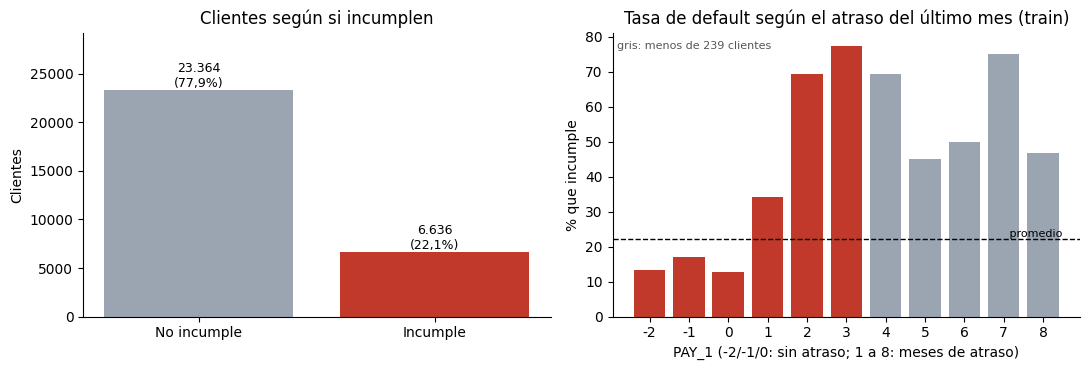

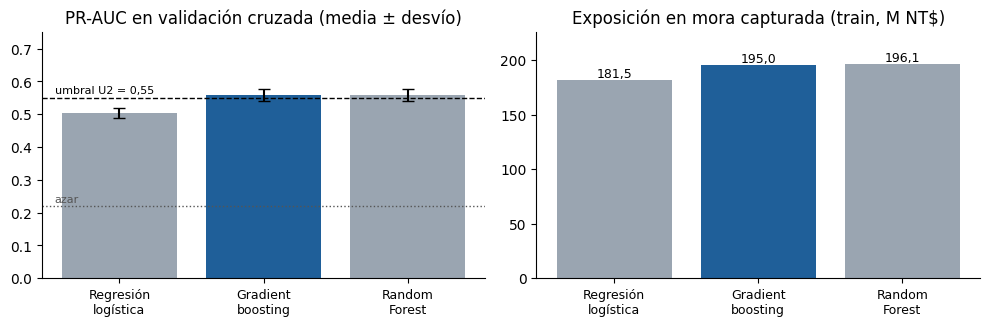

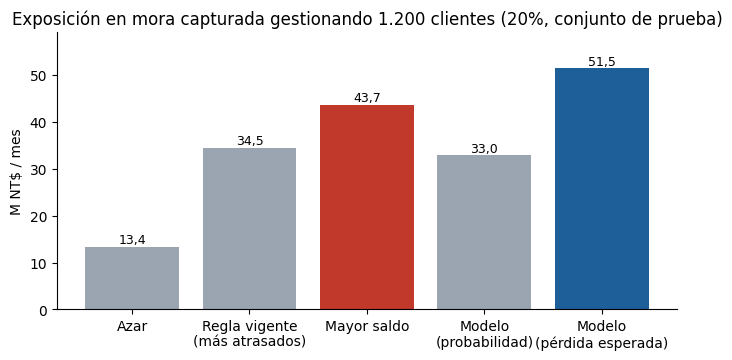

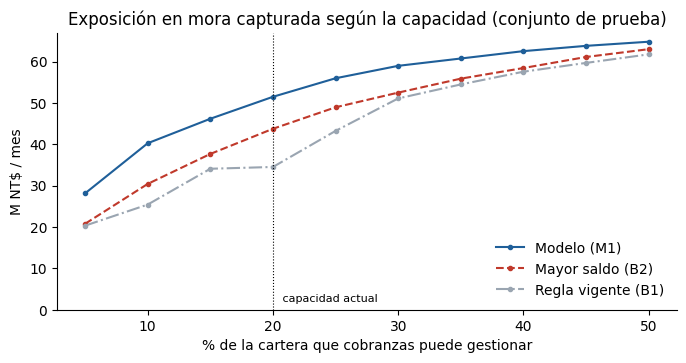

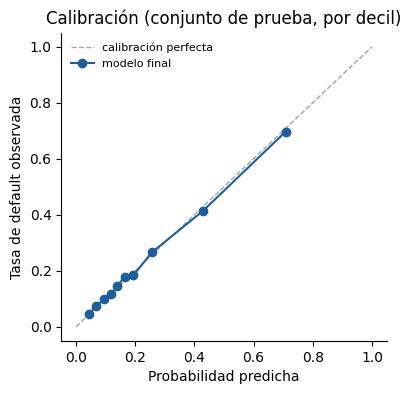

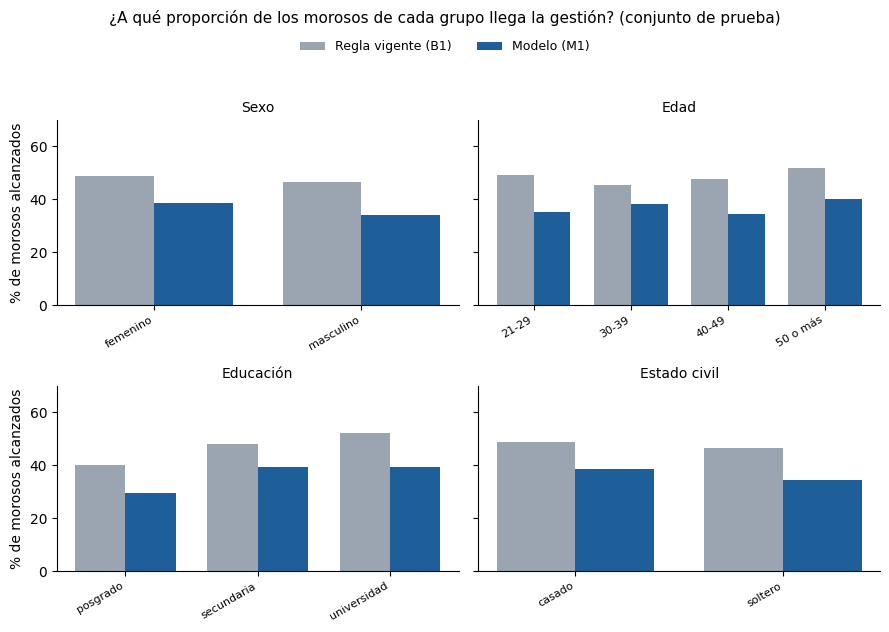

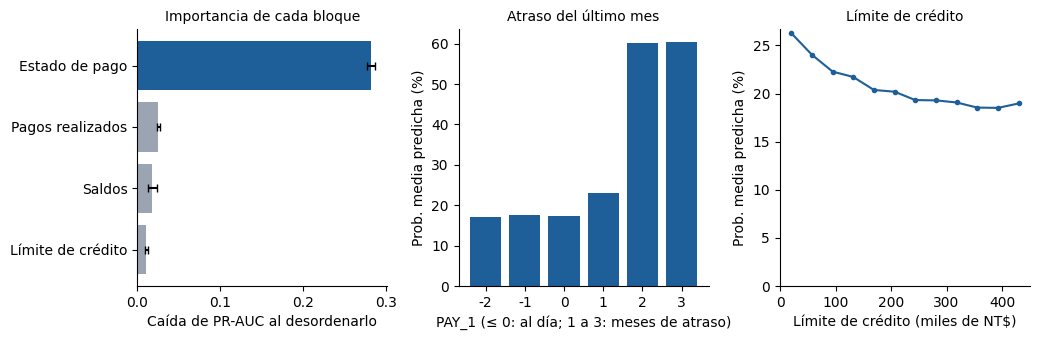

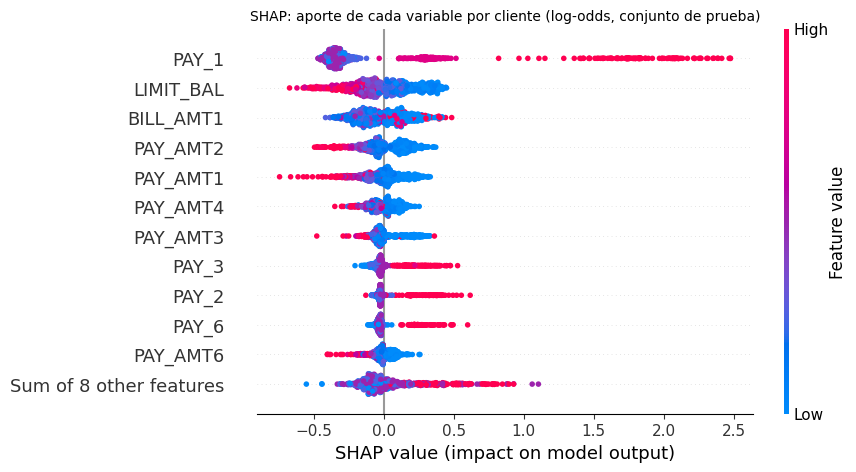

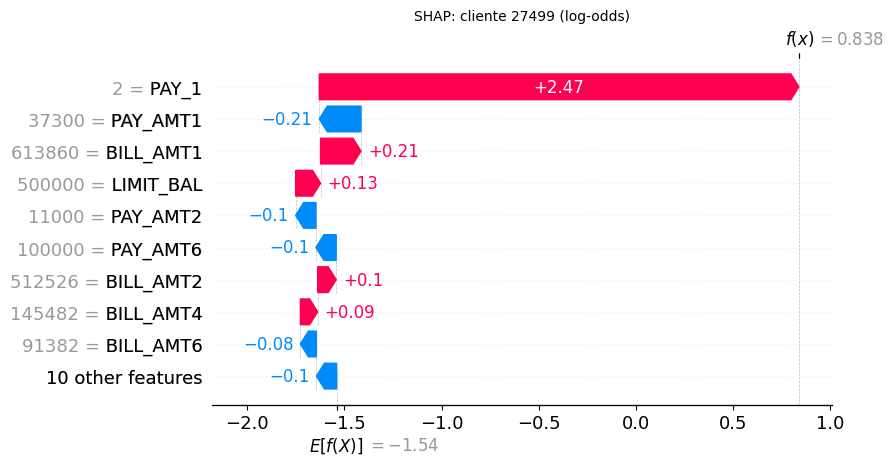

9 figuras guardadas en UTN-proyecto-final-integrador/figuras:
   fig1_eda.png
   fig2_algoritmos.png
   fig3_estrategias.png
   fig4_capacidad.png
   fig5_calibracion.png
   fig6_equidad.png
   fig7_interpretacion.png
   fig8_shap_resumen.png
   fig9_shap_caso_local.png


In [34]:
FIG_DIR = BASE / "figuras"
FIG_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.family": "sans-serif", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
C_MODELO, C_REGLA, C_GRIS = "#1f5f99", "#c0392b", "#9aa5b1"
FIGURAS = []

def _guardar(fig, nombre):
    ruta = FIG_DIR / f"{nombre}.png"
    fig.savefig(ruta, dpi=150, bbox_inches="tight")
    FIGURAS.append(ruta.name)
    plt.show()

def _millones(v):
    return f"{v / 1e6:,.1f}".replace(",", "X").replace(".", ",").replace("X", ".")

# Fig. 1 — Análisis exploratorio: desbalance de clases y tasa de mora según el estado de pago (entrenamiento).
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
_cnt = df_raw["default"].value_counts().sort_index()
ax[0].bar(["No incumple", "Incumple"], _cnt.values, color=[C_GRIS, C_REGLA])
for _i, _v in enumerate(_cnt.values):
    ax[0].text(_i, _v, f"{_v:,}".replace(",", ".") + f"\n({_v / _cnt.sum():.1%})".replace(".", ","),
               ha="center", va="bottom", fontsize=9)
ax[0].set_title("Clientes según si incumplen")
ax[0].set_ylim(0, _cnt.max() * 1.25); ax[0].set_ylabel("Clientes")
_tp1 = pd.DataFrame(RES["T_tasa_pay1"])
_col = [C_REGLA if n >= RES["min_soporte"] else C_GRIS for n in _tp1["n_train"]]
ax[1].bar(_tp1["PAY_1"].astype(str), 100 * _tp1["tasa_default"], color=_col)
ax[1].axhline(100 * RES["prev_train"], ls="--", c="k", lw=1)
ax[1].text(len(_tp1) - 0.5, 100 * RES["prev_train"], " promedio", va="bottom", ha="right", fontsize=8)
ax[1].set_title("Tasa de default según el atraso del último mes (train)")
ax[1].set_xlabel("PAY_1 (-2/-1/0: sin atraso; 1 a 8: meses de atraso)")
ax[1].set_ylabel("% que incumple")
ax[1].text(0.01, 0.97, f"gris: menos de {RES['min_soporte']} clientes", transform=ax[1].transAxes,
           fontsize=8, va="top", color="#555")
fig.tight_layout()
_guardar(fig, "fig1_eda")

# Fig. 2 — Comparación de algoritmos (validación cruzada): PR-AUC y exposición capturada.
_ta = T_algoritmos
_nom = [n.replace(" ", "\n", 1) for n in _ta["nombre"]]
_c = [C_MODELO if k == ALGORITMO else C_GRIS for k in _ta.index]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].bar(_nom, _ta["pr_auc_cv_media"], yerr=_ta["pr_auc_cv_std"], color=_c, capsize=4)
ax[0].axhline(0.55, ls="--", c="k", lw=1)
ax[0].text(-0.45, 0.565, "umbral U2 = 0,55", fontsize=8)
ax[0].axhline(RES["prev_train"], ls=":", c="#555", lw=1)
ax[0].text(-0.45, RES["prev_train"] + 0.01, "azar", fontsize=8, color="#555")
ax[0].set_ylim(0, 0.75); ax[0].set_title("PR-AUC en validación cruzada (media ± desvío)")
ax[1].bar(_nom, _ta["expo_M1_train_NTD"] / 1e6, color=_c)
for _i, _v in enumerate(_ta["expo_M1_train_NTD"]):
    ax[1].text(_i, _v / 1e6, _millones(_v), ha="center", va="bottom", fontsize=9)
ax[1].set_title("Exposición en mora capturada (train, M NT$)")
fig.tight_layout()
ax[1].set_ylim(0, _ta["expo_M1_train_NTD"].max() / 1e6 * 1.15)
for a in ax: a.tick_params(axis="x", labelsize=9)
_guardar(fig, "fig2_algoritmos")

# Fig. 3 — KPI primario por estrategia en el conjunto de prueba (Tabla 5).
_te = pd.DataFrame(RES["T_estrategias"])
_cod = [s.split(" ·")[0] for s in _te["estrategia"]]
_etiq = {"B0": "Azar", "B1": "Regla vigente\n(más atrasados)", "B2": "Mayor saldo",
         "M0": "Modelo\n(probabilidad)", "M1": "Modelo\n(pérdida esperada)"}
_col = [C_MODELO if c == _MODELO_GANADOR else C_REGLA if c == _REGLA_GANADORA else C_GRIS for c in _cod]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar([_etiq[c] for c in _cod], _te["exposicion_capturada_NTD"] / 1e6, color=_col)
for _i, _v in enumerate(_te["exposicion_capturada_NTD"]):
    ax.text(_i, _v / 1e6, _millones(_v), ha="center", va="bottom", fontsize=9)
ax.set_ylabel("M NT$ / mes")
ax.set_title(f"Exposición en mora capturada gestionando {K:,} clientes".replace(",", ".")
             + f" ({CONFIG['CAPACIDAD_OPERATIVA']:.0%}, conjunto de prueba)")
ax.set_ylim(0, _te["exposicion_capturada_NTD"].max() / 1e6 * 1.15)
_guardar(fig, "fig3_estrategias")

# Fig. 4 — Exposición capturada según la capacidad operativa (conjunto de prueba).
_caps = np.round(np.arange(0.05, 0.51, 0.05), 2)
fig, ax = plt.subplots(figsize=(8, 3.6))
for _k, _lab, _cc, _ls in [(_MODELO_GANADOR, f"Modelo ({_MODELO_GANADOR})", C_MODELO, "-"),
                           ("B2", "Mayor saldo (B2)", C_REGLA, "--"),
                           ("B1", "Regla vigente (B1)", C_GRIS, "-.")]:
    _vals = [expo[_top_k(_scores_ho[_k], int(round(c * len(yv)))) & (yv == 1)].sum() / 1e6 for c in _caps]
    ax.plot(100 * _caps, _vals, _ls, color=_cc, marker="o", ms=3, label=_lab)
ax.set_ylim(bottom=0)
ax.axvline(100 * CONFIG["CAPACIDAD_OPERATIVA"], c="k", lw=0.8, ls=":")
ax.text(100 * CONFIG["CAPACIDAD_OPERATIVA"] + 0.5, 2, " capacidad actual", fontsize=8)
ax.set_xlabel("% de la cartera que cobranzas puede gestionar"); ax.set_ylabel("M NT$ / mes")
ax.set_title("Exposición en mora capturada según la capacidad (conjunto de prueba)")
ax.legend(frameon=False, loc="lower right")
_guardar(fig, "fig4_capacidad")

# Fig. 5 — Calibración del modelo final en el conjunto de prueba.
_cc = RES["holdout"]["calibracion_curva"]
fig, ax = plt.subplots(figsize=(4.2, 4))
ax.plot([0, 1], [0, 1], ls="--", c=C_GRIS, lw=1, label="calibración perfecta")
ax.plot(_cc["prob_predicha_por_decil"], _cc["tasa_observada_por_decil"], "o-", color=C_MODELO,
        label="modelo final")
ax.set_xlabel("Probabilidad predicha"); ax.set_ylabel("Tasa de default observada")
ax.set_title("Calibración (conjunto de prueba, por decil)"); ax.legend(frameon=False, fontsize=8)
_guardar(fig, "fig5_calibracion")

# Fig. 6 — Equidad: recall por grupo, modelo final contra regla vigente (conjunto de prueba).
_atrs = [a for a in GRUPOS_EQUIDAD if (T_equidad[T_equidad.atributo == a].en_resumen).sum() >= 2]
_nc = 2 if len(_atrs) > 2 else len(_atrs)
_nf = int(np.ceil(len(_atrs) / _nc))
fig, axs = plt.subplots(_nf, _nc, figsize=(4.5 * _nc, 3.2 * _nf), sharey=True, squeeze=False)
axs = axs.ravel()
for a in axs[len(_atrs):]:
    a.set_visible(False)
for a, _atr in zip(axs, _atrs):
    _t = T_equidad[(T_equidad.atributo == _atr) & T_equidad.en_resumen]
    _x = np.arange(len(_t)); _w = 0.38
    a.bar(_x - _w / 2, 100 * _t["recall_B1"], _w, color=C_GRIS, label="Regla vigente (B1)")
    a.bar(_x + _w / 2, 100 * _t[f"recall_{_MODELO_GANADOR}"], _w, color=C_MODELO,
          label=f"Modelo ({_MODELO_GANADOR})")
    a.set_xticks(_x); a.set_xticklabels(_t["grupo"], rotation=30, ha="right", fontsize=8)
    a.set_title({"SEX": "Sexo", "AGE": "Edad", "EDUCATION": "Educación",
                 "MARRIAGE": "Estado civil"}[_atr], fontsize=10)
    a.set_ylim(0, 70)
for _j in range(0, len(_atrs), _nc):
    axs[_j].set_ylabel("% de morosos alcanzados")
fig.suptitle("¿A qué proporción de los morosos de cada grupo llega la gestión? (conjunto de prueba)", fontsize=11)
_h, _l = axs[0].get_legend_handles_labels()
fig.legend(_h, _l, loc="upper center", bbox_to_anchor=(0.5, 0.95), ncol=2, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.91))
_guardar(fig, "fig6_equidad")

# Fig. 7 — Interpretación: qué usa el modelo y cómo cambia el riesgo.
_tp = T_permutacion.sort_values("caida_pr_auc")
fig, ax = plt.subplots(1, 3, figsize=(10.5, 3.5))
ax[0].barh(_tp["bloque"], _tp["caida_pr_auc"], xerr=_tp["caida_pr_auc_std"],
           color=[C_MODELO if b == _top else C_GRIS for b in _tp["bloque"]], capsize=3)
ax[0].set_title("Importancia de cada bloque", fontsize=10)
ax[0].set_xlabel("Caída de PR-AUC al desordenarlo")
_dp = DEP_PARCIAL["PAY_1"]
_ok = [v in RES["codigos_con_soporte"] for v in _dp["valores"]]
ax[1].bar([str(int(v)) for v, o in zip(_dp["valores"], _ok) if o],
          [100 * p for p, o in zip(_dp["prob_media"], _ok) if o], color=C_MODELO)
ax[1].set_title("Atraso del último mes", fontsize=10)
ax[1].set_xlabel("PAY_1 (≤ 0: al día; 1 a 3: meses de atraso)")
ax[1].set_ylabel("Prob. media predicha (%)")
_dl = DEP_PARCIAL["LIMIT_BAL"]
ax[2].plot([v / 1000 for v in _dl["valores"]], [100 * p for p in _dl["prob_media"]], "o-", color=C_MODELO, ms=3)
ax[2].set_ylim(bottom=0)
ax[2].set_title("Límite de crédito", fontsize=10)
ax[2].set_xlabel("Límite de crédito (miles de NT$)")
ax[2].set_ylabel("Prob. media predicha (%)")
fig.tight_layout()
_guardar(fig, "fig7_interpretacion")



# Figs. 8 y 9 — SHAP (sólo si 7.6bis se pudo ejecutar).
if SHAP_EXP is not None:
    import shap
    plt.figure()
    shap.plots.beeswarm(SHAP_EXP, max_display=12, show=False)
    fig = plt.gcf(); fig.set_size_inches(8, 5)
    plt.title(f"SHAP: aporte de cada variable por cliente ({SHAP_ESCALA}, conjunto de prueba)", fontsize=10)
    _guardar(fig, "fig8_shap_resumen")
    plt.figure()
    shap.plots.waterfall(SHAP_EXP[SHAP_POS_LOCAL], max_display=10, show=False)
    fig = plt.gcf(); fig.set_size_inches(8, 4.5)
    plt.title(f"SHAP: cliente {CASO_LOCAL['id_cliente']} ({SHAP_ESCALA})", fontsize=10)
    _guardar(fig, "fig9_shap_caso_local")
else:
    print("SHAP no disponible: se omiten las figuras 8 y 9.")


RES["figuras"] = FIGURAS
print(f"{len(FIGURAS)} figuras guardadas en {FIG_DIR}:")
for f in FIGURAS:
    print("  ", f)

---

## Bloque 9 — Volcado de resultados

`resultados.json` es la fuente única de los números del informe final. Si este archivo cambia, el informe tiene que actualizarse.

In [35]:
def _conv(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    if isinstance(o, np.ndarray): return o.tolist()
    raise TypeError(f"Tipo no serializable en RES: {type(o).__name__}")

_salida = BASE / "resultados.json"
with open(_salida, "w", encoding="utf-8") as f:
    json.dump(RES, f, ensure_ascii=False, indent=2, default=_conv, allow_nan=False)

print(f"{_salida} escrito — {len(RES)} claves, {os.path.getsize(_salida):,} bytes")
print("\nClaves:", ", ".join(sorted(RES.keys())))

UTN-proyecto-final-integrador/resultados.json escrito — 102 claves, 58,137 bytes

Claves: H1, H3, H3_final, H4, H4_final, KPI, K_gestionados, T_categorias, T_controles, T_decision_cat, T_equidad, T_equidad_resumen, T_estrategias, T_limpieza_pendientes, T_limpieza_tomadas, T_mi, T_outliers, T_pay_codigos, T_sensibilidad, T_tasa_categorias, T_tasa_pay1, T_umbrales, T_verificacion, accuracy_clase_mayoritaria, algoritmo_final, anomalia_pay_neg, boot, codigos_con_soporte, codigos_pay_no_doc, comparacion_algoritmos, comparacion_algoritmos_holdout, config, corr_bill_por_lag, cv, cv_final, decision_calibrar, decision_variantes, decisiones_cat, diccionario_10, dup_grupos_partidos_split, dup_ids_distintos, dup_n_filas, dup_n_filas_montos_no_cero, dup_n_grupos, dup_pct_montos_cero, entorno, equidad_lectura, figuras, fuente, holdout, interpretacion, max_bill_amt1, max_sobre_p99_max, max_sobre_p99_min, max_sobre_p99_var, mi_pares_inestables, mi_top, min_soporte, n_celdas_fuera_diccionario, n_client

---

## Anexo — Registro de cambios

### Versiones anteriores

- **Bloques 0–1:** soporte para Colab, para que el notebook corra en más de un entorno.
- **Bloque 5.1:** error estándar corregido de la diferencia de dos proporciones (en vez de sólo la varianza de un grupo) para decidir si agrupar `EDUCATION`/`MARRIAGE`. Antes subestimaba la incertidumbre al decidir si agrupar.
- **Bloque 5.3:** `SEED = 42` no cambió; lo que se cambió es que el estimador de información mutua ahora se corre con 20 semillas distintas y se promedia.
  - `LIMIT_BAL` pasó de IM = 0,0111 (única corrida, semilla 42) a un promedio estable de 0,0172 en las 20 corridas: una diferencia grande, causada por el ruido de una sola medición y no por la variable en sí.
  - `PAY_AMT2` y `PAY_AMT3` tienen IM muy parecida, y cuál de las dos entraba en el top 10 dependía de la semilla: con la 42 entraba `PAY_AMT3`; promediando, entra `PAY_AMT2`.
  - Promediar sobre muchas semillas separa la señal real (que es estable) del ruido del estimador.
- **Bloque 6.2:** H1 incluye las 4 variables demográficas. Antes comparaba con sólo 3, subestimando la hipótesis rival.
- **Bloque 7:** IC del holdout + curva de calibración. Antes el resultado final se mostraba como un número seco, sin margen de error ni chequeo de si las probabilidades son confiables.

### Revisión v4: correcciones

Sólo errores; no cambia el planteo, el modelo ni las decisiones.

1. **Formato:** las celdas de texto habían perdido los saltos de línea (los títulos se comían el párrafo y las tablas no se renderizaban). Se reconstruyeron.
2. **Hash del dataset (1.1):** se calcula sobre el archivo de datos (`.xls`/`.csv`) y no sobre el `.zip`, para que sea el mismo en local y en Colab.
3. **Rango de outliers (2.3):** ahora se calcula sólo sobre las 12 variables de monto (antes incluía `LIMIT_BAL` y `AGE`).
4. **Registros fuera del diccionario (2.1):** se cuentan filas, no la suma de conteos por código.
5. **Mensajes fijos → condicionales:** 1.3, 2.1bis, 2.2, 5.2, 6.2, 7.2 y 7.2bis ya no afirman conclusiones que la salida podría contradecir.
6. **Estabilidad del ranking de IM (5.3):** el criterio usa el error estándar de la media de las 20 corridas, no el std de una corrida.
7. **5.1:** el intervalo se rotula como IC95 de la *diferencia* de tasas (la decisión es la misma).
8. **Calibración (7):** se agregan la brecha media y máxima por decil y se corrigió el comentario que afirmaba que estaba verificada.
9. **Duplicados (2.1bis, L9):** se señalan las filas con montos no nulos idénticos, que la explicación "cuentas inactivas" no cubre.
10. **Trazabilidad de umbrales (3.3):** se documenta que U0 no figuraba en la definición original y cómo se precisaron U4 y U5.
11. **Alcance del holdout (Bloque 7):** el texto ya no dice "una sola vez", porque M0/M1 y B1/B2 se eligen mirando ese mismo holdout.
12. **Limpieza de código:** `importlib.util` importado explícitamente, imports sin uso fuera, `b2` definida explícita, variables muertas fuera, filtro de warnings acotado y serialización JSON estricta.

### Esta revisión (v5): devolución del profesor sobre la pre-entrega

1. **Fuga entre train y holdout por duplicados (Bloque 4, L10):** el split ahora agrupa las filas por todas las columnas salvo `ID` antes de particionar, así un duplicado exacto (2.1bis) no puede quedar con una copia en train y la otra en holdout. Con la partición `SEED=42`, el split anterior (por fila) dejaba 7 grupos partidos; se aplica el mismo criterio en la repetición con 5 semillas (7.2bis).
2. **P7 redefinido:** el riesgo de fuga por split queda resuelto (L10). Lo que sigue pendiente es sólo de contenido: confirmar con negocio si las filas con montos no nulos idénticos son el mismo cliente.
3. **Capacidad operativa igual en las cinco estrategias:** ya estaba así (Bloque 7.1); no hubo cambios, se deja constancia porque el profesor lo pidió explícitamente.
4. **KPI en NT$ por delante de PR-AUC:** ya era el KPI primario (Bloque 3.1 y 7.2); no hubo cambios al notebook, sólo se reforzó en el documento (`v7.docx`).

### Esta revisión (v6): grilla de sensibilidad (7.3)

1. **Comparador corregido:** la grilla comparaba siempre M1 contra B1, aunque B2 sea la mejor regla en la Tabla 5. Ahora compara la variante de modelo y la regla YA GANADORAS (las mismas que fija 7.2bis-a), no un par fijo de antemano.
2. **Dimensión no tautológica agregada:** LGD y efectividad (S2, S3) multiplican por igual a las dos estrategias comparadas a igual capacidad, así que nunca podían cambiar el ganador, sólo la magnitud -- la grilla anterior sólo podía confirmarse a sí misma. Se agrega la capacidad operativa (S5, `GRID_CAPACIDAD`) como tercera dimensión, que sí selecciona clientes distintos en cada estrategia y por lo tanto sí puede cambiar el veredicto.

### Esta revisión (v7): calibración y selección de variantes sin tocar el holdout

1. **Nueva 7.0, antes de usar el holdout.** M0 vs. M1, B1 vs. B2 y si calibrar se decidían mirando el mismo holdout que después medía el resultado. Ahora se deciden con `cross_val_predict` sobre train (mismos 5 pliegues de 6.1, sin fuga) y el holdout queda para medir una sola vez, con todo ya decidido -- lo que el punto 2 de 3.2 ya prometía y el código todavía no cumplía.
2. **Calibración resuelta, no sólo declarada.** Se compara el ECE de las probabilidades OOF crudas contra una versión calibrada (`CalibratedClassifierCV`, isotónica, CV anidada) y se calibra sólo si de verdad mejora en train. La curva de calibración del holdout (7) queda como chequeo independiente de esa decisión, no como el criterio para tomarla.
3. **Selección unificada.** `construir_scores`/`evaluar_estrategia` (7.0) reemplazan la lógica duplicada que antes vivía sólo en 7.1: la cuenta que decide (train) y la que reporta (holdout) son ahora literalmente la misma función.
4. **Consistencia en 7.2bis:** la repetición con 5 semillas aplica la misma decisión de calibrar que 7.0, para no mezclar particiones calibradas con particiones sin calibrar.

### Revisión v9: entrega final

Pasa de baseline de pre-entrega a modelo final. La versión v8 no tenía entrada propia en este registro.

1. **Encabezado y mapa CRISP-DM:** el notebook ahora es el respaldo del informe final; se agrega la correspondencia de bloques con las fases de CRISP-DM. Este registro se movió al final, como anexo.
2. **6.3 nuevo, comparación de algoritmos:** logística, gradient boosting (`HistGradientBoostingClassifier`) y Random Forest, con las mismas variables, los mismos pliegues y sin tuneo. El criterio (exposición capturada en train OOF, con desempate por costo) se declara antes de correr. El ganador reemplaza a la logística en todo el Bloque 7 a través de `construir_final()` y `X_final()`; la logística queda como baseline en 6.1-6.2.
3. **6.3bis:** H3 (variables derivadas) y H4/U5 (exclusión de demográficas) se vuelven a medir con el algoritmo final. Se resuelven P1, P2, P3 y P5 según el algoritmo elegido.
4. **Umbrales (7.2):** U2 se mide sobre la CV del modelo final (`RES["cv_final"]`) y U5 sobre `RES["H4_final"]`, ya no sobre el baseline. Las columnas de `T_umbrales` pasan a ser `valor_modelo_final` y `alcanzado`.
5. **F1 @ capacidad:** se agrega a 3.1 y a todas las tablas de estrategias, con la aclaración de por qué no decide.
6. **7.1bis nuevo:** los tres algoritmos en el holdout, sólo informativo (la elección ya se hizo en 6.3).
7. **7.2bis-a:** los mensajes fijos sobre U0 y H2 pasan a ser condicionales: con el modelo final dejaban de ser ciertos.
8. **7.5 nuevo, auditoría de equidad:** tasa de selección y recall por `SEX`, edad, `EDUCATION` y `MARRIAGE`, contra la regla vigente, con IC bootstrap de la diferencia de brechas.
9. **7.6 nuevo, interpretación:** permutación agrupada por bloque (holdout), ablación por bloque (train, CV), dependencia parcial de `PAY_1`, `LIMIT_BAL` y `PAY_AMT1`, y un caso local. **7.6bis:** SHAP (`TreeExplainer` sobre el modelo sin calibrar) con control de aditividad, importancia por bloque y el mismo caso local descompuesto variable por variable; figuras 8 y 9. `shap` es opcional: si no se puede instalar, la sección se omite y el resto corre igual.
10. **Bloque 8 nuevo, figuras:** siete figuras para el informe, guardadas en `figuras/`. `matplotlib` pasa a ser dependencia (Bloque 0). El volcado pasa a ser el Bloque 9.

### Revisión final (octubre 2026)

Sin cambios en el código ni en los resultados.

- Comentarios del código reescritos con palabras más simples y sin referencias a versiones anteriores.
- `requirements.txt` con versiones exactas, porque con otra versión de scikit-learn las cifras cambian levemente.
- Notebook ejecutado completo con esas versiones: las salidas coinciden con el informe.